In [ ]:
!nvidia-smi

Sun Nov  8 16:03:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# Persistent storage for saved results.
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/xg-python")

# Local storage for faster data processing and training.
PROJECT_DIR = Path("/content/xg-python")

for directory in (DRIVE_PROJECT_DIR, PROJECT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Working directory: {PROJECT_DIR}")
print(f"Google Drive directory: {DRIVE_PROJECT_DIR}")

Mounted at /content/drive
Working directory: /content/xg-python
Google Drive directory: /content/drive/MyDrive/xg-python


In [ ]:
%pip install --quiet numpy pandas scipy scikit-learn "xgboost>=3,<4" pygam pyarrow matplotlib requests tqdm

from importlib.metadata import version

for package in ("numpy", "pandas", "scikit-learn", "xgboost", "pygam"):
    print(f"{package}: {version(package)}")

numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
xgboost: 3.4.1
pygam: 0.12.0


In [ ]:
import json

import numpy as np
import xgboost as xgb

test_rng = np.random.default_rng(42)
test_X = test_rng.standard_normal((4096, 8), dtype=np.float32)
test_y = (test_X[:, 0] + test_X[:, 1] > 0).astype(np.float32)

test_data = xgb.DMatrix(test_X, label=test_y)

test_model = xgb.train(
    params={
        "objective": "binary:logistic",
        "tree_method": "hist",
        "device": "cuda:0",
        "seed": 42,
    },
    dtrain=test_data,
    num_boost_round=10,
)

config = json.loads(test_model.save_config())
device = config["learner"]["generic_param"]["device"]

if not device.startswith("cuda"):
    raise RuntimeError(f"GPU test failed: XGBoost used {device}.")

print(f"XGBoost is using: {device}")

del test_model, test_data, test_X, test_y, test_rng, config

XGBoost is using: cuda:0


In [ ]:
import json

import pandas as pd
import requests

source_file = DRIVE_PROJECT_DIR / "data_source.json"

if source_file.exists():
    data_source = json.loads(source_file.read_text())
else:
    response = requests.get(
        "https://api.github.com/repos/hudl/open-data/commits/master",
        timeout=30,
    )
    response.raise_for_status()

    data_source = {
        "repository": "hudl/open-data",
        "commit": response.json()["sha"],
    }
    source_file.write_text(json.dumps(data_source, indent=2))

DATA_BASE_URL = (
    f"https://raw.githubusercontent.com/{data_source['repository']}/"
    f"{data_source['commit']}/data"
)

response = requests.get(f"{DATA_BASE_URL}/competitions.json", timeout=30)
response.raise_for_status()
competitions = pd.DataFrame(response.json())

selected_competitions = competitions.loc[
    competitions["season_name"].eq("2015/2016")
    & competitions["competition_id"].isin([2, 7, 9, 11, 12]),
    ["competition_id", "season_id", "country_name", "competition_name", "season_name"],
].sort_values("country_name").reset_index(drop=True)

if len(selected_competitions) != 5:
    raise ValueError("Expected all five leagues. Check the competition catalogue.")

display(selected_competitions)

,competition_id,season_id,country_name,competition_name,season_name
0,2,27,England,Premier League,2015/2016
1,7,27,France,Ligue 1,2015/2016
2,9,27,Germany,1. Bundesliga,2015/2016
3,12,27,Italy,Serie A,2015/2016
4,11,27,Spain,La Liga,2015/2016


In [ ]:
bundesliga = matches.loc[matches["competition_id"].eq(9)]

team_counts = (
    pd.concat(
        [bundesliga["home_team"], bundesliga["away_team"]],
        ignore_index=True,
    )
    .value_counts()
    .rename_axis("team")
    .reset_index(name="matches")
)

print(team_counts.to_string(index=False))

                    team  matches
        Bayer Leverkusen       34
             Hannover 96        2
           Bayern Munich        2
       Borussia Dortmund        2
           Werder Bremen        2
            Hamburger SV        2
               Wolfsburg        2
     Eintracht Frankfurt        2
           Hertha Berlin        2
              Ingolstadt        2
              Hoffenheim        2
            Darmstadt 98        2
            FSV Mainz 05        2
                Augsburg        2
           VfB Stuttgart        2
                 FC Köln        2
              Schalke 04        2
Borussia Mönchengladbach        2


In [ ]:
HISTORICAL_COMMIT = "3bfbffe1de5750ebd47d770be0bb924a10cde54f"

historical_base = (
    f"https://raw.githubusercontent.com/hudl/open-data/"
    f"{HISTORICAL_COMMIT}/data"
)

response = requests.get(
    f"{historical_base}/matches/9/27.json",
    timeout=60,
)
response.raise_for_status()

historical_matches = response.json()
match_ids = [match["match_id"] for match in historical_matches]

if len(match_ids) != 306 or len(set(match_ids)) != 306:
    raise ValueError("The historical Bundesliga list failed validation.")

data_source = {
    "repository": "hudl/open-data",
    "commit": HISTORICAL_COMMIT,
}
source_file.write_text(
    json.dumps(data_source, indent=2),
    encoding="utf-8",
)
DATA_BASE_URL = historical_base

print("Historical snapshot pinned: 306 Bundesliga matches verified.")

Historical snapshot pinned: 306 Bundesliga matches verified.


In [ ]:
match_frames = []

for competition in selected_competitions.itertuples(index=False):
    url = (
        f"{DATA_BASE_URL}/matches/"
        f"{competition.competition_id}/{competition.season_id}.json"
    )
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    frame = pd.json_normalize(response.json())[
        [
            "match_id",
            "match_date",
            "home_team.home_team_name",
            "away_team.away_team_name",
        ]
    ].rename(
        columns={
            "home_team.home_team_name": "home_team",
            "away_team.away_team_name": "away_team",
        }
    )

    frame["competition_id"] = competition.competition_id
    frame["season_id"] = competition.season_id
    frame["league"] = competition.competition_name
    match_frames.append(frame)

matches = pd.concat(match_frames, ignore_index=True)
matches["match_date"] = pd.to_datetime(matches["match_date"], errors="raise")

if matches["match_id"].duplicated().any():
    raise ValueError("Duplicate match IDs found.")

matches = matches.sort_values(
    ["match_date", "competition_id", "match_id"],
    ignore_index=True,
)

matches.to_parquet(DRIVE_PROJECT_DIR / "matches.parquet", index=False)

summary = matches.groupby("league", as_index=False).agg(
    matches=("match_id", "size"),
    first_match=("match_date", "min"),
    last_match=("match_date", "max"),
)

print(summary.to_string(index=False))
print(f"\nTotal matches: {len(matches):,}")

        league  matches first_match last_match
 1. Bundesliga      306  2015-08-14 2016-05-14
       La Liga      380  2015-08-21 2016-05-15
       Ligue 1      377  2015-08-07 2016-05-14
Premier League      380  2015-08-08 2016-05-17
       Serie A      380  2015-08-22 2016-05-15

Total matches: 1,823


In [ ]:
import numpy as np

TRAIN_END = pd.Timestamp("2016-02-28")
VALIDATION_END = pd.Timestamp("2016-04-10")

if matches["match_date"].isna().any():
    raise ValueError("Some matches have missing dates.")

matches = matches.copy()
matches["split"] = np.select(
    [
        matches["match_date"].le(TRAIN_END),
        matches["match_date"].le(VALIDATION_END),
    ],
    ["train", "validation"],
    default="test",
)

expected_counts = {"train": 1279, "validation": 271, "test": 273}
actual_counts = matches["split"].value_counts().to_dict()

if actual_counts != expected_counts:
    raise ValueError(f"Unexpected split counts: {actual_counts}")

split_summary = (
    matches.groupby("split")
    .agg(
        matches=("match_id", "size"),
        first_match=("match_date", "min"),
        last_match=("match_date", "max"),
    )
    .reindex(["train", "validation", "test"])
)

matches.to_parquet(PROJECT_DIR / "matches.parquet", index=False)
matches.to_parquet(DRIVE_PROJECT_DIR / "matches.parquet", index=False)

print(split_summary.to_string())

            matches first_match last_match
split                                     
train          1279  2015-08-07 2016-02-28
validation      271  2016-02-29 2016-04-10
test            273  2016-04-11 2016-05-17


In [ ]:
sample_match_id = int(
    matches.loc[matches["split"].eq("train"), "match_id"].iloc[0]
)

response = requests.get(
    f"{DATA_BASE_URL}/events/{sample_match_id}.json",
    timeout=60,
)
response.raise_for_status()
sample_events = response.json()

sample_shots = [
    event
    for event in sample_events
    if event.get("type", {}).get("name") == "Shot"
]

if not sample_shots:
    raise ValueError("The sample match contains no shot events.")

shots_with_freeze_frames = sum(
    bool(event["shot"].get("freeze_frame"))
    for event in sample_shots
)

print(f"Match ID: {sample_match_id}")
print(f"Events: {len(sample_events):,}")
print(f"Shots: {len(sample_shots)}")
print(f"Shots with freeze frames: {shots_with_freeze_frames}")
print("\nAvailable shot fields:")
print(", ".join(sorted(sample_shots[0]["shot"])))

Match ID: 3829413
Events: 3,351
Shots: 18
Shots with freeze frames: 18

Available shot fields:
body_part, end_location, first_time, freeze_frame, outcome, statsbomb_xg, technique, type


In [ ]:
import gzip

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

RAW_EVENTS_DIR = (
    PROJECT_DIR / "data" / "raw" / data_source["commit"] / "events"
)
RAW_EVENTS_DIR.mkdir(parents=True, exist_ok=True)


def create_http_session():
    session = requests.Session()
    retries = Retry(
        total=4,
        backoff_factor=1,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"],
        respect_retry_after_header=True,
    )
    session.mount("https://", HTTPAdapter(max_retries=retries))
    return session


def download_match_events(match_id, session):
    target = RAW_EVENTS_DIR / f"{int(match_id)}.json.gz"

    if target.exists():
        return target

    response = session.get(
        f"{DATA_BASE_URL}/events/{int(match_id)}.json",
        timeout=(15, 90),
    )
    response.raise_for_status()
    events = response.json()

    if not isinstance(events, list) or not events:
        raise ValueError(f"Invalid events for match {match_id}.")

    temporary = target.with_name(target.name + ".part")
    try:
        with gzip.open(
            temporary, "wt", encoding="utf-8", compresslevel=3
        ) as stream:
            json.dump(events, stream, ensure_ascii=False, separators=(",", ":"))

        temporary.replace(target)
    finally:
        temporary.unlink(missing_ok=True)

    return target


with create_http_session() as session:
    sample_path = download_match_events(sample_match_id, session)

print(f"Cached: {sample_path.name}")
print(f"Compressed size: {sample_path.stat().st_size / 1024:.1f} KiB")

Cached: 3829413.json.gz
Compressed size: 285.2 KiB


In [ ]:
import hashlib
import tarfile
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed

from tqdm.auto import tqdm

DOWNLOAD_BATCH_SIZE = 100
DRIVE_BATCH_DIR = (
    DRIVE_PROJECT_DIR
    / "data"
    / "raw"
    / data_source["commit"]
    / "event_batches"
)
DRIVE_BATCH_DIR.mkdir(parents=True, exist_ok=True)

download_worker_state = threading.local()


def download_event_worker(match_id):
    if not hasattr(download_worker_state, "session"):
        download_worker_state.session = create_http_session()

    return download_match_events(
        match_id,
        download_worker_state.session,
    )


def download_event_batch(batch_number):
    start = batch_number * DOWNLOAD_BATCH_SIZE
    match_ids = matches["match_id"].iloc[
        start : start + DOWNLOAD_BATCH_SIZE
    ].tolist()

    if not match_ids:
        raise ValueError("This batch contains no matches.")

    batch_key = hashlib.sha256(
        ",".join(map(str, match_ids)).encode()
    ).hexdigest()[:12]

    archive_path = DRIVE_BATCH_DIR / (
        f"events-{batch_number:03d}-{batch_key}.tar"
    )

    if archive_path.exists():
        expected_names = {f"{match_id}.json.gz" for match_id in match_ids}

        with tarfile.open(archive_path, "r") as archive:
            if set(archive.getnames()) != expected_names:
                raise ValueError(f"Unexpected archive contents: {archive_path.name}")

            archive.extractall(RAW_EVENTS_DIR, filter="data")

        print(f"Batch {batch_number + 1}: restored from Drive.")
        return

    with ThreadPoolExecutor(max_workers=4) as executor:
        futures = [
            executor.submit(download_event_worker, match_id)
            for match_id in match_ids
        ]

        for future in tqdm(
            as_completed(futures),
            total=len(futures),
            desc=f"Batch {batch_number + 1}",
        ):
            future.result()

    temporary = archive_path.with_name(archive_path.name + ".part")

    try:
        with tarfile.open(temporary, "w") as archive:
            for match_id in match_ids:
                path = RAW_EVENTS_DIR / f"{match_id}.json.gz"
                archive.add(path, arcname=path.name, recursive=False)

        temporary.replace(archive_path)
    finally:
        temporary.unlink(missing_ok=True)

    print(
        f"Batch {batch_number + 1}: "
        f"{len(match_ids)} matches backed up to Drive."
    )


download_event_batch(0)

Batch 1:   0%|          | 0/100 [00:00<?, ?it/s]

Batch 1: 100 matches backed up to Drive.


In [ ]:
total_batches = (
    len(matches) + DOWNLOAD_BATCH_SIZE - 1
) // DOWNLOAD_BATCH_SIZE

for batch_number in range(1, total_batches):
    download_event_batch(batch_number)

missing_ids = [
    int(match_id)
    for match_id in matches["match_id"]
    if not (RAW_EVENTS_DIR / f"{match_id}.json.gz").is_file()
]

if missing_ids:
    raise RuntimeError(f"Missing event files: {missing_ids[:10]}")

print(f"\nReady: {len(matches):,} match-event files.")
print("All download batches are backed up to Google Drive.")

Batch 2:   0%|          | 0/100 [00:00<?, ?it/s]

Batch 2: 100 matches backed up to Drive.


Batch 3:   0%|          | 0/100 [00:00<?, ?it/s]

Batch 3: 100 matches backed up to Drive.


Batch 4:   0%|          | 0/100 [00:00<?, ?it/s]

Batch 4: 100 matches backed up to Drive.


... (26 outputs left out)

Batch 18:   0%|          | 0/100 [00:00<?, ?it/s]

Batch 18: 100 matches backed up to Drive.


Batch 19:   0%|          | 0/23 [00:00<?, ?it/s]

Batch 19: 23 matches backed up to Drive.

Ready: 1,823 match-event files.
All download batches are backed up to Google Drive.


In [ ]:
SHOT_FLAGS = (
    "first_time",
    "one_on_one",
    "open_goal",
    "aerial_won",
    "follows_dribble",
)


def extract_match_shots(match):
    path = RAW_EVENTS_DIR / f"{match.match_id}.json.gz"

    with gzip.open(path, "rt", encoding="utf-8") as stream:
        events = json.load(stream)

    records = []

    for event in events:
        if event.get("type", {}).get("name") != "Shot":
            continue

        shot = event["shot"]
        shot_type = shot["type"]["name"]
        shot_x, shot_y = event["location"][:2]
        freeze_frame = shot.get("freeze_frame")

        record = {
            "shot_id": event["id"],
            "match_id": int(match.match_id),
            "competition_id": int(match.competition_id),
            "league": match.league,
            "match_date": match.match_date,
            "split": match.split,
            "event_index": event["index"],
            "period": event["period"],
            "minute": event["minute"],
            "second": event["second"],
            "timestamp": event["timestamp"],
            "possession": event["possession"],
            "team_id": event["team"]["id"],
            "player_id": event.get("player", {}).get("id"),
            "play_pattern": event.get("play_pattern", {}).get("name"),
            "shot_x": float(shot_x),
            "shot_y": float(shot_y),
            "shot_type": shot_type,
            "body_part": shot["body_part"]["name"],
            "technique": shot["technique"]["name"],
            "under_pressure": bool(event.get("under_pressure", False)),
            "key_pass_id": shot.get("key_pass_id"),
            "freeze_frame_available": freeze_frame is not None,
            "freeze_frame_json": (
                json.dumps(freeze_frame, ensure_ascii=False, separators=(",", ":"))
                if freeze_frame is not None
                else None
            ),
            "benchmark_statsbomb_xg": shot.get("statsbomb_xg"),
            "is_goal": shot["outcome"]["name"] == "Goal",
            "eligible": shot_type != "Penalty",
        }

        record.update({
            flag: bool(shot.get(flag, False))
            for flag in SHOT_FLAGS
        })
        records.append(record)

    return pd.DataFrame.from_records(records)


sample_match = next(matches.itertuples(index=False))
sample_shot_table = extract_match_shots(sample_match)

print(f"Extracted shots: {len(sample_shot_table)}")
print(f"Eligible shots: {sample_shot_table['eligible'].sum()}")
print(
    sample_shot_table[
        ["shot_x", "shot_y", "shot_type", "body_part", "is_goal", "eligible"]
    ].head().to_string(index=False)
)

Extracted shots: 18
Eligible shots: 18
 shot_x  shot_y shot_type  body_part  is_goal  eligible
  104.0    46.5 Open Play Right Foot    False      True
  105.8    47.6 Open Play Right Foot    False      True
   91.9    39.5 Open Play Right Foot    False      True
  111.5    47.7 Open Play       Head    False      True
  111.2    26.4 Open Play Right Foot    False      True


In [ ]:
import shutil

shot_tables = [
    extract_match_shots(match)
    for match in tqdm(
        matches.itertuples(index=False),
        total=len(matches),
        desc="Extracting shots",
    )
]

shots = pd.concat(shot_tables, ignore_index=True)
del shot_tables

if shots["shot_id"].isna().any() or shots["shot_id"].duplicated().any():
    raise ValueError("Missing or duplicate shot IDs found.")

if not np.isfinite(shots[["shot_x", "shot_y"]].to_numpy()).all():
    raise ValueError("Invalid shot coordinates found.")

shots = shots.sort_values(
    ["match_date", "competition_id", "match_id", "event_index"],
    ignore_index=True,
)

shot_summary = (
    shots.groupby("split")
    .agg(
        shots=("shot_id", "size"),
        eligible_shots=("eligible", "sum"),
    )
    .reindex(["train", "validation", "test"])
)

expected_counts = np.array([
    [32149, 31810],
    [6622, 6555],
    [6948, 6868],
])

if not np.array_equal(shot_summary.to_numpy(), expected_counts):
    raise ValueError(f"Unexpected shot counts:\n{shot_summary}")

PROCESSED_DIR = (
    PROJECT_DIR / "data" / "processed" / data_source["commit"]
)
DRIVE_PROCESSED_DIR = (
    DRIVE_PROJECT_DIR / "data" / "processed" / data_source["commit"]
)

for directory in (PROCESSED_DIR, DRIVE_PROCESSED_DIR):
    directory.mkdir(parents=True, exist_ok=True)

local_path = PROCESSED_DIR / "shots.parquet"
shots.to_parquet(local_path, index=False, compression="zstd")

drive_temporary = DRIVE_PROCESSED_DIR / "shots.parquet.part"
shutil.copy2(local_path, drive_temporary)
drive_temporary.replace(DRIVE_PROCESSED_DIR / "shots.parquet")

print(shot_summary.to_string())
print(f"\nTotal shots: {len(shots):,}")
print(f"Eligible shots: {shots['eligible'].sum():,}")
print("Shot table saved locally and backed up to Drive.")

Extracting shots:   0%|          | 0/1823 [00:00<?, ?it/s]

            shots  eligible_shots
split                            
train       32149           31810
validation   6622            6555
test         6948            6868

Total shots: 45,719
Eligible shots: 45,233
Shot table saved locally and backed up to Drive.


In [ ]:
shots.head()

,shot_id,match_id,competition_id,league,match_date,split,event_index,period,minute,second,...,freeze_frame_available,freeze_frame_json,benchmark_statsbomb_xg,is_goal,eligible,first_time,one_on_one,open_goal,aerial_won,follows_dribble
0,987185d7-aff3-41e2-af60-4ba6c764f7cf,3829413,7,Ligue 1,2015-08-07,train,111,1,1,38,...,True,"[{""location"":[104.6,58.5],""player"":{""id"":3481,...",0.073709,False,True,True,False,False,False,False
1,6ee660c2-6e67-4dc6-bfec-aeba5c5e535f,3829413,7,Ligue 1,2015-08-07,train,404,1,8,21,...,True,"[{""location"":[119.3,57.1],""player"":{""id"":3625,...",0.077398,False,True,True,False,False,False,False
2,3d59c346-3562-4d7d-8413-678145bd80ba,3829413,7,Ligue 1,2015-08-07,train,408,1,8,23,...,True,"[{""location"":[118.6,56.2],""player"":{""id"":3625,...",0.017888,False,True,True,False,False,False,False
3,7f24a24b-09aa-4d00-96eb-392735457e67,3829413,7,Ligue 1,2015-08-07,train,674,1,14,24,...,True,"[{""location"":[117.9,62.9],""player"":{""id"":29057...",0.049162,False,True,False,False,False,True,False
4,179d4a93-e8a2-481c-95bc-0e825835568f,3829413,7,Ligue 1,2015-08-07,train,815,1,16,36,...,True,"[{""location"":[102.0,30.1],""player"":{""id"":6716,...",0.063648,False,True,False,False,False,False,False


In [ ]:
GEOMETRY_FEATURES = [
    "distance_to_goal",
    "angle_to_goal",
    "absolute_lateral_distance",
    "shot_side",
    "inside_penalty_area",
    "inside_six_yard_box",
]


def add_shot_geometry(table):
    result = table.copy()

    x = result["shot_x"].to_numpy(dtype=float)
    y = result["shot_y"].to_numpy(dtype=float)

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x >= 0) & (x <= 120)
        & (y >= 0) & (y <= 80)
    )

    depth = 120.0 - x
    lateral = y - 40.0

    # Angle between the vectors from the shot to the two goalposts.
    angle = np.arctan2(
        8.0 * depth,
        depth**2 + lateral**2 - 16.0,
    )

    # The angle is undefined exactly at either goalpost.
    angle[(depth == 0) & ((y == 36) | (y == 44))] = np.nan

    result["distance_to_goal"] = np.where(
        valid, np.hypot(depth, lateral), np.nan
    )
    result["angle_to_goal"] = np.where(valid, angle, np.nan)
    result["absolute_lateral_distance"] = np.where(
        valid, np.abs(lateral), np.nan
    )

    result["shot_side"] = pd.Series(
        np.select(
            [y < 40, y > 40],
            ["left", "right"],
            default="center",
        ),
        index=result.index,
    ).where(valid)

    result["inside_penalty_area"] = np.where(
        valid,
        (x >= 102) & (y >= 18) & (y <= 62),
        np.nan,
    )
    result["inside_six_yard_box"] = np.where(
        valid,
        (x >= 114) & (y >= 30) & (y <= 50),
        np.nan,
    )

    result["geometry_location_valid"] = valid
    return result


model_data = add_shot_geometry(shots.loc[shots["eligible"]])

print(f"Modeling rows: {len(model_data):,}")
print(
    "Locations outside pitch bounds:",
    int((~model_data["geometry_location_valid"]).sum()),
)
print(
    model_data[
        ["shot_x", "shot_y", "distance_to_goal", "angle_to_goal"]
    ].head().round(4).to_string(index=False)
)


Modeling rows: 45,233
Locations outside pitch bounds: 3
 shot_x  shot_y  distance_to_goal  angle_to_goal
  104.0    46.5           17.2699         0.4258
  105.8    47.6           16.1059         0.4367
   91.9    39.5           28.1044         0.2827
  111.5    47.7           11.4691         0.5320
  111.2    26.4           16.1988         0.2783


In [ ]:
SHOT_CONTEXT_FEATURES = [
    "shot_type",
    "body_part",
    "technique",
    "play_pattern",
    "under_pressure",
    *SHOT_FLAGS,
]

missing_columns = sorted(
    set(SHOT_CONTEXT_FEATURES) - set(model_data.columns)
)
if missing_columns:
    raise ValueError(f"Missing context columns: {missing_columns}")

# This registry will define our cumulative feature-group comparisons.
FEATURE_GROUPS = {
    "01_shot_geometry": GEOMETRY_FEATURES,
    "02_shot_and_event_context": SHOT_CONTEXT_FEATURES,
}

training_context = model_data.loc[
    model_data["split"].eq("train"),
    SHOT_CONTEXT_FEATURES,
]

context_summary = pd.DataFrame({
    "dtype": training_context.dtypes.astype(str),
    "missing_rows": training_context.isna().sum(),
    "distinct_values": training_context.nunique(),
})

print(context_summary.to_string())
print(f"\nRegistered feature groups: {len(FEATURE_GROUPS)}")


                  dtype  missing_rows  distinct_values
shot_type        object             0                3
body_part        object             0                4
technique        object             0                7
play_pattern     object             0                9
under_pressure     bool             0                2
first_time         bool             0                2
one_on_one         bool             0                2
open_goal          bool             0                2
aerial_won         bool             0                2
follows_dribble    bool             0                2

Registered feature groups: 2


In [ ]:
freeze_frames_by_shot = {
    row.shot_id: (
        json.loads(row.freeze_frame_json)
        if isinstance(row.freeze_frame_json, str)
        else None
    )
    for row in tqdm(
        model_data[["shot_id", "freeze_frame_json"]].itertuples(index=False),
        total=len(model_data),
        desc="Decoding freeze frames",
    )
}


def find_opponent_goalkeepers(frame):
    if frame is None:
        return None

    return [
        player
        for player in frame
        if player.get("teammate") is False
        and (player.get("position") or {}).get("id") == 1
    ]


opponent_goalkeepers_by_shot = {
    shot_id: find_opponent_goalkeepers(frame)
    for shot_id, frame in freeze_frames_by_shot.items()
}

training_shot_ids = model_data.loc[
    model_data["split"].eq("train"), "shot_id"
]

goalkeeper_counts = training_shot_ids.map(
    lambda shot_id: (
        len(opponent_goalkeepers_by_shot[shot_id])
        if opponent_goalkeepers_by_shot[shot_id] is not None
        else None
    )
).astype("Int64")

print(
    goalkeeper_counts.value_counts(dropna=False)
    .sort_index()
    .rename_axis("visible_opponent_goalkeepers")
    .to_frame("training_shots")
    .to_string()
)

Decoding freeze frames:   0%|          | 0/45233 [00:00<?, ?it/s]

                              training_shots
visible_opponent_goalkeepers                
0                                         28
1                                      31782


In [ ]:

GOALKEEPER_FEATURES = [
    "goalkeeper_visible",
    "goalkeeper_depth",
    "goalkeeper_lateral_offset",
    "goalkeeper_distance_to_goal",
    "goalkeeper_distance_to_shot",
    "goalkeeper_line_offset",
]


def goalkeeper_record(keepers):
    visible = np.nan if keepers is None else float(bool(keepers))

    if keepers is None or len(keepers) != 1:
        return visible, np.nan, np.nan

    location = keepers[0].get("location")
    if not isinstance(location, list) or len(location) != 2:
        return visible, np.nan, np.nan

    x, y = np.asarray(location, dtype=float)
    if not np.isfinite([x, y]).all():
        return visible, np.nan, np.nan

    return visible, x, y


def add_goalkeeper_features(table, keeper_lookup):
    result = table.copy()

    values = np.asarray([
        goalkeeper_record(keeper_lookup[shot_id])
        for shot_id in result["shot_id"]
    ], dtype=float).reshape(-1, 3)

    result[
        ["goalkeeper_visible", "goalkeeper_x", "goalkeeper_y"]
    ] = values

    gk_x, gk_y = values[:, 1], values[:, 2]
    shot_x = result["shot_x"].to_numpy(dtype=float)
    shot_y = result["shot_y"].to_numpy(dtype=float)
    valid_shot = result["geometry_location_valid"].to_numpy(dtype=bool)

    goal_dx = 120.0 - shot_x
    goal_dy = 40.0 - shot_y
    keeper_dx = gk_x - shot_x
    keeper_dy = gk_y - shot_y

    result["goalkeeper_depth"] = 120.0 - gk_x
    result["goalkeeper_lateral_offset"] = np.abs(gk_y - 40.0)
    result["goalkeeper_distance_to_goal"] = np.hypot(
        120.0 - gk_x, 40.0 - gk_y
    )
    result["goalkeeper_distance_to_shot"] = np.where(
        valid_shot,
        np.hypot(keeper_dx, keeper_dy),
        np.nan,
    )

    distance = result["distance_to_goal"].to_numpy(dtype=float)
    cross_product = np.abs(
        goal_dx * keeper_dy - goal_dy * keeper_dx
    )

    result["goalkeeper_line_offset"] = np.divide(
        cross_product,
        distance,
        out=np.full(len(result), np.nan),
        where=(
            valid_shot
            & np.isfinite(gk_x)
            & np.isfinite(gk_y)
            & (distance > 0)
        ),
    )

    return result


model_data = add_goalkeeper_features(
    model_data,
    opponent_goalkeepers_by_shot,
)

FEATURE_GROUPS["03_goalkeeper_positioning"] = GOALKEEPER_FEATURES

print(
    model_data.loc[
        model_data["split"].eq("train"), GOALKEEPER_FEATURES
    ]
    .agg(["count", "min", "max"])
    .T.round(3)
    .to_string()
)

                               count  min     max
goalkeeper_visible           31810.0  0.0   1.000
goalkeeper_depth             31782.0  0.0  61.800
goalkeeper_lateral_offset    31782.0  0.0  28.600
goalkeeper_distance_to_goal  31782.0  0.1  62.954
goalkeeper_distance_to_shot  31779.0  0.4  74.031
goalkeeper_line_offset       31779.0  0.0  25.848


In [23]:
def opponent_outfield_locations(frame):
    if frame is None:
        return None

    locations = []

    for player in frame:
        position_id = (player.get("position") or {}).get("id")

        if player.get("teammate") is not False:
            continue

        # Exclude goalkeepers and players with an unknown position.
        if position_id in (None, 1):
            continue

        location = player.get("location")
        if not isinstance(location, list) or len(location) != 2:
            continue

        point = np.asarray(location, dtype=float)
        if np.isfinite(point).all():
            locations.append(point)

    return np.asarray(locations, dtype=float).reshape(-1, 2)


opponent_locations_by_shot = {
    shot_id: opponent_outfield_locations(frame)
    for shot_id, frame in freeze_frames_by_shot.items()
}

outfield_counts = training_shot_ids.map(
    lambda shot_id: (
        len(opponent_locations_by_shot[shot_id])
        if opponent_locations_by_shot[shot_id] is not None
        else None
    )
).astype("Int64")

print(
    outfield_counts.value_counts(dropna=False)
    .sort_index()
    .rename_axis("visible_outfield_opponents")
    .to_frame("training_shots")
    .to_string()
)

                            training_shots
visible_outfield_opponents                
0                                        1
1                                       29
2                                      237
3                                      679
4                                     1259
5                                     2195
6                                     3991
7                                     5982
8                                     6606
9                                     5814
10                                    5017


In [24]:
PRESSURE_RADII = (1.0, 2.0, 3.0, 5.0)

PRESSURE_FEATURES = [
    "nearest_visible_defender_distance",
    "second_nearest_visible_defender_distance",
    *[
        f"visible_defenders_within_{radius:g}"
        for radius in PRESSURE_RADII
    ],
]


def pressure_record(shot, opponent_lookup):
    locations = opponent_lookup[shot.shot_id]

    if locations is None or not shot.geometry_location_valid:
        return [np.nan] * len(PRESSURE_FEATURES)

    distances = np.sort(
        np.hypot(
            locations[:, 0] - shot.shot_x,
            locations[:, 1] - shot.shot_y,
        )
    )

    nearest = distances[0] if distances.size >= 1 else np.nan
    second_nearest = distances[1] if distances.size >= 2 else np.nan

    counts = [
        np.count_nonzero(distances <= radius + 1e-9)
        for radius in PRESSURE_RADII
    ]

    return [nearest, second_nearest, *counts]


def add_pressure_features(table, opponent_lookup):
    result = table.copy()

    columns = [
        "shot_id",
        "shot_x",
        "shot_y",
        "geometry_location_valid",
    ]

    records = [
        pressure_record(shot, opponent_lookup)
        for shot in result[columns].itertuples(index=False)
    ]

    result[PRESSURE_FEATURES] = np.asarray(
        records, dtype=float
    ).reshape(-1, len(PRESSURE_FEATURES))

    return result


model_data = add_pressure_features(
    model_data,
    opponent_locations_by_shot,
)

FEATURE_GROUPS["04_defensive_pressure"] = PRESSURE_FEATURES

print(
    model_data.loc[
        model_data["split"].eq("train"), PRESSURE_FEATURES
    ]
    .agg(["count", "min", "max"])
    .T.round(3)
    .to_string()
)

                                            count    min     max
nearest_visible_defender_distance         31806.0  0.000  32.650
second_nearest_visible_defender_distance  31777.0  0.283  35.263
visible_defenders_within_1                31807.0  0.000   3.000
visible_defenders_within_2                31807.0  0.000   4.000
visible_defenders_within_3                31807.0  0.000   6.000
visible_defenders_within_5                31807.0  0.000   8.000


In [25]:
OBSTRUCTION_FEATURES = [
    "visible_defenders_in_shot_cone",
    "nearest_visible_blocker_distance",
    "visible_defenders_near_shot_line",
    "nearest_visible_defender_line_offset",
]


def obstruction_record(shot, opponent_lookup):
    locations = opponent_lookup[shot.shot_id]
    depth = 120.0 - shot.shot_x

    # A triangle with zero depth is degenerate.
    if (
        locations is None
        or not shot.geometry_location_valid
        or depth <= 1e-9
    ):
        return [np.nan] * len(OBSTRUCTION_FEATURES)

    tolerance = 1e-9
    dx = locations[:, 0] - shot.shot_x
    dy = locations[:, 1] - shot.shot_y

    # Triangle boundaries at each defender's x coordinate.
    fraction = dx / depth
    lower_y = shot.shot_y + fraction * (36.0 - shot.shot_y)
    upper_y = shot.shot_y + fraction * (44.0 - shot.shot_y)

    in_cone = (
        (fraction >= -tolerance)
        & (fraction <= 1.0 + tolerance)
        & (locations[:, 1] >= lower_y - tolerance)
        & (locations[:, 1] <= upper_y + tolerance)
    )

    distances = np.hypot(dx, dy)
    nearest_blocker = (
        distances[in_cone].min() if in_cone.any() else np.nan
    )

    # Position relative to the segment from shot to goal center.
    goal_dy = 40.0 - shot.shot_y
    segment_length_squared = depth**2 + goal_dy**2

    projection = (dx * depth + dy * goal_dy) / segment_length_squared
    line_offset = np.abs(
        depth * dy - goal_dy * dx
    ) / np.sqrt(segment_length_squared)

    along_segment = (
        (projection >= -tolerance)
        & (projection <= 1.0 + tolerance)
    )
    near_line = along_segment & (line_offset <= 1.0 + tolerance)

    nearest_line_offset = (
        line_offset[along_segment].min()
        if along_segment.any()
        else np.nan
    )

    return [
        np.count_nonzero(in_cone),
        nearest_blocker,
        np.count_nonzero(near_line),
        nearest_line_offset,
    ]


def add_obstruction_features(table, opponent_lookup):
    result = table.copy()

    columns = [
        "shot_id", "shot_x", "shot_y", "geometry_location_valid"
    ]
    records = [
        obstruction_record(shot, opponent_lookup)
        for shot in result[columns].itertuples(index=False)
    ]

    result[OBSTRUCTION_FEATURES] = np.asarray(
        records, dtype=float
    ).reshape(-1, len(OBSTRUCTION_FEATURES))

    return result


model_data = add_obstruction_features(
    model_data,
    opponent_locations_by_shot,
)

FEATURE_GROUPS["05_shot_obstruction"] = OBSTRUCTION_FEATURES

print(
    model_data.loc[
        model_data["split"].eq("train"), OBSTRUCTION_FEATURES
    ]
    .agg(["count", "min", "max"])
    .T.round(3)
    .to_string()
)

                                        count  min     max
visible_defenders_in_shot_cone        31804.0  0.0   8.000
nearest_visible_blocker_distance      16340.0  0.0  45.149
visible_defenders_near_shot_line      31804.0  0.0   6.000
nearest_visible_defender_line_offset  31111.0  0.0  31.885


In [26]:
def supporting_teammate_locations(frame, shooter_id):
    if frame is None:
        return None

    locations = []

    for player in frame:
        if player.get("teammate") is not True:
            continue

        player_id = (player.get("player") or {}).get("id")
        if pd.notna(shooter_id) and player_id == shooter_id:
            continue

        position_id = (player.get("position") or {}).get("id")
        if position_id in (None, 1):
            continue

        location = player.get("location")
        if not isinstance(location, list) or len(location) != 2:
            continue

        point = np.asarray(location, dtype=float)
        if np.isfinite(point).all():
            locations.append(point)

    return np.asarray(locations, dtype=float).reshape(-1, 2)


teammate_locations_by_shot = {
    row.shot_id: supporting_teammate_locations(
        freeze_frames_by_shot[row.shot_id],
        row.player_id,
    )
    for row in model_data[
        ["shot_id", "player_id"]
    ].itertuples(index=False)
}

support_counts = training_shot_ids.map(
    lambda shot_id: (
        len(teammate_locations_by_shot[shot_id])
        if teammate_locations_by_shot[shot_id] is not None
        else None
    )
).astype("Int64")

print(
    support_counts.value_counts(dropna=False)
    .sort_index()
    .rename_axis("visible_supporting_teammates")
    .to_frame("training_shots")
    .to_string()
)


                              training_shots
visible_supporting_teammates                
0                                        339
1                                       1277
2                                       3112
3                                       5352
4                                       6457
5                                       6126
6                                       4745
7                                       3057
8                                       1162
9                                        183


In [27]:
SUPPORT_RADII = (5.0, 10.0, 15.0)

SUPPORT_FEATURES = [
    "nearest_visible_teammate_distance",
    *[
        f"visible_teammates_within_{radius:g}"
        for radius in SUPPORT_RADII
    ],
    *[
        f"local_attacking_share_within_{radius:g}"
        for radius in SUPPORT_RADII
    ],
]


def support_record(shot, teammate_lookup, opponent_lookup):
    teammates = teammate_lookup[shot.shot_id]
    opponents = opponent_lookup[shot.shot_id]

    if (
        teammates is None
        or opponents is None
        or not shot.geometry_location_valid
    ):
        return [np.nan] * len(SUPPORT_FEATURES)

    teammate_distances = np.hypot(
        teammates[:, 0] - shot.shot_x,
        teammates[:, 1] - shot.shot_y,
    )
    opponent_distances = np.hypot(
        opponents[:, 0] - shot.shot_x,
        opponents[:, 1] - shot.shot_y,
    )

    nearest_teammate = (
        teammate_distances.min()
        if teammate_distances.size
        else np.nan
    )

    teammate_counts = np.array([
        np.count_nonzero(teammate_distances <= radius + 1e-9)
        for radius in SUPPORT_RADII
    ], dtype=float)

    opponent_counts = np.array([
        np.count_nonzero(opponent_distances <= radius + 1e-9)
        for radius in SUPPORT_RADII
    ], dtype=float)

    attacking_shares = (
        (1.0 + teammate_counts)
        / (1.0 + teammate_counts + opponent_counts)
    )

    return [nearest_teammate, *teammate_counts, *attacking_shares]


def add_support_features(table, teammate_lookup, opponent_lookup):
    result = table.copy()

    columns = [
        "shot_id", "shot_x", "shot_y", "geometry_location_valid"
    ]
    records = [
        support_record(shot, teammate_lookup, opponent_lookup)
        for shot in result[columns].itertuples(index=False)
    ]

    result[SUPPORT_FEATURES] = np.asarray(
        records, dtype=float
    ).reshape(-1, len(SUPPORT_FEATURES))

    return result


model_data = add_support_features(
    model_data,
    teammate_locations_by_shot,
    opponent_locations_by_shot,
)

FEATURE_GROUPS["06_attacking_support_and_numerical_balance"] = SUPPORT_FEATURES

print(
    model_data.loc[
        model_data["split"].eq("train"), SUPPORT_FEATURES
    ]
    .agg(["count", "min", "max"])
    .T.round(3)
    .to_string()
)

                                     count    min     max
nearest_visible_teammate_distance  31468.0  0.000  44.099
visible_teammates_within_5         31807.0  0.000   5.000
visible_teammates_within_10        31807.0  0.000   7.000
visible_teammates_within_15        31807.0  0.000   9.000
local_attacking_share_within_5     31807.0  0.125   1.000
local_attacking_share_within_10    31807.0  0.100   1.000
local_attacking_share_within_15    31807.0  0.111   1.000


In [28]:
from datetime import datetime, timezone
from importlib.metadata import version

checkpoint_features = [
    feature
    for group in FEATURE_GROUPS.values()
    for feature in group
]

if len(checkpoint_features) != len(set(checkpoint_features)):
    raise ValueError("Duplicate features found across feature groups.")

missing = set(checkpoint_features) - set(model_data.columns)
if missing:
    raise ValueError(f"Missing feature columns: {sorted(missing)}")

if set(checkpoint_features) & {"is_goal", "benchmark_statsbomb_xg"}:
    raise ValueError("Target or benchmark included as a model feature.")

checkpoint_path = PROCESSED_DIR / "features_stage_06.parquet"
model_data.to_parquet(
    checkpoint_path,
    index=False,
    compression="zstd",
)

checkpoint_metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "rows": len(model_data),
    "feature_groups": FEATURE_GROUPS,
    "package_versions": {
        package: version(package)
        for package in (
            "numpy", "pandas", "scipy", "scikit-learn",
            "xgboost", "pygam", "pyarrow",
        )
    },
}

metadata_path = PROCESSED_DIR / "features_stage_06.json"
metadata_path.write_text(
    json.dumps(checkpoint_metadata, indent=2),
    encoding="utf-8",
)

for path in (checkpoint_path, metadata_path):
    temporary = DRIVE_PROCESSED_DIR / f"{path.name}.part"
    shutil.copy2(path, temporary)
    temporary.replace(DRIVE_PROCESSED_DIR / path.name)

print(
    f"Checkpoint saved: {len(model_data):,} rows, "
    f"{len(FEATURE_GROUPS)} groups, "
    f"{len(checkpoint_features)} features."
)
print("Data and metadata backed up to Google Drive.")

Checkpoint saved: 45,233 rows, 6 groups, 39 features.
Data and metadata backed up to Google Drive.


In [29]:
assisted_sample = model_data.loc[
    model_data["split"].eq("train")
    & model_data["key_pass_id"].notna()
].iloc[0]

assisted_match_id = int(assisted_sample["match_id"])

with gzip.open(
    RAW_EVENTS_DIR / f"{assisted_match_id}.json.gz",
    "rt",
    encoding="utf-8",
) as stream:
    sample_event_lookup = {
        event["id"]: event
        for event in json.load(stream)
    }

pass_sample = sample_event_lookup.get(assisted_sample["key_pass_id"])

if pass_sample is None or pass_sample["type"]["name"] != "Pass":
    raise ValueError("The assisting pass could not be found.")

if (
    pass_sample["index"] >= assisted_sample["event_index"]
    or pass_sample["period"] != assisted_sample["period"]
    or pass_sample["team"]["id"] != assisted_sample["team_id"]
):
    raise ValueError("The pass-to-shot link failed validation.")

print(f"Match ID: {assisted_match_id}")
print(f"Pass index: {pass_sample['index']}")
print(f"Shot index: {assisted_sample['event_index']}")
print("Pass start:", pass_sample["location"])
print("Pass end:", pass_sample["pass"]["end_location"])
print(
    "Shot location:",
    [
        float(assisted_sample["shot_x"]),
        float(assisted_sample["shot_y"]),
    ],
)
print("\nAvailable pass fields:")
print(", ".join(sorted(pass_sample["pass"])))

Match ID: 3829413
Pass index: 402
Shot index: 404
Pass start: [116.6, 56.5]
Pass end: [105.8, 47.6]
Shot location: [105.8, 47.6]

Available pass fields:
angle, assisted_shot_id, body_part, cross, cut_back, end_location, height, length, recipient, shot_assist


In [30]:
PASS_FLAGS = ("cross", "cut_back", "through_ball", "switch")


def extract_pass_record(event, match_id):
    if event["type"]["name"] != "Pass":
        raise ValueError("Expected a pass event.")

    details = event["pass"]
    start_x, start_y = event["location"][:2]
    end_x, end_y = details["end_location"][:2]

    record = {
        "pass_id": event["id"],
        "pass_match_id": int(match_id),
        "pass_event_index": event["index"],
        "pass_period": event["period"],
        "pass_team_id": event["team"]["id"],
        "pass_timestamp": event["timestamp"],
        "pass_start_x": float(start_x),
        "pass_start_y": float(start_y),
        "pass_end_x": float(end_x),
        "pass_end_y": float(end_y),
        "pass_length": details.get("length", np.nan),
        "pass_angle": details.get("angle", np.nan),
        "pass_height": (details.get("height") or {}).get("name"),
        "pass_body_part": (details.get("body_part") or {}).get("name"),
        "pass_type": (
            (details.get("type") or {}).get("name", "Unspecified")
        ),
        "pass_under_pressure": bool(event.get("under_pressure", False)),
    }

    record.update({
        f"pass_{flag}": bool(details.get(flag, False))
        for flag in PASS_FLAGS
    })

    return record


sample_pass_record = extract_pass_record(
    pass_sample,
    assisted_match_id,
)

print(pd.Series(sample_pass_record).to_string())

pass_id                abd3de46-8489-4459-b48f-d79ed2102de7
pass_match_id                                       3829413
pass_event_index                                        402
pass_period                                               1
pass_team_id                                            143
pass_timestamp                                 00:08:20.358
pass_start_x                                          116.6
pass_start_y                                           56.5
pass_end_x                                            105.8
pass_end_y                                             47.6
pass_length                                       13.994642
pass_angle                                        -2.452344
pass_height                                     Ground Pass
pass_body_part                                   Right Foot
pass_type                                       Unspecified
pass_under_pressure                                   False
pass_cross                              

In [31]:
required_passes = model_data.loc[
    model_data["key_pass_id"].notna(),
    ["match_id", "key_pass_id"],
].drop_duplicates()

pass_requests = (
    required_passes.groupby("match_id")["key_pass_id"].agg(set)
)

pass_records = []

for match_id, requested_ids in tqdm(
    pass_requests.items(),
    total=len(pass_requests),
    desc="Extracting linked passes",
):
    with gzip.open(
        RAW_EVENTS_DIR / f"{int(match_id)}.json.gz",
        "rt",
        encoding="utf-8",
    ) as stream:
        events = json.load(stream)

    match_records = [
        extract_pass_record(event, match_id)
        for event in events
        if event.get("id") in requested_ids
    ]

    found_ids = {record["pass_id"] for record in match_records}
    missing_ids = requested_ids - found_ids

    if missing_ids:
        raise ValueError(
            f"Match {match_id}: missing passes {sorted(missing_ids)[:5]}"
        )

    pass_records.extend(match_records)

linked_passes = pd.DataFrame.from_records(pass_records)
del pass_records

if (
    linked_passes["pass_id"].isna().any()
    or linked_passes["pass_id"].duplicated().any()
):
    raise ValueError("Missing or duplicate pass IDs found.")

local_pass_path = PROCESSED_DIR / "linked_passes.parquet"
linked_passes.to_parquet(
    local_pass_path,
    index=False,
    compression="zstd",
)

drive_temporary = DRIVE_PROCESSED_DIR / "linked_passes.parquet.part"
shutil.copy2(local_pass_path, drive_temporary)
drive_temporary.replace(DRIVE_PROCESSED_DIR / "linked_passes.parquet")

print(
    "Shots referencing a pass:",
    f"{model_data['key_pass_id'].notna().sum():,}",
)
print(f"Unique assisting passes: {len(linked_passes):,}")
print("All references resolved; pass table saved locally and to Drive.")

Extracting linked passes:   0%|          | 0/1823 [00:00<?, ?it/s]

Shots referencing a pass: 32,609
Unique assisting passes: 32,609
All references resolved; pass table saved locally and to Drive.


In [32]:
# Remove pass columns from an earlier execution of this cell, if present.
base = model_data.drop(
    columns=linked_passes.columns.intersection(model_data.columns)
)

joined = base.merge(
    linked_passes,
    how="left",
    left_on="key_pass_id",
    right_on="pass_id",
    validate="many_to_one",
    sort=False,
)

if not np.array_equal(joined["shot_id"], model_data["shot_id"]):
    raise ValueError("The join changed the shot rows or their order.")

has_link = joined["key_pass_id"].notna()

if joined.loc[has_link, "pass_id"].isna().any():
    raise ValueError("Some referenced passes were not joined.")

valid_links = (
    joined["match_id"].eq(joined["pass_match_id"])
    & joined["period"].eq(joined["pass_period"])
    & joined["team_id"].eq(joined["pass_team_id"])
    & joined["pass_event_index"].lt(joined["event_index"])
)

invalid_links = has_link & ~valid_links

if invalid_links.any():
    raise ValueError(
        f"{invalid_links.sum()} pass links failed validation."
    )

joined["has_assisting_pass"] = has_link
model_data = joined

assist_summary = (
    model_data.groupby("split")
    .agg(
        shots=("shot_id", "size"),
        linked_passes=("has_assisting_pass", "sum"),
    )
    .reindex(["train", "validation", "test"])
)

print(assist_summary.to_string())
print("\nAll linked passes passed match, team, period, and order checks.")

            shots  linked_passes
split                           
train       31810          22927
validation   6555           4718
test         6868           4964

All linked passes passed match, team, period, and order checks.


In [33]:
PASS_CATEGORY_FEATURES = [
    "pass_height",
    "pass_body_part",
    "pass_type",
]

PASS_FLAG_FEATURES = [
    "pass_under_pressure",
    *[f"pass_{flag}" for flag in PASS_FLAGS],
]

PASS_DELIVERY_FEATURES = [
    "has_assisting_pass",
    "pass_length",
    *PASS_CATEGORY_FEATURES,
    *PASS_FLAG_FEATURES,
    "seconds_from_pass_to_shot",
]


def add_pass_delivery_features(table):
    result = table.copy()
    has_pass = result["has_assisting_pass"]

    for column in PASS_FLAG_FEATURES:
        result[column] = result[column].eq(True)

    for column in PASS_CATEGORY_FEATURES:
        result[column] = (
            result[column]
            .where(has_pass, "No linked pass")
            .fillna("Unknown")
        )

    shot_seconds = pd.to_timedelta(
        result["timestamp"], errors="coerce"
    ).dt.total_seconds()

    pass_seconds = pd.to_timedelta(
        result["pass_timestamp"], errors="coerce"
    ).dt.total_seconds()

    elapsed = shot_seconds - pass_seconds

    result["seconds_from_pass_to_shot"] = elapsed.where(
        has_pass & elapsed.ge(0)
    )

    return result


model_data = add_pass_delivery_features(model_data)

training_mask = model_data["split"].eq("train")

print(
    model_data.loc[
        training_mask,
        ["pass_length", "seconds_from_pass_to_shot"],
    ]
    .agg(["count", "min", "median", "max"])
    .T.round(3)
    .to_string()
)

unusable_timing = (
    training_mask
    & model_data["has_assisting_pass"]
    & model_data["seconds_from_pass_to_shot"].isna()
)

print(
    "\nTraining shots with a linked pass but unusable timing:",
    int(unusable_timing.sum()),
)

                             count    min  median      max
pass_length                22927.0  0.000  21.587  102.225
seconds_from_pass_to_shot  22927.0  0.076   2.043   14.586

Training shots with a linked pass but unusable timing: 0


In [34]:
PASS_GEOMETRY_FEATURES = [
    "pass_forward_distance",
    "pass_end_to_shot_distance",
    "pass_to_goal_center_angle",
    "pass_enters_penalty_area",
]


def add_pass_geometry_features(table):
    result = table.copy()

    coordinates = result[
        ["pass_start_x", "pass_start_y", "pass_end_x", "pass_end_y"]
    ].to_numpy(dtype=float)

    start_x, start_y, end_x, end_y = coordinates.T

    valid_pass = (
        result["has_assisting_pass"].to_numpy(dtype=bool)
        & np.isfinite(coordinates).all(axis=1)
    )
    valid_shot = result["geometry_location_valid"].to_numpy(dtype=bool)

    shot_x = result["shot_x"].to_numpy(dtype=float)
    shot_y = result["shot_y"].to_numpy(dtype=float)

    pass_dx = end_x - start_x
    pass_dy = end_y - start_y

    result["pass_forward_distance"] = np.where(
        valid_pass, pass_dx, np.nan
    )
    result["pass_end_to_shot_distance"] = np.where(
        valid_pass & valid_shot,
        np.hypot(shot_x - end_x, shot_y - end_y),
        np.nan,
    )

    goal_dx = 120.0 - shot_x
    goal_dy = 40.0 - shot_y
    denominator = (
        np.hypot(pass_dx, pass_dy)
        * result["distance_to_goal"].to_numpy(dtype=float)
    )

    cosine = np.divide(
        pass_dx * goal_dx + pass_dy * goal_dy,
        denominator,
        out=np.full(len(result), np.nan),
        where=(
            valid_pass
            & valid_shot
            & np.isfinite(denominator)
            & (denominator > 0)
        ),
    )

    result["pass_to_goal_center_angle"] = np.arccos(
        np.clip(cosine, -1.0, 1.0)
    )

    start_in_box = (
        (start_x >= 102) & (start_x <= 120)
        & (start_y >= 18) & (start_y <= 62)
    )
    end_in_box = (
        (end_x >= 102) & (end_x <= 120)
        & (end_y >= 18) & (end_y <= 62)
    )

    result["pass_enters_penalty_area"] = np.where(
        valid_pass,
        end_in_box & ~start_in_box,
        np.nan,
    )

    return result


model_data = add_pass_geometry_features(model_data)

print(
    model_data.loc[
        model_data["split"].eq("train"), PASS_GEOMETRY_FEATURES
    ]
    .agg(["count", "min", "median", "max"])
    .T.round(3)
    .to_string()
)

                             count   min  median      max
pass_forward_distance      22927.0 -37.9   3.300  100.500
pass_end_to_shot_distance  22927.0   0.0   3.002   81.057
pass_to_goal_center_angle  22923.0   0.0   1.465    3.141
pass_enters_penalty_area   22927.0   0.0   0.000    1.000


In [35]:
outlier = model_data.loc[
    model_data["split"].eq("train")
].nlargest(1, "pass_end_to_shot_distance").iloc[0]

with gzip.open(
    RAW_EVENTS_DIR / f"{int(outlier['match_id'])}.json.gz",
    "rt",
    encoding="utf-8",
) as stream:
    events = json.load(stream)

# Keep the shooting team's events so coordinates share one perspective.
sequence = [
    event
    for event in events
    if (
        outlier["pass_event_index"]
        <= event["index"]
        <= outlier["event_index"]
    )
    and event.get("team", {}).get("id") == outlier["team_id"]
]

sequence_table = pd.json_normalize(sequence).reindex(columns=[
    "index",
    "timestamp",
    "type.name",
    "player.name",
    "location",
    "pass.end_location",
    "carry.end_location",
])

print(f"Match ID: {int(outlier['match_id'])}")
print(f"Displacement: {outlier['pass_end_to_shot_distance']:.3f}")
print(f"Elapsed seconds: {outlier['seconds_from_pass_to_shot']:.3f}")
print()
print(sequence_table.to_string(index=False))

Match ID: 3900614
Displacement: 81.057
Elapsed seconds: 13.492

 index    timestamp     type.name    player.name      location pass.end_location carry.end_location
  3287 00:37:02.626          Pass Djibril Sidibé  [11.9, 16.9]       [24.6, 9.1]                NaN
  3289 00:37:03.888 Ball Receipt* Sofiane Boufal   [24.6, 9.1]               NaN                NaN
  3290 00:37:03.888         Carry Sofiane Boufal   [24.6, 9.1]               NaN        [26.1, 7.4]
  3292 00:37:04.167       Dribble Sofiane Boufal   [26.1, 7.4]               NaN                NaN
  3293 00:37:04.167         Carry Sofiane Boufal   [26.1, 7.4]               NaN       [70.6, 11.8]
  3296 00:37:10.657       Dribble Sofiane Boufal  [70.6, 11.8]               NaN                NaN
  3297 00:37:10.657         Carry Sofiane Boufal  [70.6, 11.8]               NaN      [104.2, 24.4]
  3298 00:37:16.118          Shot Sofiane Boufal [104.2, 24.4]               NaN                NaN


In [36]:
def add_pass_origin_zone(table):
    result = table.copy()

    x, y = result[
        ["pass_start_x", "pass_start_y"]
    ].to_numpy(dtype=float).T

    has_pass = result["has_assisting_pass"].to_numpy(dtype=bool)
    available = has_pass & np.isfinite(x) & np.isfinite(y)

    in_pitch = (
        available
        & (x >= 0) & (x <= 120)
        & (y >= 0) & (y <= 80)
    )

    thirds = np.select(
        [x < 40, x < 80],
        ["Defensive third", "Middle third"],
        default="Attacking third",
    )
    lanes = np.select(
        [y < 18, y > 62],
        ["left wide", "right wide"],
        default="central",
    )

    zones = (
        pd.Series(thirds, index=result.index)
        + " / "
        + pd.Series(lanes, index=result.index)
    )

    in_penalty_area = (
        in_pitch & (x >= 102) & (y >= 18) & (y <= 62)
    )
    in_six_yard_box = (
        in_pitch & (x >= 114) & (y >= 30) & (y <= 50)
    )

    zones = zones.mask(in_penalty_area, "Penalty area")
    zones = zones.mask(in_six_yard_box, "Six-yard box")
    zones = zones.where(in_pitch, "Outside nominal pitch")
    zones = zones.where(available, "Unknown")
    zones = zones.where(has_pass, "No linked pass")

    result["pass_origin_zone"] = zones
    return result


model_data = add_pass_origin_zone(model_data)

PASS_CONTEXT_FEATURES = [
    *PASS_DELIVERY_FEATURES,
    *PASS_GEOMETRY_FEATURES,
    "pass_origin_zone",
]

FEATURE_GROUPS["07_assist_and_final_pass_context"] = PASS_CONTEXT_FEATURES

print(
    model_data.loc[
        model_data["split"].eq("train"), "pass_origin_zone"
    ]
    .value_counts()
    .to_string()
)

print(f"\nRegistered feature groups: {len(FEATURE_GROUPS)}")
print(
    "Registered features before encoding:",
    sum(len(features) for features in FEATURE_GROUPS.values()),
)

pass_origin_zone
No linked pass                  8883
Attacking third / central       6072
Attacking third / right wide    4540
Attacking third / left wide     4155
Penalty area                    3663
Middle third / central          2834
Middle third / left wide         679
Middle third / right wide        591
Defensive third / central        212
Six-yard box                     109
Defensive third / left wide       40
Defensive third / right wide      32

Registered feature groups: 7
Registered features before encoding: 55


In [37]:
def period_clock_seconds(value):
    if not isinstance(value, str):
        return np.nan

    try:
        hours, minutes, seconds = value.split(":")
        elapsed = (
            int(hours) * 3600
            + int(minutes) * 60
            + float(seconds)
        )
    except ValueError:
        return np.nan

    return elapsed if np.isfinite(elapsed) and elapsed >= 0 else np.nan


context_sample = model_data.loc[
    model_data["split"].eq("train")
].nlargest(1, "pass_end_to_shot_distance").iloc[0]

with gzip.open(
    RAW_EVENTS_DIR / f"{int(context_sample['match_id'])}.json.gz",
    "rt",
    encoding="utf-8",
) as stream:
    context_events = json.load(stream)

shot_clock = period_clock_seconds(context_sample["timestamp"])

if not np.isfinite(shot_clock):
    raise ValueError("The shot timestamp could not be parsed.")

prefix = [
    event
    for event in context_events
    if event["index"] < context_sample["event_index"]
    and event.get("period") == context_sample["period"]
    and event.get("possession") == context_sample["possession"]
    and (event.get("team") or {}).get("id") == context_sample["team_id"]
    and period_clock_seconds(event.get("timestamp")) <= shot_clock
]

prefix_table = (
    pd.json_normalize(prefix)
    .reindex(columns=[
        "index",
        "timestamp",
        "type.name",
        "player.name",
        "location",
        "pass.end_location",
        "carry.end_location",
    ])
    .sort_values("index")
)

print(f"Shot index: {int(context_sample['event_index'])}")
print(f"Earlier events in possession: {len(prefix)}")
print()
print(prefix_table.to_string(index=False))

Shot index: 3298
Earlier events in possession: 9

 index    timestamp     type.name    player.name     location pass.end_location carry.end_location
  3285 00:37:01.832 Ball Recovery Djibril Sidibé [10.2, 21.6]               NaN                NaN
  3286 00:37:01.832         Carry Djibril Sidibé [10.2, 21.6]               NaN       [11.9, 16.9]
  3287 00:37:02.626          Pass Djibril Sidibé [11.9, 16.9]       [24.6, 9.1]                NaN
  3289 00:37:03.888 Ball Receipt* Sofiane Boufal  [24.6, 9.1]               NaN                NaN
  3290 00:37:03.888         Carry Sofiane Boufal  [24.6, 9.1]               NaN        [26.1, 7.4]
  3292 00:37:04.167       Dribble Sofiane Boufal  [26.1, 7.4]               NaN                NaN
  3293 00:37:04.167         Carry Sofiane Boufal  [26.1, 7.4]               NaN       [70.6, 11.8]
  3296 00:37:10.657       Dribble Sofiane Boufal [70.6, 11.8]               NaN                NaN
  3297 00:37:10.657         Carry Sofiane Boufal [70.6, 11.

In [38]:
POSSESSION_BASIC_FEATURES = [
    "possession_team_events_before_shot",
    "possession_passes_before_shot",
    "possession_carries_before_shot",
    "possession_dribbles_before_shot",
    "observed_possession_seconds",
    "previous_team_event_type",
    "seconds_since_previous_team_event_start",
    "prior_shot_within_5_seconds",
    "seconds_since_previous_shot",
]


def summarize_possession_prefix(prefix, shot_clock, shot_index):
    if not np.isfinite(shot_clock):
        raise ValueError("Invalid shot clock.")

    ordered = sorted(prefix, key=lambda event: event["index"])
    types = [event["type"]["name"] for event in ordered]
    clocks = np.asarray([
        period_clock_seconds(event.get("timestamp"))
        for event in ordered
    ], dtype=float)

    if (
        not np.isfinite(clocks).all()
        or np.any(clocks > shot_clock)
        or any(event["index"] >= shot_index for event in ordered)
    ):
        raise ValueError("The prefix violates the shot's time/index cutoff.")

    previous_shot_clocks = [
        clock
        for event_type, clock in zip(types, clocks)
        if event_type == "Shot"
    ]

    since_previous_shot = (
        float(shot_clock - previous_shot_clocks[-1])
        if previous_shot_clocks
        else np.nan
    )

    return {
        "possession_team_events_before_shot": len(ordered),
        "possession_passes_before_shot": types.count("Pass"),
        "possession_carries_before_shot": types.count("Carry"),
        "possession_dribbles_before_shot": types.count("Dribble"),
        "observed_possession_seconds": (
            float(shot_clock - clocks.min()) if ordered else 0.0
        ),
        "previous_team_event_type": (
            types[-1] if ordered else "No prior team event"
        ),
        "seconds_since_previous_team_event_start": (
            float(shot_clock - clocks[-1]) if ordered else np.nan
        ),
        "prior_shot_within_5_seconds": bool(
            np.isfinite(since_previous_shot)
            and since_previous_shot <= 5.0
        ),
        "seconds_since_previous_shot": since_previous_shot,
    }


sample_basic_context = summarize_possession_prefix(
    prefix,
    shot_clock,
    int(context_sample["event_index"]),
)

print(pd.Series(sample_basic_context).to_string())


possession_team_events_before_shot              9
possession_passes_before_shot                   1
possession_carries_before_shot                  4
possession_dribbles_before_shot                 2
observed_possession_seconds                14.286
previous_team_event_type                    Carry
seconds_since_previous_team_event_start     5.461
prior_shot_within_5_seconds                 False
seconds_since_previous_shot                   NaN


In [39]:
CARRY_END_TIME_TOLERANCE = 0.001

POSSESSION_MOVEMENT_FEATURES = [
    "possession_start_distance_to_goal",
    "possession_forward_progress",
    "completed_carry_distance_before_shot",
]


def finite_xy(location):
    if not isinstance(location, list) or len(location) != 2:
        return None

    try:
        point = np.asarray(location, dtype=float)
    except (TypeError, ValueError):
        return None

    return point if np.isfinite(point).all() else None


def finite_number(value):
    try:
        number = float(value)
    except (TypeError, ValueError):
        return np.nan

    return number if np.isfinite(number) else np.nan


def summarize_possession_movement(prefix, shot, shot_clock):
    if not np.isfinite(shot_clock):
        raise ValueError("Invalid shot clock.")

    ordered = sorted(prefix, key=lambda event: event["index"])

    origin = None
    for event in ordered:
        origin = finite_xy(event.get("location"))
        if origin is not None:
            break

    origin_distance = np.nan
    forward_progress = np.nan

    if origin is not None:
        origin_distance = float(
            np.hypot(120.0 - origin[0], 40.0 - origin[1])
        )
        if shot.geometry_location_valid:
            forward_progress = float(shot.shot_x - origin[0])

    carry_distance = 0.0

    for event in ordered:
        if event["type"]["name"] != "Carry":
            continue

        start_clock = period_clock_seconds(event.get("timestamp"))
        duration = finite_number(event.get("duration"))

        if (
            not np.isfinite(start_clock)
            or not np.isfinite(duration)
            or duration < 0
        ):
            carry_distance = np.nan
            break

        if start_clock + duration > shot_clock + CARRY_END_TIME_TOLERANCE:
            continue

        start = finite_xy(event.get("location"))
        end = finite_xy(
            (event.get("carry") or {}).get("end_location")
        )

        if start is None or end is None:
            carry_distance = np.nan
            break

        carry_distance += float(
            np.hypot(end[0] - start[0], end[1] - start[1])
        )

    return {
        "possession_start_distance_to_goal": origin_distance,
        "possession_forward_progress": forward_progress,
        "completed_carry_distance_before_shot": carry_distance,
    }


sample_movement_context = summarize_possession_movement(
    prefix,
    context_sample,
    shot_clock,
)

print(pd.Series(sample_movement_context).round(3).to_string())

possession_start_distance_to_goal       111.331
possession_forward_progress              94.000
completed_carry_distance_before_shot     87.867


In [40]:
from collections import defaultdict


def index_team_possessions(events, match_id):
    lookup = defaultdict(list)

    for event in events:
        period = event.get("period")
        possession = event.get("possession")
        team_id = (event.get("team") or {}).get("id")
        clock = period_clock_seconds(event.get("timestamp"))

        if (
            any(value is None for value in (period, possession, team_id))
            or not np.isfinite(clock)
        ):
            continue

        key = (int(match_id), period, possession, team_id)
        lookup[key].append((clock, event))

    for bucket in lookup.values():
        bucket.sort(key=lambda item: item[1]["index"])

    return lookup


def get_possession_prefix(lookup, shot):
    shot_clock = period_clock_seconds(shot.timestamp)

    if not np.isfinite(shot_clock):
        raise ValueError(f"Invalid clock for shot {shot.shot_id}.")

    key = (
        int(shot.match_id),
        shot.period,
        shot.possession,
        shot.team_id,
    )
    candidates = lookup.get(key, [])

    targets = [
        (clock, event)
        for clock, event in candidates
        if event["id"] == shot.shot_id
    ]

    if len(targets) != 1:
        raise ValueError(f"Shot {shot.shot_id} could not be uniquely located.")

    source_clock, source_event = targets[0]

    if (
        source_event["index"] != shot.event_index
        or abs(source_clock - shot_clock) > 1e-9
    ):
        raise ValueError(f"Inconsistent metadata for shot {shot.shot_id}.")

    earlier_events = [
        event
        for clock, event in candidates
        if event["index"] < shot.event_index
        and clock <= shot_clock
    ]

    return earlier_events, shot_clock


context_lookup = index_team_possessions(
    context_events,
    int(context_sample["match_id"]),
)

indexed_prefix, indexed_clock = get_possession_prefix(
    context_lookup,
    context_sample,
)

reference_ids = [
    event["id"]
    for event in sorted(prefix, key=lambda event: event["index"])
]

if [event["id"] for event in indexed_prefix] != reference_ids:
    raise ValueError("The lookup does not match the inspected prefix.")

print(f"Indexed prefix events: {len(indexed_prefix)}")
print("Lookup matches the inspected sequence.")

Indexed prefix events: 9
Lookup matches the inspected sequence.


In [41]:
required = [
    "model_data", "FEATURE_GROUPS",
    "RAW_EVENTS_DIR", "PROCESSED_DIR", "DRIVE_PROCESSED_DIR",
    "POSSESSION_BASIC_FEATURES", "POSSESSION_MOVEMENT_FEATURES",
    "index_team_possessions", "get_possession_prefix",
    "summarize_possession_prefix", "summarize_possession_movement",
]
missing = [name for name in required if name not in globals()]
print("Missing objects:", missing)

if not missing:
    print(f"Rows: {len(model_data):,}")
    print(f"Groups: {len(FEATURE_GROUPS)}")
    print(f"Features: {sum(map(len, FEATURE_GROUPS.values()))}")
    print("Cached event directory exists:", RAW_EVENTS_DIR.is_dir())

Missing objects: []
Rows: 45,233
Groups: 7
Features: 55
Cached event directory exists: True


In [42]:
import gzip
import json
import shutil

import pandas as pd
from tqdm.auto import tqdm

POSSESSION_CONTEXT_FEATURES = [
    *POSSESSION_BASIC_FEATURES,
    *POSSESSION_MOVEMENT_FEATURES,
]
context_input_columns = [
    "shot_id", "match_id", "event_index", "period", "possession",
    "team_id", "timestamp", "shot_x", "shot_y", "geometry_location_valid",
]

if model_data["shot_id"].isna().any() or not model_data["shot_id"].is_unique:
    raise ValueError("The modelling table needs unique, non-missing shot IDs.")

context_records = []
match_groups = model_data[context_input_columns].groupby("match_id", sort=False)

for match_id, match_shots in tqdm(
    match_groups,
    total=match_groups.ngroups,
    desc="Extracting possession context",
):
    event_path = RAW_EVENTS_DIR / f"{int(match_id)}.json.gz"
    with gzip.open(event_path, "rt", encoding="utf-8") as stream:
        match_events = json.load(stream)

    match_lookup = index_team_possessions(match_events, match_id)

    for shot in match_shots.itertuples(index=False):
        shot_prefix, shot_period_clock = get_possession_prefix(match_lookup, shot)
        context_records.append({
            "shot_id": shot.shot_id,
            **summarize_possession_prefix(
                shot_prefix, shot_period_clock, shot.event_index
            ),
            **summarize_possession_movement(
                shot_prefix, shot, shot_period_clock
            ),
        })

possession_context = pd.DataFrame.from_records(
    context_records,
    columns=["shot_id", *POSSESSION_CONTEXT_FEATURES],
)

if (
    len(possession_context) != len(model_data)
    or possession_context["shot_id"].isna().any()
    or not possession_context["shot_id"].is_unique
    or set(possession_context["shot_id"]) != set(model_data["shot_id"])
):
    raise ValueError("Possession-context IDs do not match the modelling table.")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

Extracting possession context:   0%|          | 0/1823 [00:00<?, ?it/s]

In [1]:
DRIVE_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

NameError: name 'DRIVE_PROCESSED_DIR' is not defined

In [2]:
from pathlib import Path

for name in [
    "model_data", "FEATURE_GROUPS", "possession_context",
    "PROCESSED_DIR", "DRIVE_PROCESSED_DIR",
]:
    print(f"{name}: {'present' if name in globals() else 'missing'}")

if "possession_context" in globals():
    print(f"Context rows: {len(possession_context):,}")
    print(f"Unique shot IDs: {possession_context['shot_id'].nunique():,}")

print("Drive accessible:", Path("/content/drive/MyDrive").is_dir())

if "PROCESSED_DIR" in globals():
    print(
        "Local context file exists:",
        (PROCESSED_DIR / "possession_context.parquet").is_file(),
    )

model_data: missing
FEATURE_GROUPS: missing
possession_context: missing
PROCESSED_DIR: missing
DRIVE_PROCESSED_DIR: missing
Drive accessible: False


In [3]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import json
from pathlib import Path

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/xg-python")
PROJECT_DIR = Path("/content/xg-python")

data_source = json.loads(
    (DRIVE_PROJECT_DIR / "data_source.json").read_text()
)
commit = data_source["commit"]

if commit != "3bfbffe1de5750ebd47d770be0bb924a10cde54f":
    raise ValueError(f"Unexpected data commit: {commit}")

PROCESSED_DIR = PROJECT_DIR / "data/processed" / commit
DRIVE_PROCESSED_DIR = DRIVE_PROJECT_DIR / "data/processed" / commit
RAW_EVENTS_DIR = PROJECT_DIR / "data/raw" / commit / "events"
DRIVE_BATCH_DIR = DRIVE_PROJECT_DIR / "data/raw" / commit / "event_batches"

stage6_metadata = json.loads(
    (DRIVE_PROCESSED_DIR / "features_stage_06.json").read_text()
)

for filename in ["features_stage_06.parquet", "linked_passes.parquet"]:
    print(f"{filename}: {(DRIVE_PROCESSED_DIR / filename).is_file()}")

print("matches.parquet:", (DRIVE_PROJECT_DIR / "matches.parquet").is_file())
print("Event archives:", len(list(DRIVE_BATCH_DIR.glob("events-*.tar"))))
print("Saved rows:", stage6_metadata["rows"])
print("Saved package versions:")
print(json.dumps(stage6_metadata["package_versions"], indent=2))

features_stage_06.parquet: True
linked_passes.parquet: True
matches.parquet: True
Event archives: 19
Saved rows: 45233
Saved package versions:
{
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "xgboost": "3.4.1",
  "pygam": "0.12.0",
  "pyarrow": "23.0.1"
}


In [5]:
%pip install --quiet \
    "numpy==2.4.6" \
    "pandas==2.2.3" \
    "scipy==1.16.3" \
    "scikit-learn==1.6.1" \
    "xgboost==3.4.1" \
    "pygam==0.12.0" \
    "pyarrow==23.0.1" \
    matplotlib requests tqdm

In [6]:
import numpy as np
import pandas as pd

matches = pd.read_parquet(DRIVE_PROJECT_DIR / "matches.parquet")
model_data = pd.read_parquet(
    DRIVE_PROCESSED_DIR / "features_stage_06.parquet"
)
linked_passes = pd.read_parquet(
    DRIVE_PROCESSED_DIR / "linked_passes.parquet"
)

FEATURE_GROUPS = {
    name: list(columns)
    for name, columns in stage6_metadata["feature_groups"].items()
}
registered_features = [
    column
    for columns in FEATURE_GROUPS.values()
    for column in columns
]

if len(model_data) != 45_233:
    raise ValueError("Unexpected number of modelling rows.")
if model_data["shot_id"].isna().any() or not model_data["shot_id"].is_unique:
    raise ValueError("Shot IDs must be unique and non-missing.")
if len(FEATURE_GROUPS) != 6 or len(registered_features) != 39:
    raise ValueError("Unexpected stage-6 feature registry.")
if len(set(registered_features)) != len(registered_features):
    raise ValueError("Duplicate registered feature names.")
if not set(registered_features).issubset(model_data.columns):
    raise ValueError("Some registered features are missing from the table.")

training_mask = model_data["split"].eq("train")

print(f"Matches: {len(matches):,}")
print(f"Eligible shots: {len(model_data):,}")
print(f"Linked passes: {len(linked_passes):,}")
print(f"Groups: {len(FEATURE_GROUPS)}")
print(f"Features: {len(registered_features)}")
print(model_data["split"].value_counts().to_string())

Matches: 1,823
Eligible shots: 45,233
Linked passes: 32,609
Groups: 6
Features: 39
split
train         31810
test           6868
validation     6555


In [7]:
if linked_passes["pass_id"].isna().any() or not linked_passes["pass_id"].is_unique:
    raise ValueError("Pass IDs must be unique and non-missing.")

previous_shot_ids = model_data["shot_id"].to_numpy(copy=True)
base = model_data.drop(
    columns=linked_passes.columns.intersection(model_data.columns)
)

pass_joined = base.merge(
    linked_passes,
    how="left",
    left_on="key_pass_id",
    right_on="pass_id",
    validate="many_to_one",
    sort=False,
)

if not np.array_equal(
    pass_joined["shot_id"].to_numpy(), previous_shot_ids
):
    raise ValueError("The merge changed shot rows or order.")

has_link = pass_joined["key_pass_id"].notna()

if pass_joined.loc[has_link, "pass_id"].isna().any():
    raise ValueError("Some key-pass references could not be resolved.")

for shot_column, pass_column in [
    ("match_id", "pass_match_id"),
    ("team_id", "pass_team_id"),
    ("period", "pass_period"),
]:
    if not pass_joined.loc[has_link, shot_column].eq(
        pass_joined.loc[has_link, pass_column]
    ).all():
        raise ValueError(f"Pass routing mismatch: {shot_column}")

if not pass_joined.loc[has_link, "pass_event_index"].lt(
    pass_joined.loc[has_link, "event_index"]
).all():
    raise ValueError("A linked pass does not precede its shot.")

pass_joined["has_assisting_pass"] = has_link

print(f"Shot rows preserved: {len(pass_joined):,}")
print("Linked eligible shots by split:")
print(
    pass_joined.groupby("split")["has_assisting_pass"]
    .sum().to_string()
)

Shot rows preserved: 45,233
Linked eligible shots by split:
split
test           4964
train         22927
validation     4718


In [8]:
PASS_FLAGS = ("cross", "cut_back", "through_ball", "switch")
PASS_CATEGORY_FEATURES = ["pass_height", "pass_body_part", "pass_type"]
PASS_FLAG_FEATURES = [
    "pass_under_pressure",
    *[f"pass_{flag}" for flag in PASS_FLAGS],
]
PASS_DELIVERY_FEATURES = [
    "has_assisting_pass", "pass_length",
    *PASS_CATEGORY_FEATURES, *PASS_FLAG_FEATURES,
    "seconds_from_pass_to_shot",
]

def add_pass_delivery_features(table):
    result = table.copy()
    has_pass = result["has_assisting_pass"]

    for column in PASS_FLAG_FEATURES:
        result[column] = result[column].eq(True)

    for column in PASS_CATEGORY_FEATURES:
        result[column] = (
            result[column]
            .where(has_pass, "No linked pass")
            .fillna("Unknown")
        )

    shot_seconds = pd.to_timedelta(
        result["timestamp"], errors="coerce"
    ).dt.total_seconds()
    pass_seconds = pd.to_timedelta(
        result["pass_timestamp"], errors="coerce"
    ).dt.total_seconds()

    elapsed = shot_seconds - pass_seconds
    result["seconds_from_pass_to_shot"] = elapsed.where(
        has_pass & elapsed.ge(0)
    )
    return result

pass_joined = add_pass_delivery_features(pass_joined)

linked_training = (
    pass_joined["split"].eq("train")
    & pass_joined["has_assisting_pass"]
)
timing = pass_joined.loc[linked_training, "seconds_from_pass_to_shot"]

print(f"Delivery features: {len(PASS_DELIVERY_FEATURES)}")
print(f"Linked training passes with usable timing: {timing.notna().sum():,}")
print(timing.agg(["min", "median", "max"]).round(3).to_string())

Delivery features: 11
Linked training passes with usable timing: 22,927
min        0.076
median     2.043
max       14.586


In [9]:
PASS_GEOMETRY_FEATURES = [
    "pass_forward_distance",
    "pass_end_to_shot_distance",
    "pass_to_goal_center_angle",
    "pass_enters_penalty_area",
]

def add_pass_geometry_features(table):
    result = table.copy()
    coordinates = result[
        ["pass_start_x", "pass_start_y", "pass_end_x", "pass_end_y"]
    ].to_numpy(dtype=float)
    start_x, start_y, end_x, end_y = coordinates.T

    valid_pass = (
        result["has_assisting_pass"].to_numpy(dtype=bool)
        & np.isfinite(coordinates).all(axis=1)
    )
    valid_shot = result["geometry_location_valid"].to_numpy(dtype=bool)
    shot_x = result["shot_x"].to_numpy(dtype=float)
    shot_y = result["shot_y"].to_numpy(dtype=float)
    dx, dy = end_x - start_x, end_y - start_y

    result["pass_forward_distance"] = np.where(valid_pass, dx, np.nan)
    result["pass_end_to_shot_distance"] = np.where(
        valid_pass & valid_shot,
        np.hypot(shot_x - end_x, shot_y - end_y),
        np.nan,
    )

    denominator = (
        np.hypot(dx, dy)
        * result["distance_to_goal"].to_numpy(dtype=float)
    )
    cosine = np.divide(
        dx * (120.0 - shot_x) + dy * (40.0 - shot_y),
        denominator,
        out=np.full(len(result), np.nan),
        where=(
            valid_pass & valid_shot
            & np.isfinite(denominator) & (denominator > 0)
        ),
    )
    result["pass_to_goal_center_angle"] = np.arccos(
        np.clip(cosine, -1.0, 1.0)
    )

    starts_inside = (
        (start_x >= 102) & (start_x <= 120)
        & (start_y >= 18) & (start_y <= 62)
    )
    ends_inside = (
        (end_x >= 102) & (end_x <= 120)
        & (end_y >= 18) & (end_y <= 62)
    )
    result["pass_enters_penalty_area"] = np.where(
        valid_pass, ends_inside & ~starts_inside, np.nan
    )
    return result

pass_joined = add_pass_geometry_features(pass_joined)
training_mask = pass_joined["split"].eq("train")

print(f"Pass-geometry features: {len(PASS_GEOMETRY_FEATURES)}")
print(
    "Training rows with valid pass angles:",
    f"{pass_joined.loc[training_mask, 'pass_to_goal_center_angle'].notna().sum():,}",
)

Pass-geometry features: 4
Training rows with valid pass angles: 22,923


In [10]:
def add_pass_origin_zone(table):
    result = table.copy()
    x = result["pass_start_x"].to_numpy(dtype=float)
    y = result["pass_start_y"].to_numpy(dtype=float)
    has_pass = result["has_assisting_pass"].to_numpy(dtype=bool)

    available = has_pass & np.isfinite(x) & np.isfinite(y)
    in_pitch = available & (x >= 0) & (x <= 120) & (y >= 0) & (y <= 80)

    thirds = np.select(
        [x < 40, x < 80],
        ["Defensive third", "Middle third"],
        default="Attacking third",
    )
    lanes = np.select(
        [y < 18, y > 62],
        ["left wide", "right wide"],
        default="central",
    )
    zones = (
        pd.Series(thirds, index=result.index)
        + " / "
        + pd.Series(lanes, index=result.index)
    )

    penalty_area = in_pitch & (x >= 102) & (y >= 18) & (y <= 62)
    six_yard_box = in_pitch & (x >= 114) & (y >= 30) & (y <= 50)
    zones = zones.mask(penalty_area, "Penalty area")
    zones = zones.mask(six_yard_box, "Six-yard box")

    result["pass_origin_zone"] = (
        zones.where(in_pitch, "Outside nominal pitch")
        .where(available, "Unknown")
        .where(has_pass, "No linked pass")
    )
    return result

PASS_CONTEXT_FEATURES = [
    *PASS_DELIVERY_FEATURES,
    *PASS_GEOMETRY_FEATURES,
    "pass_origin_zone",
]

restored = add_pass_origin_zone(pass_joined)

if not np.array_equal(restored["shot_id"].to_numpy(), previous_shot_ids):
    raise ValueError("Shot rows or order changed.")
if len(PASS_CONTEXT_FEATURES) != 16:
    raise ValueError("Expected 16 group-7 features.")
if not set(PASS_CONTEXT_FEATURES).issubset(restored.columns):
    raise ValueError("Some group-7 features are missing.")

model_data = restored
FEATURE_GROUPS["07_assist_and_final_pass_context"] = PASS_CONTEXT_FEATURES
training_mask = model_data["split"].eq("train")

print(f"Rows: {len(model_data):,}")
print(f"Groups: {len(FEATURE_GROUPS)}")
print(f"Features: {sum(map(len, FEATURE_GROUPS.values()))}")
print(
    model_data.loc[training_mask, "pass_origin_zone"]
    .value_counts().to_string()
)

Rows: 45,233
Groups: 7
Features: 55
pass_origin_zone
No linked pass                  8883
Attacking third / central       6072
Attacking third / right wide    4540
Attacking third / left wide     4155
Penalty area                    3663
Middle third / central          2834
Middle third / left wide         679
Middle third / right wide        591
Defensive third / central        212
Six-yard box                     109
Defensive third / left wide       40
Defensive third / right wide      32


In [11]:
import shutil
import sys
from datetime import datetime, timezone
from importlib.metadata import version

feature_columns = [
    column
    for columns in FEATURE_GROUPS.values()
    for column in columns
]
forbidden = {
    "is_goal", "benchmark_statsbomb_xg", "shot_id", "match_id",
    "team_id", "player_id", "split", "match_date", "shot_outcome",
}

if len(feature_columns) != 55 or len(set(feature_columns)) != 55:
    raise ValueError("Expected 55 distinct registered features.")
if not set(feature_columns).issubset(model_data.columns):
    raise ValueError("Registered features are missing.")
if forbidden.intersection(feature_columns):
    raise ValueError("The registry contains forbidden predictors.")

numeric_features = model_data[feature_columns].select_dtypes(include="number")
if np.isinf(numeric_features.to_numpy(dtype=float, na_value=np.nan)).any():
    raise ValueError("Numeric features contain infinities.")

stage7_metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "rows": len(model_data),
    "feature_groups": FEATURE_GROUPS,
    "python_version": sys.version,
    "package_versions": {
        package: version(package)
        for package in [
            "numpy", "pandas", "scipy", "scikit-learn",
            "xgboost", "pygam", "pyarrow",
        ]
    },
}

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

table_path = PROCESSED_DIR / "features_stage_07.parquet"
table_temp = table_path.with_name(table_path.name + ".part")
model_data.to_parquet(table_temp, index=False, compression="zstd")
table_temp.replace(table_path)

metadata_path = PROCESSED_DIR / "features_stage_07.json"
metadata_temp = metadata_path.with_name(metadata_path.name + ".part")
metadata_temp.write_text(
    json.dumps(stage7_metadata, indent=2), encoding="utf-8"
)
metadata_temp.replace(metadata_path)

for local_path in [table_path, metadata_path]:
    drive_path = DRIVE_PROCESSED_DIR / local_path.name
    drive_temp = drive_path.with_name(drive_path.name + ".part")
    shutil.copy2(local_path, drive_temp)
    drive_temp.replace(drive_path)
    print(f"Backed up: {drive_path.name}")

print("Stage 7 saved: 45,233 rows, 7 groups, 55 features.")

Backed up: features_stage_07.parquet
Backed up: features_stage_07.json
Stage 7 saved: 45,233 rows, 7 groups, 55 features.


In [12]:
import tarfile
from tqdm.auto import tqdm

RAW_EVENTS_DIR.mkdir(parents=True, exist_ok=True)

expected_names = {
    f"{int(match_id)}.json.gz"
    for match_id in matches["match_id"]
}
archive_paths = sorted(DRIVE_BATCH_DIR.glob("events-*.tar"))

if len(expected_names) != 1_823 or len(archive_paths) != 19:
    raise ValueError("Unexpected match-list or archive count.")

seen_names = set()
files_written = 0

for archive_path in tqdm(archive_paths, desc="Restoring event archives"):
    with tarfile.open(archive_path, "r:") as archive:
        for member in archive.getmembers():
            name = member.name

            if not member.isfile() or name not in expected_names:
                raise ValueError(
                    f"Unexpected archive member in {archive_path.name}: {name}"
                )
            if name in seen_names:
                raise ValueError(f"Duplicate archived event file: {name}")

            destination = RAW_EVENTS_DIR / name

            if (
                not destination.is_file()
                or destination.stat().st_size != member.size
            ):
                temporary = destination.with_name(destination.name + ".part")
                with archive.extractfile(member) as source:
                    with temporary.open("wb") as output:
                        shutil.copyfileobj(source, output)
                temporary.replace(destination)
                files_written += 1

            seen_names.add(name)

if seen_names != expected_names:
    raise ValueError("The archives do not cover the complete match list.")

print(f"Event files available: {len(seen_names):,}")
print(f"Files restored this run: {files_written:,}")
print("All expected match-event files are available locally.")

Restoring event archives:   0%|          | 0/19 [00:00<?, ?it/s]

Event files available: 1,823
Files restored this run: 1,823
All expected match-event files are available locally.


In [13]:
import gzip
import json
from collections import defaultdict

POSSESSION_BASIC_FEATURES = [
    "possession_team_events_before_shot",
    "possession_passes_before_shot",
    "possession_carries_before_shot",
    "possession_dribbles_before_shot",
    "observed_possession_seconds",
    "previous_team_event_type",
    "seconds_since_previous_team_event_start",
    "prior_shot_within_5_seconds",
    "seconds_since_previous_shot",
]
POSSESSION_MOVEMENT_FEATURES = [
    "possession_start_distance_to_goal",
    "possession_forward_progress",
    "completed_carry_distance_before_shot",
]
POSSESSION_CONTEXT_FEATURES = [
    *POSSESSION_BASIC_FEATURES,
    *POSSESSION_MOVEMENT_FEATURES,
]
CARRY_END_TIME_TOLERANCE = 0.001

def period_clock_seconds(value):
    if not isinstance(value, str):
        return np.nan
    try:
        hours, minutes, seconds = value.split(":")
        elapsed = int(hours) * 3600 + int(minutes) * 60 + float(seconds)
    except ValueError:
        return np.nan
    return elapsed if np.isfinite(elapsed) and elapsed >= 0 else np.nan

def finite_xy(location):
    if not isinstance(location, list) or len(location) != 2:
        return None
    try:
        point = np.asarray(location, dtype=float)
    except (TypeError, ValueError):
        return None
    return point if np.isfinite(point).all() else None

def finite_number(value):
    try:
        number = float(value)
    except (TypeError, ValueError):
        return np.nan
    return number if np.isfinite(number) else np.nan

print(f"Possession-context feature names: {len(POSSESSION_CONTEXT_FEATURES)}")
print("Shared parsing helpers restored.")

Possession-context feature names: 12
Shared parsing helpers restored.


In [14]:
def summarize_possession_prefix(prefix, shot_clock, shot_index):
    if not np.isfinite(shot_clock):
        raise ValueError("Invalid shot clock.")

    ordered = sorted(prefix, key=lambda event: event["index"])
    types = [event["type"]["name"] for event in ordered]
    clocks = np.asarray(
        [
            period_clock_seconds(event.get("timestamp"))
            for event in ordered
        ],
        dtype=float,
    )

    if (
        not np.isfinite(clocks).all()
        or np.any(clocks > shot_clock)
        or any(event["index"] >= shot_index for event in ordered)
    ):
        raise ValueError("The prefix violates the shot's time/index cutoff.")

    prior_shot_clocks = [
        clock
        for kind, clock in zip(types, clocks)
        if kind == "Shot"
    ]
    since_shot = (
        float(shot_clock - prior_shot_clocks[-1])
        if prior_shot_clocks else np.nan
    )

    return {
        "possession_team_events_before_shot": len(ordered),
        "possession_passes_before_shot": types.count("Pass"),
        "possession_carries_before_shot": types.count("Carry"),
        "possession_dribbles_before_shot": types.count("Dribble"),
        "observed_possession_seconds": (
            float(shot_clock - clocks.min()) if ordered else 0.0
        ),
        "previous_team_event_type": (
            types[-1] if ordered else "No prior team event"
        ),
        "seconds_since_previous_team_event_start": (
            float(shot_clock - clocks[-1]) if ordered else np.nan
        ),
        "prior_shot_within_5_seconds": bool(
            np.isfinite(since_shot) and since_shot <= 5.0
        ),
        "seconds_since_previous_shot": since_shot,
    }

print("Basic possession-summary helper restored.")

Basic possession-summary helper restored.


In [15]:
def summarize_possession_movement(prefix, shot, shot_clock):
    if not np.isfinite(shot_clock):
        raise ValueError("Invalid shot clock.")

    ordered = sorted(prefix, key=lambda event: event["index"])

    origin = None
    for event in ordered:
        origin = finite_xy(event.get("location"))
        if origin is not None:
            break

    origin_distance = np.nan
    forward_progress = np.nan

    if origin is not None:
        origin_distance = float(
            np.hypot(120.0 - origin[0], 40.0 - origin[1])
        )
        if shot.geometry_location_valid:
            forward_progress = float(shot.shot_x - origin[0])

    carry_distance = 0.0

    for event in ordered:
        if event["type"]["name"] != "Carry":
            continue

        start_clock = period_clock_seconds(event.get("timestamp"))
        duration = finite_number(event.get("duration"))

        if (
            not np.isfinite(start_clock)
            or not np.isfinite(duration)
            or duration < 0
        ):
            carry_distance = np.nan
            break

        if start_clock + duration > shot_clock + CARRY_END_TIME_TOLERANCE:
            continue

        start = finite_xy(event.get("location"))
        end = finite_xy((event.get("carry") or {}).get("end_location"))

        if start is None or end is None:
            carry_distance = np.nan
            break

        carry_distance += float(
            np.hypot(end[0] - start[0], end[1] - start[1])
        )

    return {
        "possession_start_distance_to_goal": origin_distance,
        "possession_forward_progress": forward_progress,
        "completed_carry_distance_before_shot": carry_distance,
    }

print("Possession-movement helper restored.")

Possession-movement helper restored.


In [16]:
def index_team_possessions(events, match_id):
    lookup = defaultdict(list)

    for event in events:
        period = event.get("period")
        possession = event.get("possession")
        team_id = (event.get("team") or {}).get("id")
        clock = period_clock_seconds(event.get("timestamp"))

        if (
            any(value is None for value in (period, possession, team_id))
            or not np.isfinite(clock)
        ):
            continue

        key = (int(match_id), period, possession, team_id)
        lookup[key].append((clock, event))

    return lookup

def get_possession_prefix(lookup, shot):
    shot_clock = period_clock_seconds(shot.timestamp)
    if not np.isfinite(shot_clock):
        raise ValueError(f"Invalid clock for shot {shot.shot_id}.")

    key = (int(shot.match_id), shot.period, shot.possession, shot.team_id)
    candidates = lookup.get(key, [])
    targets = [
        (clock, event)
        for clock, event in candidates
        if event["id"] == shot.shot_id
    ]

    if len(targets) != 1:
        raise ValueError(f"Shot {shot.shot_id} could not be uniquely located.")

    source_clock, source_event = targets[0]
    if (
        source_event["index"] != shot.event_index
        or abs(source_clock - shot_clock) > 1e-9
    ):
        raise ValueError(f"Inconsistent routing for shot {shot.shot_id}.")

    prefix = [
        event
        for clock, event in candidates
        if event["index"] < shot.event_index and clock <= shot_clock
    ]
    return prefix, shot_clock

print("Possession lookup helpers restored.")

Possession lookup helpers restored.


In [17]:
sample_rows = model_data.loc[
    model_data["match_id"].eq(3900614)
    & model_data["event_index"].eq(3298)
]
if len(sample_rows) != 1:
    raise ValueError("Expected exactly one demo shot.")

context_sample = next(sample_rows.itertuples(index=False))

with gzip.open(
    RAW_EVENTS_DIR / "3900614.json.gz", "rt", encoding="utf-8"
) as stream:
    context_events = json.load(stream)

context_lookup = index_team_possessions(context_events, 3900614)
indexed_prefix, indexed_clock = get_possession_prefix(
    context_lookup, context_sample
)

expected_indexes = [
    3285, 3286, 3287, 3289, 3290, 3292, 3293, 3296, 3297
]
if [event["index"] for event in indexed_prefix] != expected_indexes:
    raise ValueError("The lookup differs from the previously inspected sequence.")

sample_basic_context = summarize_possession_prefix(
    indexed_prefix, indexed_clock, context_sample.event_index
)
sample_movement_context = summarize_possession_movement(
    indexed_prefix, context_sample, indexed_clock
)

print(f"Indexed prefix events: {len(indexed_prefix)}")
print("Lookup matches the inspected sequence.")
print(pd.Series({
    **sample_basic_context,
    **sample_movement_context,
}).to_string())

Indexed prefix events: 9
Lookup matches the inspected sequence.
possession_team_events_before_shot                  9
possession_passes_before_shot                       1
possession_carries_before_shot                      4
possession_dribbles_before_shot                     2
observed_possession_seconds                    14.286
previous_team_event_type                        Carry
seconds_since_previous_team_event_start         5.461
prior_shot_within_5_seconds                     False
seconds_since_previous_shot                       NaN
possession_start_distance_to_goal          111.331038
possession_forward_progress                      94.0
completed_carry_distance_before_shot        87.866971


In [18]:
context_input_columns = [
    "shot_id", "match_id", "event_index", "period", "possession",
    "team_id", "timestamp", "shot_x", "shot_y", "geometry_location_valid",
]

if model_data["shot_id"].isna().any() or not model_data["shot_id"].is_unique:
    raise ValueError("The modelling table needs unique, non-missing shot IDs.")

context_records = []
match_groups = model_data[context_input_columns].groupby("match_id", sort=False)

for match_id, match_shots in tqdm(
    match_groups,
    total=match_groups.ngroups,
    desc="Extracting possession context",
):
    event_path = RAW_EVENTS_DIR / f"{int(match_id)}.json.gz"
    with gzip.open(event_path, "rt", encoding="utf-8") as stream:
        match_events = json.load(stream)

    match_lookup = index_team_possessions(match_events, match_id)

    for shot in match_shots.itertuples(index=False):
        shot_prefix, shot_period_clock = get_possession_prefix(match_lookup, shot)
        context_records.append({
            "shot_id": shot.shot_id,
            **summarize_possession_prefix(
                shot_prefix, shot_period_clock, shot.event_index
            ),
            **summarize_possession_movement(
                shot_prefix, shot, shot_period_clock
            ),
        })

possession_context = pd.DataFrame.from_records(
    context_records,
    columns=["shot_id", *POSSESSION_CONTEXT_FEATURES],
)

if (
    len(possession_context) != len(model_data)
    or possession_context["shot_id"].isna().any()
    or not possession_context["shot_id"].is_unique
    or set(possession_context["shot_id"]) != set(model_data["shot_id"])
):
    raise ValueError("Possession-context IDs do not match the modelling table.")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

context_path = PROCESSED_DIR / "possession_context.parquet"
local_temp = context_path.with_name(context_path.name + ".part")
possession_context.to_parquet(local_temp, index=False, compression="zstd")
local_temp.replace(context_path)

drive_path = DRIVE_PROCESSED_DIR / context_path.name
drive_temp = drive_path.with_name(drive_path.name + ".part")
shutil.copy2(context_path, drive_temp)
drive_temp.replace(drive_path)

print(f"Context rows: {len(possession_context):,}")
print(f"Unique shot IDs: {possession_context['shot_id'].nunique():,}")
print(f"Context features: {len(POSSESSION_CONTEXT_FEATURES)}")
print("Possession-context table saved locally and backed up to Drive.")


Extracting possession context:   0%|          | 0/1823 [00:00<?, ?it/s]

Context rows: 45,233
Unique shot IDs: 45,233
Context features: 12
Possession-context table saved locally and backed up to Drive.


In [19]:
count_columns = POSSESSION_BASIC_FEATURES[:4]
numeric_columns = [
    column for column in POSSESSION_CONTEXT_FEATURES
    if column not in [
        "previous_team_event_type", "prior_shot_within_5_seconds"
    ]
]
nonnegative_columns = [
    column for column in numeric_columns
    if column != "possession_forward_progress"
]

if np.isinf(
    possession_context[numeric_columns].to_numpy(dtype=float)
).any():
    raise ValueError("Possession features contain infinities.")

if possession_context[nonnegative_columns].lt(0).any().any():
    raise ValueError("A nonnegative feature contains negative values.")

counts = possession_context[count_columns]
if (
    counts.isna().any().any()
    or counts.mod(1).ne(0).any().any()
    or counts.iloc[:, 1:].sum(axis=1).gt(counts.iloc[:, 0]).any()
):
    raise ValueError("Invalid possession event counts.")

previous_shot_gap = possession_context["seconds_since_previous_shot"]
expected_prior_shot = previous_shot_gap.notna() & previous_shot_gap.le(5)
if not possession_context["prior_shot_within_5_seconds"].eq(
    expected_prior_shot
).all():
    raise ValueError("Previous-shot flags disagree with their time gaps.")

sample_actual = possession_context.set_index("shot_id").loc[
    context_sample.shot_id
]
sample_expected = {
    **sample_basic_context,
    **sample_movement_context,
}
for feature, expected in sample_expected.items():
    actual = sample_actual[feature]
    matches_sample = (
        actual == expected if isinstance(expected, str)
        else np.isclose(actual, expected, rtol=1e-9, atol=1e-9, equal_nan=True)
    )
    if not matches_sample:
        raise ValueError(f"Bulk extraction differs from the sample: {feature}")

training_ids = model_data.loc[
    model_data["split"].eq("train"), "shot_id"
]
training_context = possession_context.loc[
    possession_context["shot_id"].isin(training_ids)
]
if len(training_context) != 31_810:
    raise ValueError("Unexpected number of training context rows.")

missingness = (
    training_context[POSSESSION_CONTEXT_FEATURES]
    .isna().sum().rename("missing").to_frame()
)
ranges = (
    training_context[numeric_columns]
    .agg(["min", "median", "max"]).T
)

print("Numeric, event-count, previous-shot, and sample checks passed.")
print("Training context diagnostics:")
print(missingness.join(ranges).round(3).to_string())


Numeric, event-count, previous-shot, and sample checks passed.
Training context diagnostics:
                                         missing     min  median      max
possession_team_events_before_shot             0   0.000  11.000  186.000
possession_passes_before_shot                  0   0.000   3.000   63.000
possession_carries_before_shot                 0   0.000   3.000   58.000
possession_dribbles_before_shot                0   0.000   0.000    6.000
observed_possession_seconds                    0   0.000  13.102  190.275
previous_team_event_type                       0     NaN     NaN      NaN
seconds_since_previous_team_event_start     1524   0.000   0.371   12.248
prior_shot_within_5_seconds                    0     NaN     NaN      NaN
seconds_since_previous_shot                29321   0.118   2.739  136.444
possession_start_distance_to_goal           1524   4.885  62.482  123.806
possession_forward_progress                 1524 -43.600  39.100  118.000
completed_carry_dis

In [20]:
if set(possession_context["shot_id"]) != set(model_data["shot_id"]):
    raise ValueError("Context and modelling shot IDs differ.")

previous_shot_ids = model_data["shot_id"].to_numpy(copy=True)

joined = model_data.drop(
    columns=POSSESSION_CONTEXT_FEATURES, errors="ignore"
).merge(
    possession_context[["shot_id", *POSSESSION_CONTEXT_FEATURES]],
    on="shot_id",
    how="left",
    validate="one_to_one",
    sort=False,
)

if not np.array_equal(joined["shot_id"].to_numpy(), previous_shot_ids):
    raise ValueError("The merge changed shot rows or order.")

updated_groups = {
    **FEATURE_GROUPS,
    "08_possession_and_preceding_action_context": list(
        POSSESSION_CONTEXT_FEATURES
    ),
}
all_features = [
    column
    for columns in updated_groups.values()
    for column in columns
]

if len(updated_groups) != 8 or len(all_features) != 67:
    raise ValueError("Expected 8 groups and 67 features.")
if len(set(all_features)) != 67:
    raise ValueError("Duplicate registered feature names.")
if not set(all_features).issubset(joined.columns):
    raise ValueError("Registered features are missing from the table.")

model_data = joined
FEATURE_GROUPS = updated_groups
training_mask = model_data["split"].eq("train")

print(f"Rows: {len(model_data):,}")
print(f"Unique shot IDs: {model_data['shot_id'].nunique():,}")
print(f"Groups: {len(FEATURE_GROUPS)}")
print(f"Features before encoding: {len(all_features)}")
print(model_data["split"].value_counts().to_string())

Rows: 45,233
Unique shot IDs: 45,233
Groups: 8
Features before encoding: 67
split
train         31810
test           6868
validation     6555


In [21]:
import json
import shutil
import sys
from datetime import datetime, timezone
from importlib.metadata import version

feature_columns = [
    column
    for columns in FEATURE_GROUPS.values()
    for column in columns
]
forbidden = {
    "is_goal", "benchmark_statsbomb_xg", "shot_id", "match_id",
    "team_id", "player_id", "split", "match_date", "timestamp",
    "period", "possession", "shot_outcome", "pass_id", "key_pass_id",
}

if (
    len(model_data) != 45_233
    or model_data["shot_id"].isna().any()
    or not model_data["shot_id"].is_unique
):
    raise ValueError("Unexpected modelling rows or shot IDs.")
if len(FEATURE_GROUPS) != 8 or len(feature_columns) != 67:
    raise ValueError("Expected 8 groups and 67 features.")
if len(set(feature_columns)) != 67:
    raise ValueError("Duplicate registered feature names.")
if not set(feature_columns).issubset(model_data.columns):
    raise ValueError("Registered features are missing.")
if forbidden.intersection(feature_columns):
    raise ValueError("The registry contains forbidden predictors.")

numeric_features = model_data[feature_columns].select_dtypes(include="number")
if np.isinf(numeric_features.to_numpy(dtype=float, na_value=np.nan)).any():
    raise ValueError("Numeric features contain infinities.")

stage8_metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "rows": len(model_data),
    "feature_groups": FEATURE_GROUPS,
    "python_version": sys.version,
    "package_versions": {
        package: version(package)
        for package in [
            "numpy", "pandas", "scipy", "scikit-learn",
            "xgboost", "pygam", "pyarrow",
        ]
    },
    "carry_end_time_tolerance_seconds": CARRY_END_TIME_TOLERANCE,
}

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

table_path = PROCESSED_DIR / "features_stage_08.parquet"
table_temp = table_path.with_name(table_path.name + ".part")
model_data.to_parquet(table_temp, index=False, compression="zstd")
table_temp.replace(table_path)

metadata_path = PROCESSED_DIR / "features_stage_08.json"
metadata_temp = metadata_path.with_name(metadata_path.name + ".part")
metadata_temp.write_text(
    json.dumps(stage8_metadata, indent=2), encoding="utf-8"
)
metadata_temp.replace(metadata_path)

for local_path in [table_path, metadata_path]:
    drive_path = DRIVE_PROCESSED_DIR / local_path.name
    drive_temp = drive_path.with_name(drive_path.name + ".part")
    shutil.copy2(local_path, drive_temp)
    drive_temp.replace(drive_path)
    print(f"Backed up: {drive_path.name}")

print("Stage 8 saved: 45,233 rows, 8 groups, 67 features.")


Backed up: features_stage_08.parquet
Backed up: features_stage_08.json
Stage 8 saved: 45,233 rows, 8 groups, 67 features.


In [22]:
import os
import random
import subprocess

SEED = 42
available_cpus = (
    len(os.sched_getaffinity(0))
    if hasattr(os, "sched_getaffinity")
    else (os.cpu_count() or 1)
)
CPU_THREADS = min(4, available_cpus)

random.seed(SEED)
np.random.seed(SEED)

try:
    gpu_query = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,driver_version",
            "--format=csv,noheader",
        ],
        capture_output=True,
        text=True,
        timeout=15,
    )
    gpu_info = (
        gpu_query.stdout.strip()
        if gpu_query.returncode == 0
        else "GPU query failed: " + gpu_query.stderr.strip()
    )
except (FileNotFoundError, subprocess.TimeoutExpired):
    gpu_info = "GPU query unavailable"

modelling_config = {
    "seed": SEED,
    "cpu_threads": CPU_THREADS,
    "available_cpus": available_cpus,
    "python_version": sys.version,
    "gpu_info": gpu_info,
    "data_source": data_source,
    "feature_checkpoint": "features_stage_08.parquet",
    "package_versions": stage8_metadata["package_versions"],
}

config_path = PROJECT_DIR / "modelling_config.json"
config_temp = config_path.with_name(config_path.name + ".part")
config_temp.write_text(
    json.dumps(modelling_config, indent=2), encoding="utf-8"
)
config_temp.replace(config_path)

drive_path = DRIVE_PROJECT_DIR / config_path.name
drive_temp = drive_path.with_name(drive_path.name + ".part")
shutil.copy2(config_path, drive_temp)
drive_temp.replace(drive_path)

print(f"Seed: {SEED}")
print(f"Available CPUs: {available_cpus}")
print(f"CPU thread budget: {CPU_THREADS}")
print(f"GPU: {gpu_info}")
print("Initial modelling configuration backed up to Drive.")


Seed: 42
Available CPUs: 8
CPU thread budget: 4
GPU: Tesla T4, 15360 MiB, 580.82.07
Initial modelling configuration backed up to Drive.


In [23]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from pygam import LogisticGAM, s
from threadpoolctl import threadpool_limits

smoke_features = ["distance_to_goal", "angle_to_goal"]
smoke_data = model_data.loc[
    model_data["split"].eq("train"),
    [*smoke_features, "is_goal"],
]
smoke_data = smoke_data.sample(
    n=min(2_048, len(smoke_data)),
    random_state=SEED,
)

smoke_X = smoke_data[smoke_features]
smoke_y = smoke_data["is_goal"].to_numpy(dtype=int)

if set(smoke_y) != {0, 1}:
    raise ValueError("The sample needs both goals and non-goals.")

smoke_logistic = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=500, random_state=SEED),
)

with threadpool_limits(limits=CPU_THREADS):
    smoke_logistic.fit(smoke_X, smoke_y)
    smoke_logistic_prob = smoke_logistic.predict_proba(smoke_X)[:, 1]

    smoke_gam_X = smoke_logistic[:-1].transform(smoke_X)
    smoke_gam = LogisticGAM(
        s(0, n_splines=8) + s(1, n_splines=8),
        max_iter=100,
    )
    smoke_gam.fit(smoke_gam_X, smoke_y)
    smoke_gam_prob = smoke_gam.predict_mu(smoke_gam_X)

for name, probabilities in [
    ("Logistic regression", smoke_logistic_prob),
    ("GAM", smoke_gam_prob),
]:
    if (
        probabilities.shape != (len(smoke_data),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError(f"{name} produced invalid probabilities.")
    print(f"{name}: fit and probability checks passed.")

print(f"Training shots used: {len(smoke_data):,}")

Logistic regression: fit and probability checks passed.
GAM: fit and probability checks passed.
Training shots used: 2,048


In [24]:
match_metadata_columns = [
    column for column in ["match_id", "match_date", "date", "kick_off", "split"]
    if column in matches.columns
]

print("Match metadata types:")
print(matches[match_metadata_columns].dtypes.to_string())
print("\nExample match rows:")
print(matches[match_metadata_columns].head(3).to_string(index=False))

geometry_features = FEATURE_GROUPS["01_shot_geometry"]
training_mask = model_data["split"].eq("train")

geometry_schema = pd.DataFrame({
    "dtype": model_data[geometry_features].dtypes.astype(str),
    "missing_train": (
        model_data.loc[training_mask, geometry_features].isna().sum()
    ),
})

print("\nGroup-1 feature types and training missingness:")
print(geometry_schema.to_string())

Match metadata types:
match_id               int64
match_date    datetime64[ns]
split                 object

Example match rows:
 match_id match_date split
  3829413 2015-08-07 train
  3754078 2015-08-08 train
  3754097 2015-08-08 train

Group-1 feature types and training missingness:
                             dtype  missing_train
distance_to_goal           float64              3
angle_to_goal              float64              3
absolute_lateral_distance  float64              3
shot_side                   object              3
inside_penalty_area        float64              3
inside_six_yard_box        float64              3


In [25]:
from sklearn.model_selection import TimeSeriesSplit

training_data = model_data.loc[
    model_data["split"].eq("train")
].reset_index(drop=True)

if not matches["match_id"].is_unique:
    raise ValueError("Match metadata must have unique match IDs.")

match_metadata = matches.set_index("match_id")
training_dates = training_data["match_id"].map(
    match_metadata["match_date"]
).dt.normalize()

if training_dates.isna().any():
    raise ValueError("Some training shots have no match date.")
if not training_data["match_id"].map(
    match_metadata["split"]
).eq("train").all():
    raise ValueError("Shot and match split assignments disagree.")

unique_dates = pd.DatetimeIndex(training_dates.unique()).sort_values()
date_splitter = TimeSeriesSplit(n_splits=5)

cv_splits = []
cv_fold_ids = np.zeros(len(training_data), dtype=np.int8)
fold_records = []

for fold, (fit_days, validation_days) in enumerate(
    date_splitter.split(unique_dates), start=1
):
    fit_indices = np.flatnonzero(
        training_dates.isin(unique_dates[fit_days]).to_numpy()
    )
    validation_indices = np.flatnonzero(
        training_dates.isin(unique_dates[validation_days]).to_numpy()
    )

    fit_matches = set(training_data.iloc[fit_indices]["match_id"])
    validation_matches = set(
        training_data.iloc[validation_indices]["match_id"]
    )

    if fit_matches.intersection(validation_matches):
        raise ValueError(f"Match overlap in fold {fold}.")
    if training_dates.iloc[fit_indices].max() >= (
        training_dates.iloc[validation_indices].min()
    ):
        raise ValueError(f"Time overlap in fold {fold}.")

    cv_splits.append((fit_indices, validation_indices))
    cv_fold_ids[validation_indices] = fold
    fold_records.append({
        "fold": fold,
        "fit_shots": len(fit_indices),
        "validation_shots": len(validation_indices),
        "fit_through": training_dates.iloc[fit_indices].max().date(),
        "validation_from": training_dates.iloc[validation_indices].min().date(),
        "validation_through": training_dates.iloc[validation_indices].max().date(),
    })

cv_summary = pd.DataFrame(fold_records)
print(cv_summary.to_string(index=False))
print(f"\nInitial training-only shots: {(cv_fold_ids == 0).sum():,}")
print(f"Shots receiving out-of-fold predictions: {(cv_fold_ids > 0).sum():,}")

 fold  fit_shots  validation_shots fit_through validation_from validation_through
    1       6215              5985  2015-09-20      2015-09-22         2015-10-27
    2      12200              5167  2015-10-27      2015-10-28         2015-12-02
    3      17367              4782  2015-12-02      2015-12-03         2016-01-03
    4      22149              4402  2016-01-03      2016-01-04         2016-01-31
    5      26551              5259  2016-01-31      2016-02-01         2016-02-28

Initial training-only shots: 6,215
Shots receiving out-of-fold predictions: 25,595


In [26]:
cv_assignments = pd.DataFrame({
    "shot_id": training_data["shot_id"],
    "match_id": training_data["match_id"],
    "match_date": training_dates,
    "validation_fold": cv_fold_ids,
})

if not cv_assignments["shot_id"].is_unique:
    raise ValueError("Duplicate shot IDs in the fold assignments.")
if cv_assignments.groupby("match_id")["validation_fold"].nunique().max() != 1:
    raise ValueError("A match appears in multiple validation blocks.")

cv_path = PROCESSED_DIR / "training_cv_assignments.parquet"
cv_temp = cv_path.with_name(cv_path.name + ".part")
cv_assignments.to_parquet(cv_temp, index=False, compression="zstd")
cv_temp.replace(cv_path)

modelling_config["cv"] = {
    "strategy": "expanding_window_by_match_date",
    "n_splits": len(cv_splits),
    "warmup_fold": 0,
    "warmup_shots": int((cv_fold_ids == 0).sum()),
    "oof_shots": int((cv_fold_ids > 0).sum()),
    "assignments_file": str(cv_path.relative_to(PROJECT_DIR)),
}
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

config_path = PROJECT_DIR / "modelling_config.json"
config_temp = config_path.with_name(config_path.name + ".part")
config_temp.write_text(
    json.dumps(modelling_config, indent=2), encoding="utf-8"
)
config_temp.replace(config_path)

for local_path, destination in [
    (cv_path, DRIVE_PROCESSED_DIR / cv_path.name),
    (config_path, DRIVE_PROJECT_DIR / config_path.name),
]:
    temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, temporary)
    temporary.replace(destination)
    print(f"Backed up: {destination.name}")

print("Chronological cross-validation plan saved.")


Backed up: training_cv_assignments.parquet
Backed up: modelling_config.json
Chronological cross-validation plan saved.


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    log_loss, brier_score_loss, roc_auc_score, average_precision_score,
)

group1_features = list(FEATURE_GROUPS["01_shot_geometry"])
group1_numeric_features = [
    column for column in group1_features if column != "shot_side"
]

validation_data = model_data.loc[
    model_data["split"].eq("validation")
].reset_index(drop=True)

group1_preprocessor = ColumnTransformer([
    (
        "numeric",
        make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ),
        group1_numeric_features,
    ),
    (
        "categorical",
        make_pipeline(
            SimpleImputer(
                missing_values=pd.NA,
                strategy="constant",
                fill_value="Unknown",
            ),
            OneHotEncoder(handle_unknown="ignore"),
        ),
        ["shot_side"],
    ),
])

group1_logistic = make_pipeline(
    group1_preprocessor,
    LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2_000,
        random_state=SEED,
    ),
)

y_train = training_data["is_goal"].to_numpy(dtype=int)
y_validation = validation_data["is_goal"].to_numpy(dtype=int)

with threadpool_limits(limits=CPU_THREADS):
    group1_logistic.fit(training_data[group1_features], y_train)
    group1_validation_prob = group1_logistic.predict_proba(
        validation_data[group1_features]
    )[:, 1]

if (
    not np.isfinite(group1_validation_prob).all()
    or ((group1_validation_prob < 0) | (group1_validation_prob > 1)).any()
):
    raise ValueError("Invalid validation probabilities.")

fitted_logistic = group1_logistic.named_steps["logisticregression"]
if fitted_logistic.n_iter_.max() >= fitted_logistic.max_iter:
    raise RuntimeError("Logistic regression reached its iteration limit.")

group1_metrics = {
    "log_loss": log_loss(y_validation, group1_validation_prob),
    "brier_score": brier_score_loss(y_validation, group1_validation_prob),
    "roc_auc": roc_auc_score(y_validation, group1_validation_prob),
    "average_precision": average_precision_score(
        y_validation, group1_validation_prob
    ),
}

print(f"Training shots: {len(training_data):,}")
print(f"Validation shots: {len(validation_data):,}")
print(f"Solver iterations: {fitted_logistic.n_iter_.max()}")
print("\nGroup-1 validation metrics:")
print(pd.Series(group1_metrics).round(6).to_string())

Training shots: 31,810
Validation shots: 6,555
Solver iterations: 29

Group-1 validation metrics:
log_loss             0.294750
brier_score          0.084099
roc_auc              0.729853
average_precision    0.243580


In [28]:
import joblib

LOGISTIC_DIR = PROJECT_DIR / "models" / commit / "logistic_regression"
DRIVE_LOGISTIC_DIR = DRIVE_PROJECT_DIR / "models" / commit / "logistic_regression"
LOGISTIC_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_LOGISTIC_DIR.mkdir(parents=True, exist_ok=True)

group1_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
group1_predictions["predicted_xg"] = group1_validation_prob

group1_result = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "logistic_regression",
    "stage": 1,
    "feature_groups": ["01_shot_geometry"],
    "features": group1_features,
    "data_source": data_source,
    "feature_checkpoint": "features_stage_08.parquet",
    "fit_split": "train",
    "evaluation_split": "validation",
    "training_rows": len(training_data),
    "validation_rows": len(validation_data),
    "validation_metrics": {
        name: float(value) for name, value in group1_metrics.items()
    },
    "hyperparameters": fitted_logistic.get_params(deep=False),
    "package_versions": stage8_metadata["package_versions"],
    "python_version": sys.version,
}

pipeline_path = LOGISTIC_DIR / "stage_01_pipeline.joblib"
pipeline_temp = pipeline_path.with_name(pipeline_path.name + ".part")
joblib.dump(group1_logistic, pipeline_temp, compress=3)
pipeline_temp.replace(pipeline_path)

predictions_path = LOGISTIC_DIR / "stage_01_validation_predictions.parquet"
predictions_temp = predictions_path.with_name(predictions_path.name + ".part")
group1_predictions.to_parquet(
    predictions_temp, index=False, compression="zstd"
)
predictions_temp.replace(predictions_path)

result_path = LOGISTIC_DIR / "stage_01_result.json"
result_temp = result_path.with_name(result_path.name + ".part")
result_temp.write_text(
    json.dumps(group1_result, indent=2), encoding="utf-8"
)
result_temp.replace(result_path)

for local_path in [pipeline_path, predictions_path, result_path]:
    destination = DRIVE_LOGISTIC_DIR / local_path.name
    temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, temporary)
    temporary.replace(destination)
    print(f"Backed up: {destination.name}")

print("Group-1 logistic regression baseline saved.")

Backed up: stage_01_pipeline.joblib
Backed up: stage_01_validation_predictions.parquet
Backed up: stage_01_result.json
Group-1 logistic regression baseline saved.


In [29]:
from pandas.api.types import is_bool_dtype, is_numeric_dtype

schema_records = []

for group_name, columns in FEATURE_GROUPS.items():
    for column in columns:
        values = training_data[column]

        if is_bool_dtype(values.dtype):
            kind = "boolean"
        elif is_numeric_dtype(values.dtype):
            kind = "numeric"
        else:
            kind = "categorical"

        schema_records.append({
            "group": group_name,
            "feature": column,
            "kind": kind,
            "dtype": str(values.dtype),
            "unique_train": values.nunique(dropna=True),
            "missing_train": int(values.isna().sum()),
            "value_types": (
                ", ".join(sorted({
                    type(value).__name__
                    for value in values.dropna().unique()
                }))
                if kind == "categorical" else ""
            ),
        })

feature_schema = pd.DataFrame(schema_records)

print("Feature types by group:")
print(pd.crosstab(feature_schema["group"], feature_schema["kind"]).to_string())

print("\nCategorical training features:")
print(
    feature_schema.loc[
        feature_schema["kind"].eq("categorical"),
        ["feature", "dtype", "unique_train", "missing_train", "value_types"],
    ].to_string(index=False)
)

Feature types by group:
kind                                        boolean  categorical  numeric
group                                                                    
01_shot_geometry                                  0            1        5
02_shot_and_event_context                         6            4        0
03_goalkeeper_positioning                         0            0        6
04_defensive_pressure                             0            0        6
05_shot_obstruction                               0            0        4
06_attacking_support_and_numerical_balance        0            0        7
07_assist_and_final_pass_context                  6            4        6
08_possession_and_preceding_action_context        1            1       10

Categorical training features:
                 feature  dtype  unique_train  missing_train value_types
               shot_side object             3              3         str
               shot_type object             3             

In [30]:
feature_kinds = feature_schema.set_index("feature")["kind"].to_dict()

LOGISTIC_PARAMETERS = {
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 2_000,
    "random_state": SEED,
}

def make_logistic_pipeline(features):
    features = list(features)

    if len(features) != len(set(features)):
        raise ValueError("Duplicate input features.")
    unknown = set(features) - set(feature_kinds)
    if unknown:
        raise ValueError(f"Features absent from the schema: {sorted(unknown)}")

    numeric_columns = [
        column for column in features
        if feature_kinds[column] != "categorical"
    ]
    categorical_columns = [
        column for column in features
        if feature_kinds[column] == "categorical"
    ]

    preprocessor = ColumnTransformer([
        (
            "numeric",
            make_pipeline(
                SimpleImputer(
                    strategy="median",
                    add_indicator=True,
                    keep_empty_features=True,
                ),
                StandardScaler(),
            ),
            numeric_columns,
        ),
        (
            "categorical",
            make_pipeline(
                SimpleImputer(
                    missing_values=pd.NA,
                    strategy="constant",
                    fill_value="Unknown",
                    keep_empty_features=True,
                ),
                OneHotEncoder(handle_unknown="ignore"),
            ),
            categorical_columns,
        ),
    ])

    return make_pipeline(
        preprocessor,
        LogisticRegression(**LOGISTIC_PARAMETERS),
    )

print("Reusable logistic regression pipeline ready.")
print("Numeric/Boolean inputs use median imputation, missing indicators, and scaling.")
print("Categorical inputs use an Unknown category and one-hot encoding.")

Reusable logistic regression pipeline ready.
Numeric/Boolean inputs use median imputation, missing indicators, and scaling.
Categorical inputs use an Unknown category and one-hot encoding.


In [31]:
def save_logistic_artifact(filename, writer):
    local_path = LOGISTIC_DIR / filename
    temporary = local_path.with_name(local_path.name + ".part")
    writer(temporary)
    temporary.replace(local_path)

    destination = DRIVE_LOGISTIC_DIR / filename
    drive_temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)


ordered_groups = sorted(FEATURE_GROUPS)
logistic_models = {1: group1_logistic}
logistic_stage_results = [{
    "stage": 1,
    "features": len(group1_features),
    "iterations": int(
        group1_logistic.named_steps["logisticregression"].n_iter_.max()
    ),
    **group1_metrics,
}]

for stage in tqdm(range(2, 9), desc="Cumulative logistic models"):
    stage_groups = ordered_groups[:stage]
    stage_features = [
        column
        for group in stage_groups
        for column in FEATURE_GROUPS[group]
    ]
    stage_pipeline = make_logistic_pipeline(stage_features)

    with threadpool_limits(limits=CPU_THREADS):
        stage_pipeline.fit(training_data[stage_features], y_train)
        probabilities = stage_pipeline.predict_proba(
            validation_data[stage_features]
        )[:, 1]

    fitted_model = stage_pipeline.named_steps["logisticregression"]
    iterations = int(fitted_model.n_iter_.max())
    if iterations >= fitted_model.max_iter:
        raise RuntimeError(f"Stage {stage} reached its iteration limit.")
    if (
        probabilities.shape != (len(validation_data),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError(f"Stage {stage} produced invalid probabilities.")

    stage_metrics = {
        "log_loss": float(log_loss(y_validation, probabilities)),
        "brier_score": float(brier_score_loss(y_validation, probabilities)),
        "roc_auc": float(roc_auc_score(y_validation, probabilities)),
        "average_precision": float(
            average_precision_score(y_validation, probabilities)
        ),
    }
    stage_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    stage_predictions["predicted_xg"] = probabilities

    stage_result = {
        **group1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "stage": stage,
        "feature_groups": stage_groups,
        "features": stage_features,
        "validation_metrics": stage_metrics,
        "hyperparameters": fitted_model.get_params(deep=False),
        "solver_iterations": iterations,
    }
    prefix = f"stage_{stage:02d}"

    save_logistic_artifact(
        f"{prefix}_pipeline.joblib",
        lambda path: joblib.dump(stage_pipeline, path, compress=3),
    )
    save_logistic_artifact(
        f"{prefix}_validation_predictions.parquet",
        lambda path: stage_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_logistic_artifact(
        f"{prefix}_result.json",
        lambda path: path.write_text(
            json.dumps(stage_result, indent=2), encoding="utf-8"
        ),
    )

    logistic_models[stage] = stage_pipeline
    logistic_stage_results.append({
        "stage": stage,
        "features": len(stage_features),
        "iterations": iterations,
        **stage_metrics,
    })
    tqdm.write(
        f"Stage {stage}: log loss {stage_metrics['log_loss']:.6f}; backed up."
    )

logistic_validation_results = pd.DataFrame(logistic_stage_results)
save_logistic_artifact(
    "validation_comparison.parquet",
    lambda path: logistic_validation_results.to_parquet(path, index=False),
)

print("\nValidation comparison:")
print(logistic_validation_results.round(6).to_string(index=False))

Cumulative logistic models:   0%|          | 0/7 [00:00<?, ?it/s]

Stage 2: log loss 0.272856; backed up.
Stage 3: log loss 0.268240; backed up.
Stage 4: log loss 0.268538; backed up.
Stage 5: log loss 0.266204; backed up.
Stage 6: log loss 0.266815; backed up.
Stage 7: log loss 0.265827; backed up.
Stage 8: log loss 0.266276; backed up.

Validation comparison:
 stage  features  iterations  log_loss  brier_score  roc_auc  average_precision
     1         6          29  0.294750     0.084099 0.729853           0.243580
     2        16          58  0.272856     0.078340 0.786427           0.343639
     3        22          68  0.268240     0.077390 0.799865           0.355642
     4        28          83  0.268538     0.077455 0.801404           0.359113
     5        32          95  0.266204     0.076816 0.805579           0.366400
     6        39          83  0.266815     0.076919 0.804059           0.365522
     7        55         117  0.265827     0.076601 0.805733           0.370675
     8        67         124  0.266276     0.076741 0.805500   

In [32]:
from sklearn.base import clone
from pygam import l
from time import perf_counter

GAM_N_SPLINES = 8
GAM_PARAMETERS = {
    "lam": 0.6,
    "max_iter": 200,
    "tol": 1e-4,
}

gam1_preprocessor = clone(
    group1_logistic.named_steps["columntransformer"]
).set_params(sparse_threshold=0.0)

with threadpool_limits(limits=CPU_THREADS):
    gam1_X_train = gam1_preprocessor.fit_transform(
        training_data[group1_features]
    )
    gam1_X_validation = gam1_preprocessor.transform(
        validation_data[group1_features]
    )

gam1_feature_names = gam1_preprocessor.get_feature_names_out()
gam1_smooth_names = {
    "numeric__distance_to_goal",
    "numeric__angle_to_goal",
    "numeric__absolute_lateral_distance",
}

gam1_terms = None
for index, name in enumerate(gam1_feature_names):
    term = (
        s(index, n_splines=GAM_N_SPLINES)
        if name in gam1_smooth_names
        else l(index)
    )
    gam1_terms = term if gam1_terms is None else gam1_terms + term

gam1_model = LogisticGAM(gam1_terms, **GAM_PARAMETERS)
gam1_started = perf_counter()

with threadpool_limits(limits=CPU_THREADS):
    gam1_model.fit(gam1_X_train, y_train)

gam1_fit_seconds = perf_counter() - gam1_started
gam1_last_diff = float(gam1_model.logs_["diffs"][-1])

if not np.isfinite(gam1_last_diff) or gam1_last_diff >= gam1_model.tol:
    raise RuntimeError("The GAM did not meet its convergence tolerance.")

gam1_validation_prob = gam1_model.predict_mu(gam1_X_validation)

if (
    not np.isfinite(gam1_validation_prob).all()
    or ((gam1_validation_prob < 0) | (gam1_validation_prob > 1)).any()
):
    raise ValueError("The GAM produced invalid probabilities.")

gam1_metrics = {
    "log_loss": log_loss(y_validation, gam1_validation_prob),
    "brier_score": brier_score_loss(y_validation, gam1_validation_prob),
    "roc_auc": roc_auc_score(y_validation, gam1_validation_prob),
    "average_precision": average_precision_score(
        y_validation, gam1_validation_prob
    ),
}

print(f"GAM fit seconds: {gam1_fit_seconds:.2f}")
print(f"GAM iterations: {len(gam1_model.logs_['diffs'])}")
print(f"Final coefficient change: {gam1_last_diff:.2e}")
print("\nGroup-1 validation comparison:")
print(pd.DataFrame({
    "Logistic regression": group1_metrics,
    "GAM": gam1_metrics,
}).T.round(6).to_string())

GAM fit seconds: 0.90
GAM iterations: 6
Final coefficient change: 1.04e-06

Group-1 validation comparison:
                     log_loss  brier_score   roc_auc  average_precision
Logistic regression   0.29475     0.084099  0.729853           0.243580
GAM                   0.29309     0.083792  0.731879           0.244077


In [33]:
GAM_DIR = PROJECT_DIR / "models" / commit / "gam"
DRIVE_GAM_DIR = DRIVE_PROJECT_DIR / "models" / commit / "gam"
GAM_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_GAM_DIR.mkdir(parents=True, exist_ok=True)

def save_gam_artifact(filename, writer):
    local_path = GAM_DIR / filename
    temporary = local_path.with_name(local_path.name + ".part")
    writer(temporary)
    temporary.replace(local_path)

    destination = DRIVE_GAM_DIR / filename
    drive_temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)

gam1_bundle = {
    "preprocessor": gam1_preprocessor,
    "model": gam1_model,
    "features": list(group1_features),
    "transformed_features": gam1_feature_names.tolist(),
}

gam1_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
gam1_predictions["predicted_xg"] = gam1_validation_prob

gam1_result = {
    **group1_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "gam",
    "validation_metrics": {
        name: float(value) for name, value in gam1_metrics.items()
    },
    "hyperparameters": {
        **GAM_PARAMETERS,
        "n_splines": GAM_N_SPLINES,
        "spline_order": 3,
        "fit_intercept": True,
    },
    "transformed_features": gam1_feature_names.tolist(),
    "term_types": [
        "spline" if name in gam1_smooth_names else "linear"
        for name in gam1_feature_names
    ],
    "solver_iterations": len(gam1_model.logs_["diffs"]),
    "final_coefficient_change": gam1_last_diff,
    "fit_seconds": gam1_fit_seconds,
}

save_gam_artifact(
    "stage_01_bundle.joblib",
    lambda path: joblib.dump(gam1_bundle, path, compress=3),
)
save_gam_artifact(
    "stage_01_validation_predictions.parquet",
    lambda path: gam1_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_gam_artifact(
    "stage_01_result.json",
    lambda path: path.write_text(
        json.dumps(gam1_result, indent=2), encoding="utf-8"
    ),
)

print("Backed up: stage_01_bundle.joblib")
print("Backed up: stage_01_validation_predictions.parquet")
print("Backed up: stage_01_result.json")
print("Group-1 GAM baseline saved.")

Backed up: stage_01_bundle.joblib
Backed up: stage_01_validation_predictions.parquet
Backed up: stage_01_result.json
Group-1 GAM baseline saved.


In [34]:
GAM_BINARY_NUMERIC_FEATURES = {
    "inside_penalty_area",
    "inside_six_yard_box",
    "goalkeeper_visible",
    "pass_enters_penalty_area",
}

for column in GAM_BINARY_NUMERIC_FEATURES:
    if not training_data[column].dropna().isin([0, 1]).all():
        raise ValueError(f"Unexpected values in binary feature: {column}")

gam_smooth_features = {
    column
    for column, kind in feature_kinds.items()
    if kind == "numeric" and column not in GAM_BINARY_NUMERIC_FEATURES
}

def make_gam_bundle(features, fit_table):
    features = list(features)
    preprocessor = make_logistic_pipeline(features).named_steps[
        "columntransformer"
    ].set_params(sparse_threshold=0.0)

    X_fit = preprocessor.fit_transform(fit_table[features])
    transformed_names = preprocessor.get_feature_names_out()
    smooth_names = {
        f"numeric__{column}" for column in gam_smooth_features
    }

    terms = None
    term_types = []

    for index, name in enumerate(transformed_names):
        use_spline = name in smooth_names
        term = (
            s(index, n_splines=GAM_N_SPLINES)
            if use_spline else l(index)
        )
        terms = term if terms is None else terms + term
        term_types.append("spline" if use_spline else "linear")

    bundle = {
        "preprocessor": preprocessor,
        "model": LogisticGAM(terms, **GAM_PARAMETERS),
        "features": features,
        "transformed_features": transformed_names.tolist(),
        "term_types": term_types,
    }
    return bundle, X_fit

print("Reusable GAM builder ready.")
print(f"Raw features assigned smooth terms: {len(gam_smooth_features)}")
print("Binary inputs and encoded categories use linear terms.")


Reusable GAM builder ready.
Raw features assigned smooth terms: 40
Binary inputs and encoded categories use linear terms.


In [35]:
gam_models = {1: gam1_bundle}
gam_stage_results = [{
    "stage": 1,
    "features": len(group1_features),
    "iterations": len(gam1_model.logs_["diffs"]),
    "fit_seconds": gam1_fit_seconds,
    **gam1_metrics,
}]

for stage in tqdm(range(2, 9), desc="Cumulative GAM models"):
    stage_groups = ordered_groups[:stage]
    stage_features = [
        column
        for group in stage_groups
        for column in FEATURE_GROUPS[group]
    ]

    with threadpool_limits(limits=CPU_THREADS):
        stage_bundle, stage_X_train = make_gam_bundle(
            stage_features, training_data
        )
        stage_X_validation = stage_bundle["preprocessor"].transform(
            validation_data[stage_features]
        )

        stage_model = stage_bundle["model"]
        stage_started = perf_counter()
        stage_model.fit(stage_X_train, y_train)
        fit_seconds = perf_counter() - stage_started

        last_diff = float(stage_model.logs_["diffs"][-1])
        if not np.isfinite(last_diff) or last_diff >= stage_model.tol:
            raise RuntimeError(
                f"GAM stage {stage} did not converge. "
                f"Final change: {last_diff:.3e}"
            )

        probabilities = stage_model.predict_mu(stage_X_validation)

    if (
        probabilities.shape != (len(validation_data),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError(f"GAM stage {stage} produced invalid probabilities.")

    stage_metrics = {
        "log_loss": float(log_loss(y_validation, probabilities)),
        "brier_score": float(brier_score_loss(y_validation, probabilities)),
        "roc_auc": float(roc_auc_score(y_validation, probabilities)),
        "average_precision": float(
            average_precision_score(y_validation, probabilities)
        ),
    }
    iterations = len(stage_model.logs_["diffs"])

    stage_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    stage_predictions["predicted_xg"] = probabilities

    stage_result = {
        **gam1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "stage": stage,
        "feature_groups": stage_groups,
        "features": stage_features,
        "transformed_features": stage_bundle["transformed_features"],
        "term_types": stage_bundle["term_types"],
        "validation_metrics": stage_metrics,
        "solver_iterations": iterations,
        "final_coefficient_change": last_diff,
        "fit_seconds": fit_seconds,
    }
    prefix = f"stage_{stage:02d}"

    save_gam_artifact(
        f"{prefix}_bundle.joblib",
        lambda path: joblib.dump(stage_bundle, path, compress=3),
    )
    save_gam_artifact(
        f"{prefix}_validation_predictions.parquet",
        lambda path: stage_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_gam_artifact(
        f"{prefix}_result.json",
        lambda path: path.write_text(
            json.dumps(stage_result, indent=2), encoding="utf-8"
        ),
    )

    gam_models[stage] = stage_bundle
    gam_stage_results.append({
        "stage": stage,
        "features": len(stage_features),
        "iterations": iterations,
        "fit_seconds": fit_seconds,
        **stage_metrics,
    })
    tqdm.write(
        f"Stage {stage}: log loss {stage_metrics['log_loss']:.6f}; "
        f"{fit_seconds:.1f}s; backed up."
    )

gam_validation_results = pd.DataFrame(gam_stage_results)
save_gam_artifact(
    "validation_comparison.parquet",
    lambda path: gam_validation_results.to_parquet(path, index=False),
)

print("\nGAM validation comparison:")
print(gam_validation_results.round(6).to_string(index=False))

Cumulative GAM models:   0%|          | 0/7 [00:00<?, ?it/s]

Stage 2: log loss 0.271821; 1.5s; backed up.
Stage 3: log loss 0.266547; 3.1s; backed up.
Stage 4: log loss 0.267118; 4.5s; backed up.
Stage 5: log loss 0.265775; 5.6s; backed up.
Stage 6: log loss 0.266280; 7.6s; backed up.
Stage 7: log loss 0.264976; 11.5s; backed up.
Stage 8: log loss 0.265682; 15.9s; backed up.

GAM validation comparison:
 stage  features  iterations  fit_seconds  log_loss  brier_score  roc_auc  average_precision
     1         6           6     0.896518  0.293090     0.083792 0.731879           0.244077
     2        16           6     1.491681  0.271821     0.078053 0.788438           0.345826
     3        22           6     3.073266  0.266547     0.076825 0.801479           0.365342
     4        28           6     4.507016  0.267118     0.076975 0.802530           0.366502
     5        32           6     5.598156  0.265775     0.076472 0.804518           0.373651
     6        39           6     7.647179  0.266280     0.076572 0.803247           0.373117
    

In [36]:
import xgboost as xgb

gpu_smoke_features = ["distance_to_goal", "angle_to_goal"]
gpu_smoke_data = training_data.sample(n=2_048, random_state=SEED)

gpu_smoke_matrix = xgb.QuantileDMatrix(
    gpu_smoke_data[gpu_smoke_features].to_numpy(dtype=np.float32),
    label=gpu_smoke_data["is_goal"].to_numpy(dtype=int),
    nthread=CPU_THREADS,
    max_bin=256,
)

gpu_smoke_model = xgb.train(
    {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
        "device": "cuda:0",
        "max_depth": 2,
        "max_bin": 256,
        "seed": SEED,
        "nthread": CPU_THREADS,
    },
    gpu_smoke_matrix,
    num_boost_round=10,
)

gpu_smoke_config = json.loads(gpu_smoke_model.save_config())
actual_device = gpu_smoke_config["learner"]["generic_param"]["device"]

if not actual_device.startswith("cuda"):
    raise RuntimeError(f"XGBoost is using {actual_device}, not the GPU.")

gpu_smoke_prob = gpu_smoke_model.predict(gpu_smoke_matrix)
if (
    gpu_smoke_prob.shape != (len(gpu_smoke_data),)
    or not np.isfinite(gpu_smoke_prob).all()
    or ((gpu_smoke_prob < 0) | (gpu_smoke_prob > 1)).any()
):
    raise ValueError("Invalid GPU smoke-test probabilities.")

print(f"XGBoost version: {xgb.__version__}")
print(f"Training device: {actual_device}")
print("GPU fit and probability checks passed.")

XGBoost version: 3.4.1
Training device: cuda:0
GPU fit and probability checks passed.


In [37]:
XGB_PARAMETERS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "device": "cuda:0",
    "eta": 0.05,
    "max_depth": 3,
    "min_child_weight": 5.0,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "lambda": 1.0,
    "max_bin": 256,
    "seed": SEED,
    "nthread": CPU_THREADS,
}
XGB_MAX_ROUNDS = 2_000
XGB_EARLY_STOPPING = 100

def make_xgb_preprocessor(features):
    features = list(features)
    if len(features) != len(set(features)):
        raise ValueError("Duplicate input features.")
    unknown = set(features) - set(feature_kinds)
    if unknown:
        raise ValueError(f"Unknown features: {sorted(unknown)}")

    numeric_columns = [
        column for column in features
        if feature_kinds[column] != "categorical"
    ]
    categorical_columns = [
        column for column in features
        if feature_kinds[column] == "categorical"
    ]

    return ColumnTransformer(
        [
            ("numeric", "passthrough", numeric_columns),
            (
                "categorical",
                make_pipeline(
                    SimpleImputer(
                        missing_values=pd.NA,
                        strategy="constant",
                        fill_value="Unknown",
                        keep_empty_features=True,
                    ),
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                        dtype=np.float32,
                    ),
                ),
                categorical_columns,
            ),
        ],
        sparse_threshold=0.0,
    )

xgb_fit_indices, xgb_stop_indices = cv_splits[-1]

print("XGBoost preprocessor ready.")
print(f"Round-selection fit shots: {len(xgb_fit_indices):,}")
print(f"Round-selection stopping shots: {len(xgb_stop_indices):,}")
print(f"Maximum boosting rounds: {XGB_MAX_ROUNDS:,}")
print(f"Early-stopping patience: {XGB_EARLY_STOPPING}")

XGBoost preprocessor ready.
Round-selection fit shots: 26,551
Round-selection stopping shots: 5,259
Maximum boosting rounds: 2,000
Early-stopping patience: 100


In [38]:
def make_xgb_matrix(values, labels=None, reference=None):
    return xgb.QuantileDMatrix(
        np.asarray(values, dtype=np.float32),
        label=labels,
        ref=reference,
        max_bin=XGB_PARAMETERS["max_bin"],
        nthread=CPU_THREADS,
    )

def fit_xgb_stage(features, fit_table, evaluation_table, selection_indices):
    features = list(features)
    early_fit, early_stop = (
        fit_table.iloc[indices] for indices in selection_indices
    )

    selection_preprocessor = make_xgb_preprocessor(features)
    selection_train = make_xgb_matrix(
        selection_preprocessor.fit_transform(early_fit[features]),
        early_fit["is_goal"].to_numpy(dtype=int),
    )
    selection_stop = make_xgb_matrix(
        selection_preprocessor.transform(early_stop[features]),
        early_stop["is_goal"].to_numpy(dtype=int),
        reference=selection_train,
    )

    started = perf_counter()
    selector = xgb.train(
        XGB_PARAMETERS,
        selection_train,
        num_boost_round=XGB_MAX_ROUNDS,
        evals=[(selection_stop, "round_selection")],
        early_stopping_rounds=XGB_EARLY_STOPPING,
        verbose_eval=False,
    )
    selection_seconds = perf_counter() - started
    selected_rounds = int(selector.best_iteration) + 1

    preprocessor = make_xgb_preprocessor(features)
    full_train = make_xgb_matrix(
        preprocessor.fit_transform(fit_table[features]),
        fit_table["is_goal"].to_numpy(dtype=int),
    )
    evaluation_matrix = make_xgb_matrix(
        preprocessor.transform(evaluation_table[features]),
        reference=full_train,
    )

    started = perf_counter()
    model = xgb.train(
        XGB_PARAMETERS, full_train, num_boost_round=selected_rounds
    )
    fit_seconds = perf_counter() - started

    device = json.loads(model.save_config())[
        "learner"
    ]["generic_param"]["device"]
    if not device.startswith("cuda"):
        raise RuntimeError(f"XGBoost is using {device}, not the GPU.")

    probabilities = model.predict(evaluation_matrix)
    if (
        probabilities.shape != (len(evaluation_table),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError("XGBoost produced invalid probabilities.")

    bundle = {
        "preprocessor": preprocessor,
        "model": model,
        "features": features,
        "transformed_features": preprocessor.get_feature_names_out().tolist(),
    }
    fit_info = {
        "selected_rounds": selected_rounds,
        "round_selection_best_log_loss": float(selector.best_score),
        "round_selection_trained_rounds": selector.num_boosted_rounds(),
        "round_selection_hit_cap": (
            selector.num_boosted_rounds() >= XGB_MAX_ROUNDS
        ),
        "round_selection_seconds": selection_seconds,
        "fit_seconds": fit_seconds,
        "device": device,
    }
    return bundle, probabilities, fit_info

with threadpool_limits(limits=CPU_THREADS):
    xgb1_bundle, xgb1_validation_prob, xgb1_fit_info = fit_xgb_stage(
        group1_features,
        training_data,
        validation_data,
        (xgb_fit_indices, xgb_stop_indices),
    )

xgb1_metrics = {
    "log_loss": log_loss(y_validation, xgb1_validation_prob),
    "brier_score": brier_score_loss(y_validation, xgb1_validation_prob),
    "roc_auc": roc_auc_score(y_validation, xgb1_validation_prob),
    "average_precision": average_precision_score(
        y_validation, xgb1_validation_prob
    ),
}

print(f"Selected boosting rounds: {xgb1_fit_info['selected_rounds']}")
print(f"Round selection reached cap: {xgb1_fit_info['round_selection_hit_cap']}")
print(f"Training device: {xgb1_fit_info['device']}")
print("\nGroup-1 validation comparison:")
print(pd.DataFrame({
    "Logistic regression": group1_metrics,
    "GAM": gam1_metrics,
    "XGBoost": xgb1_metrics,
}).T.round(6).to_string())

Selected boosting rounds: 96
Round selection reached cap: False
Training device: cuda:0

Group-1 validation comparison:
                     log_loss  brier_score   roc_auc  average_precision
Logistic regression  0.294750     0.084099  0.729853           0.243580
GAM                  0.293090     0.083792  0.731879           0.244077
XGBoost              0.292834     0.083794  0.729269           0.242048


In [39]:
XGB_DIR = PROJECT_DIR / "models" / commit / "xgboost"
DRIVE_XGB_DIR = DRIVE_PROJECT_DIR / "models" / commit / "xgboost"
XGB_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_XGB_DIR.mkdir(parents=True, exist_ok=True)

def save_xgb_artifact(filename, writer):
    local_path = XGB_DIR / filename
    temporary = local_path.with_name(
        local_path.stem + ".part" + local_path.suffix
    )
    writer(temporary)
    temporary.replace(local_path)

    destination = DRIVE_XGB_DIR / filename
    drive_temporary = destination.with_name(
        destination.stem + ".part" + destination.suffix
    )
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)

xgb1_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
xgb1_predictions["predicted_xg"] = xgb1_validation_prob

xgb1_result = {
    **group1_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "xgboost",
    "hyperparameters": dict(XGB_PARAMETERS),
    "matrix_dtype": "float32",
    "transformed_features": xgb1_bundle["transformed_features"],
    "validation_metrics": {
        name: float(value) for name, value in xgb1_metrics.items()
    },
    "fit_info": xgb1_fit_info,
    "round_selection": {
        "strategy": "last_training_cv_fold",
        "fold": len(cv_splits),
        "max_rounds": XGB_MAX_ROUNDS,
        "early_stopping_rounds": XGB_EARLY_STOPPING,
        "fit_rows": len(xgb_fit_indices),
        "stopping_rows": len(xgb_stop_indices),
    },
}

save_xgb_artifact(
    "stage_01_model.ubj",
    lambda path: xgb1_bundle["model"].save_model(str(path)),
)
save_xgb_artifact(
    "stage_01_preprocessor.joblib",
    lambda path: joblib.dump(
        xgb1_bundle["preprocessor"], path, compress=3
    ),
)
save_xgb_artifact(
    "stage_01_validation_predictions.parquet",
    lambda path: xgb1_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_xgb_artifact(
    "stage_01_result.json",
    lambda path: path.write_text(
        json.dumps(xgb1_result, indent=2), encoding="utf-8"
    ),
)

for filename in [
    "stage_01_model.ubj",
    "stage_01_preprocessor.joblib",
    "stage_01_validation_predictions.parquet",
    "stage_01_result.json",
]:
    print(f"Backed up: {filename}")

print("Group-1 XGBoost baseline saved.")

Backed up: stage_01_model.ubj
Backed up: stage_01_preprocessor.joblib
Backed up: stage_01_validation_predictions.parquet
Backed up: stage_01_result.json
Group-1 XGBoost baseline saved.


In [40]:
xgb_models = {1: xgb1_bundle}
xgb_stage_results = [{
    "stage": 1,
    "features": len(group1_features),
    "rounds": xgb1_fit_info["selected_rounds"],
    "fit_seconds": xgb1_fit_info["fit_seconds"],
    "hit_cap": xgb1_fit_info["round_selection_hit_cap"],
    **xgb1_metrics,
}]

for stage in tqdm(range(2, 9), desc="Cumulative XGBoost models"):
    stage_groups = ordered_groups[:stage]
    stage_features = [
        column
        for group in stage_groups
        for column in FEATURE_GROUPS[group]
    ]

    with threadpool_limits(limits=CPU_THREADS):
        stage_bundle, probabilities, fit_info = fit_xgb_stage(
            stage_features,
            training_data,
            validation_data,
            (xgb_fit_indices, xgb_stop_indices),
        )

    stage_metrics = {
        "log_loss": float(log_loss(y_validation, probabilities)),
        "brier_score": float(brier_score_loss(y_validation, probabilities)),
        "roc_auc": float(roc_auc_score(y_validation, probabilities)),
        "average_precision": float(
            average_precision_score(y_validation, probabilities)
        ),
    }
    stage_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    stage_predictions["predicted_xg"] = probabilities

    stage_result = {
        **xgb1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "stage": stage,
        "feature_groups": stage_groups,
        "features": stage_features,
        "transformed_features": stage_bundle["transformed_features"],
        "validation_metrics": stage_metrics,
        "fit_info": fit_info,
    }
    prefix = f"stage_{stage:02d}"

    save_xgb_artifact(
        f"{prefix}_model.ubj",
        lambda path: stage_bundle["model"].save_model(str(path)),
    )
    save_xgb_artifact(
        f"{prefix}_preprocessor.joblib",
        lambda path: joblib.dump(
            stage_bundle["preprocessor"], path, compress=3
        ),
    )
    save_xgb_artifact(
        f"{prefix}_validation_predictions.parquet",
        lambda path: stage_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_xgb_artifact(
        f"{prefix}_result.json",
        lambda path: path.write_text(
            json.dumps(stage_result, indent=2), encoding="utf-8"
        ),
    )

    xgb_models[stage] = stage_bundle
    xgb_stage_results.append({
        "stage": stage,
        "features": len(stage_features),
        "rounds": fit_info["selected_rounds"],
        "fit_seconds": fit_info["fit_seconds"],
        "hit_cap": fit_info["round_selection_hit_cap"],
        **stage_metrics,
    })
    tqdm.write(
        f"Stage {stage}: {fit_info['selected_rounds']} rounds; "
        f"log loss {stage_metrics['log_loss']:.6f}; backed up."
    )

xgb_validation_results = pd.DataFrame(xgb_stage_results)
save_xgb_artifact(
    "validation_comparison.parquet",
    lambda path: xgb_validation_results.to_parquet(path, index=False),
)

print("\nXGBoost validation comparison:")
print(xgb_validation_results.round(6).to_string(index=False))


Cumulative XGBoost models:   0%|          | 0/7 [00:00<?, ?it/s]

Stage 2: 222 rounds; log loss 0.271273; backed up.
Stage 3: 356 rounds; log loss 0.267542; backed up.
Stage 4: 371 rounds; log loss 0.266128; backed up.
Stage 5: 336 rounds; log loss 0.263601; backed up.
Stage 6: 409 rounds; log loss 0.264939; backed up.
Stage 7: 335 rounds; log loss 0.263525; backed up.
Stage 8: 437 rounds; log loss 0.262684; backed up.

XGBoost validation comparison:
 stage  features  rounds  fit_seconds  hit_cap  log_loss  brier_score  roc_auc  average_precision
     1         6      96     0.121690    False  0.292834     0.083794 0.729269           0.242048
     2        16     222     0.218563    False  0.271273     0.077687 0.788422           0.350531
     3        22     356     0.331538    False  0.267542     0.076688 0.798314           0.369218
     4        28     371     0.374894    False  0.266128     0.076332 0.800953           0.374976
     5        32     336     0.326092    False  0.263601     0.075670 0.806511           0.383429
     6        39     40

In [41]:
from sklearn.ensemble import ExtraTreesClassifier

EXTRA_TREES_PARAMETERS = {
    "n_estimators": 500,
    "criterion": "gini",
    "min_samples_leaf": 20,
    "max_features": 1.0,
    "bootstrap": False,
    "class_weight": None,
    "random_state": SEED,
    "n_jobs": CPU_THREADS,
}

def make_extra_trees_pipeline(features):
    preprocessor = make_logistic_pipeline(features).named_steps[
        "columntransformer"
    ]
    preprocessor.set_params(numeric__standardscaler="passthrough")

    return make_pipeline(
        preprocessor,
        ExtraTreesClassifier(**EXTRA_TREES_PARAMETERS),
    )

extra1_pipeline = make_extra_trees_pipeline(group1_features)

with threadpool_limits(limits=CPU_THREADS):
    extra1_started = perf_counter()
    extra1_pipeline.fit(training_data[group1_features], y_train)
    extra1_fit_seconds = perf_counter() - extra1_started

    extra1_validation_prob = extra1_pipeline.predict_proba(
        validation_data[group1_features]
    )[:, 1]

if (
    extra1_validation_prob.shape != (len(validation_data),)
    or not np.isfinite(extra1_validation_prob).all()
    or ((extra1_validation_prob < 0) | (extra1_validation_prob > 1)).any()
):
    raise ValueError("Extra Trees produced invalid probabilities.")

extra1_metrics = {
    "log_loss": log_loss(y_validation, extra1_validation_prob),
    "brier_score": brier_score_loss(y_validation, extra1_validation_prob),
    "roc_auc": roc_auc_score(y_validation, extra1_validation_prob),
    "average_precision": average_precision_score(
        y_validation, extra1_validation_prob
    ),
}

print(f"Pipeline fit seconds: {extra1_fit_seconds:.2f}")
print(
    "Trees fitted:",
    len(extra1_pipeline.named_steps["extratreesclassifier"].estimators_),
)
print("\nGroup-1 validation comparison:")
print(pd.DataFrame({
    "Logistic regression": group1_metrics,
    "GAM": gam1_metrics,
    "XGBoost": xgb1_metrics,
    "Extra Trees": extra1_metrics,
}).T.round(6).to_string())

Pipeline fit seconds: 4.91
Trees fitted: 500

Group-1 validation comparison:
                     log_loss  brier_score   roc_auc  average_precision
Logistic regression  0.294750     0.084099  0.729853           0.243580
GAM                  0.293090     0.083792  0.731879           0.244077
XGBoost              0.292834     0.083794  0.729269           0.242048
Extra Trees          0.299533     0.084703  0.716555           0.234952


In [42]:
EXTRA_TREES_DIR = PROJECT_DIR / "models" / commit / "extra_trees"
DRIVE_EXTRA_TREES_DIR = (
    DRIVE_PROJECT_DIR / "models" / commit / "extra_trees"
)
EXTRA_TREES_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_EXTRA_TREES_DIR.mkdir(parents=True, exist_ok=True)

def save_extra_trees_artifact(filename, writer):
    local_path = EXTRA_TREES_DIR / filename
    temporary = local_path.with_name(local_path.name + ".part")
    writer(temporary)
    temporary.replace(local_path)

    destination = DRIVE_EXTRA_TREES_DIR / filename
    drive_temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)

extra1_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
extra1_predictions["predicted_xg"] = extra1_validation_prob

extra1_result = {
    **group1_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "extra_trees",
    "hyperparameters": extra1_pipeline.named_steps[
        "extratreesclassifier"
    ].get_params(deep=False),
    "transformed_features": extra1_pipeline.named_steps[
        "columntransformer"
    ].get_feature_names_out().tolist(),
    "validation_metrics": {
        name: float(value) for name, value in extra1_metrics.items()
    },
    "pipeline_fit_seconds": extra1_fit_seconds,
    "trees_fitted": len(
        extra1_pipeline.named_steps["extratreesclassifier"].estimators_
    ),
}

save_extra_trees_artifact(
    "stage_01_pipeline.joblib",
    lambda path: joblib.dump(extra1_pipeline, path, compress=3),
)
save_extra_trees_artifact(
    "stage_01_validation_predictions.parquet",
    lambda path: extra1_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_extra_trees_artifact(
    "stage_01_result.json",
    lambda path: path.write_text(
        json.dumps(extra1_result, indent=2), encoding="utf-8"
    ),
)

print("Backed up: stage_01_pipeline.joblib")
print("Backed up: stage_01_validation_predictions.parquet")
print("Backed up: stage_01_result.json")
print("Group-1 Extra Trees baseline saved.")

Backed up: stage_01_pipeline.joblib
Backed up: stage_01_validation_predictions.parquet
Backed up: stage_01_result.json
Group-1 Extra Trees baseline saved.


In [43]:
extra_trees_models = {1: extra1_pipeline}
extra_trees_stage_results = [{
    "stage": 1,
    "features": len(group1_features),
    "trees": extra1_result["trees_fitted"],
    "fit_seconds": extra1_fit_seconds,
    **extra1_metrics,
}]

for stage in tqdm(range(2, 9), desc="Cumulative Extra Trees models"):
    stage_groups = ordered_groups[:stage]
    stage_features = [
        column
        for group in stage_groups
        for column in FEATURE_GROUPS[group]
    ]
    stage_pipeline = make_extra_trees_pipeline(stage_features)

    with threadpool_limits(limits=CPU_THREADS):
        stage_started = perf_counter()
        stage_pipeline.fit(training_data[stage_features], y_train)
        fit_seconds = perf_counter() - stage_started

        probabilities = stage_pipeline.predict_proba(
            validation_data[stage_features]
        )[:, 1]

    if (
        probabilities.shape != (len(validation_data),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError(
            f"Extra Trees stage {stage} produced invalid probabilities."
        )

    stage_forest = stage_pipeline.named_steps["extratreesclassifier"]
    trees_fitted = len(stage_forest.estimators_)
    stage_metrics = {
        "log_loss": float(log_loss(y_validation, probabilities)),
        "brier_score": float(brier_score_loss(y_validation, probabilities)),
        "roc_auc": float(roc_auc_score(y_validation, probabilities)),
        "average_precision": float(
            average_precision_score(y_validation, probabilities)
        ),
    }

    stage_predictions = validation_data[
        ["shot_id", "match_id", "split", "is_goal"]
    ].copy()
    stage_predictions["predicted_xg"] = probabilities

    stage_result = {
        **extra1_result,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "stage": stage,
        "feature_groups": stage_groups,
        "features": stage_features,
        "hyperparameters": stage_forest.get_params(deep=False),
        "transformed_features": stage_pipeline.named_steps[
            "columntransformer"
        ].get_feature_names_out().tolist(),
        "validation_metrics": stage_metrics,
        "pipeline_fit_seconds": fit_seconds,
        "trees_fitted": trees_fitted,
    }
    prefix = f"stage_{stage:02d}"

    save_extra_trees_artifact(
        f"{prefix}_pipeline.joblib",
        lambda path: joblib.dump(stage_pipeline, path, compress=3),
    )
    save_extra_trees_artifact(
        f"{prefix}_validation_predictions.parquet",
        lambda path: stage_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_extra_trees_artifact(
        f"{prefix}_result.json",
        lambda path: path.write_text(
            json.dumps(stage_result, indent=2), encoding="utf-8"
        ),
    )

    extra_trees_models[stage] = stage_pipeline
    extra_trees_stage_results.append({
        "stage": stage,
        "features": len(stage_features),
        "trees": trees_fitted,
        "fit_seconds": fit_seconds,
        **stage_metrics,
    })
    tqdm.write(
        f"Stage {stage}: log loss {stage_metrics['log_loss']:.6f}; "
        f"{fit_seconds:.1f}s; backed up."
    )

extra_trees_validation_results = pd.DataFrame(extra_trees_stage_results)
save_extra_trees_artifact(
    "validation_comparison.parquet",
    lambda path: extra_trees_validation_results.to_parquet(path, index=False),
)

print("\nExtra Trees validation comparison:")
print(extra_trees_validation_results.round(6).to_string(index=False))

Cumulative Extra Trees models:   0%|          | 0/7 [00:00<?, ?it/s]

Stage 2: log loss 0.278324; 14.0s; backed up.
Stage 3: log loss 0.272116; 14.5s; backed up.
Stage 4: log loss 0.269663; 17.3s; backed up.
Stage 5: log loss 0.264848; 19.5s; backed up.
Stage 6: log loss 0.265123; 22.3s; backed up.
Stage 7: log loss 0.265363; 40.2s; backed up.
Stage 8: log loss 0.265332; 46.6s; backed up.

Extra Trees validation comparison:
 stage  features  trees  fit_seconds  log_loss  brier_score  roc_auc  average_precision
     1         6    500     4.906841  0.299533     0.084703 0.716555           0.234952
     2        16    500    14.009182  0.278324     0.078769 0.774580           0.332258
     3        22    500    14.540815  0.272116     0.077437 0.788899           0.351024
     4        28    500    17.273775  0.269663     0.077171 0.794238           0.352010
     5        32    500    19.538014  0.264848     0.075978 0.803595           0.368223
     6        39    500    22.302607  0.265123     0.076132 0.802703           0.366833
     7        55    500   

In [44]:
PRIMARY_METRIC = "log_loss"
METRIC_COLUMNS = [
    "log_loss", "brier_score", "roc_auc", "average_precision"
]

family_tables = {
    "logistic_regression": logistic_validation_results,
    "gam": gam_validation_results,
    "xgboost": xgb_validation_results,
    "extra_trees": extra_trees_validation_results,
}

comparison_parts = []
for family, table in family_tables.items():
    if (
        len(table) != 8
        or not table["stage"].is_unique
        or set(table["stage"]) != set(range(1, 9))
    ):
        raise ValueError(f"Incomplete stage comparison: {family}")
    if not np.isfinite(table[METRIC_COLUMNS].to_numpy(dtype=float)).all():
        raise ValueError(f"Invalid metrics: {family}")

    part = table[["stage", "features", *METRIC_COLUMNS]].copy()
    part.insert(0, "model", family)
    comparison_parts.append(part)

baseline_comparison = pd.concat(comparison_parts, ignore_index=True)
best_stages = baseline_comparison.loc[
    baseline_comparison.groupby("model")[PRIMARY_METRIC].idxmin()
].sort_values(PRIMARY_METRIC).reset_index(drop=True)

MODEL_COMPARISON_DIR = PROJECT_DIR / "models" / commit
DRIVE_MODEL_COMPARISON_DIR = DRIVE_PROJECT_DIR / "models" / commit

for table, filename in [
    (baseline_comparison, "baseline_validation_comparison.parquet"),
    (best_stages, "baseline_best_stages.parquet"),
]:
    local_path = MODEL_COMPARISON_DIR / filename
    temporary = local_path.with_name(local_path.name + ".part")
    table.to_parquet(temporary, index=False, compression="zstd")
    temporary.replace(local_path)

    destination = DRIVE_MODEL_COMPARISON_DIR / filename
    drive_temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)
    print(f"Backed up: {filename}")

modelling_config["model_selection"] = {
    "primary_metric": PRIMARY_METRIC,
    "secondary_metrics": METRIC_COLUMNS[1:],
    "baseline_best_stages": {
        row["model"]: int(row["stage"])
        for _, row in best_stages.iterrows()
    },
    "status": "baseline_before_tuning_and_calibration",
}
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

config_path = PROJECT_DIR / "modelling_config.json"
temporary = config_path.with_name(config_path.name + ".part")
temporary.write_text(
    json.dumps(modelling_config, indent=2), encoding="utf-8"
)
temporary.replace(config_path)

destination = DRIVE_PROJECT_DIR / config_path.name
drive_temporary = destination.with_name(destination.name + ".part")
shutil.copy2(config_path, drive_temporary)
drive_temporary.replace(destination)

print("Backed up: modelling_config.json")
print("\nBest baseline stage per family, ranked by validation log loss:")
print(best_stages.round(6).to_string(index=False))

Backed up: baseline_validation_comparison.parquet
Backed up: baseline_best_stages.parquet
Backed up: modelling_config.json

Best baseline stage per family, ranked by validation log loss:
              model  stage  features  log_loss  brier_score  roc_auc  average_precision
            xgboost      8        67  0.262684     0.075240 0.807297           0.391311
        extra_trees      5        32  0.264848     0.075978 0.803595           0.368223
                gam      7        55  0.264976     0.076218 0.805933           0.378760
logistic_regression      7        55  0.265827     0.076601 0.805733           0.370675


In [45]:
def save_tuning_artifact(family, filename, writer):
    local_dir = PROJECT_DIR / "models" / commit / "tuning" / family
    drive_dir = DRIVE_PROJECT_DIR / "models" / commit / "tuning" / family
    local_dir.mkdir(parents=True, exist_ok=True)
    drive_dir.mkdir(parents=True, exist_ok=True)

    local_path = local_dir / filename
    temporary = local_path.with_name(local_path.name + ".part")
    writer(temporary)
    temporary.replace(local_path)

    destination = drive_dir / filename
    drive_temporary = destination.with_name(destination.name + ".part")
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)

LR_TUNING_STAGE = modelling_config[
    "model_selection"
]["baseline_best_stages"]["logistic_regression"]
LR_C_GRID = [0.01, 0.1, 1.0, 10.0]

lr_tuning_features = [
    column
    for group in ordered_groups[:LR_TUNING_STAGE]
    for column in FEATURE_GROUPS[group]
]

lr_tuning_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "logistic_regression",
    "stage": LR_TUNING_STAGE,
    "features": lr_tuning_features,
    "parameter_grid": {"C": LR_C_GRID},
    "fixed_hyperparameters": {
        key: value
        for key, value in LOGISTIC_PARAMETERS.items()
        if key != "C"
    },
    "cv": modelling_config["cv"],
    "selection_metric": "pooled_cv_log_loss",
    "prediction_purpose": "hyperparameter_selection",
    "data_source": data_source,
    "package_versions": stage8_metadata["package_versions"],
}

save_tuning_artifact(
    "logistic_regression",
    "tuning_plan.json",
    lambda path: path.write_text(
        json.dumps(lr_tuning_plan, indent=2), encoding="utf-8"
    ),
)

print(f"Stage: {LR_TUNING_STAGE}")
print(f"Features: {len(lr_tuning_features)}")
print(f"C grid: {LR_C_GRID}")
print(f"CV folds: {len(cv_splits)}")
print("Logistic regression tuning plan backed up to Drive.")

Stage: 7
Features: 55
C grid: [0.01, 0.1, 1.0, 10.0]
CV folds: 5
Logistic regression tuning plan backed up to Drive.


In [46]:
def probability_metrics(target, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)
    if (
        probabilities.shape != (len(target),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError("Invalid predicted probabilities.")
    return {
        "log_loss": float(log_loss(target, probabilities, labels=[0, 1])),
        "brier_score": float(brier_score_loss(target, probabilities)),
        "roc_auc": float(roc_auc_score(target, probabilities)),
        "average_precision": float(
            average_precision_score(target, probabilities)
        ),
    }

lr_tuning_X = training_data[lr_tuning_features]
cv_scored_mask = cv_fold_ids > 0
lr_candidate_results = []

for candidate_C in tqdm(LR_C_GRID, desc="Tuning logistic regression"):
    candidate_started = perf_counter()
    candidate_predictions = np.full(len(training_data), np.nan)
    fold_results = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        candidate_pipeline = make_logistic_pipeline(lr_tuning_features)
        candidate_pipeline.set_params(logisticregression__C=candidate_C)

        with threadpool_limits(limits=CPU_THREADS):
            candidate_pipeline.fit(
                lr_tuning_X.iloc[fit_indices], y_train[fit_indices]
            )
            fold_probabilities = candidate_pipeline.predict_proba(
                lr_tuning_X.iloc[held_out_indices]
            )[:, 1]

        fitted_model = candidate_pipeline.named_steps["logisticregression"]
        iterations = int(fitted_model.n_iter_.max())
        if iterations >= fitted_model.max_iter:
            raise RuntimeError(
                f"C={candidate_C}, fold {fold}: iteration limit reached."
            )
        if np.isfinite(candidate_predictions[held_out_indices]).any():
            raise ValueError("A shot appears in multiple held-out folds.")

        fold_metrics = probability_metrics(
            y_train[held_out_indices], fold_probabilities
        )
        candidate_predictions[held_out_indices] = fold_probabilities
        fold_results.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "held_out_shots": len(held_out_indices),
            "iterations": iterations,
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), cv_scored_mask
    ):
        raise ValueError("CV prediction coverage differs from the fold plan.")

    candidate_metrics = probability_metrics(
        y_train[cv_scored_mask],
        candidate_predictions[cv_scored_mask],
    )
    elapsed_seconds = perf_counter() - candidate_started

    selection_predictions = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
    selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

    candidate_result = {
        **lr_tuning_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "C": candidate_C,
        "cv_rows": int(cv_scored_mask.sum()),
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }
    candidate_key = f"C_{candidate_C:g}".replace(".", "p")

    save_tuning_artifact(
        "logistic_regression",
        f"{candidate_key}_selection_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "logistic_regression",
        f"{candidate_key}_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    lr_candidate_results.append({
        "C": candidate_C,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "seconds": elapsed_seconds,
        "max_iterations": max(row["iterations"] for row in fold_results),
    })
    tqdm.write(
        f"C={candidate_C:g}: pooled CV log loss "
        f"{candidate_metrics['log_loss']:.6f}; backed up."
    )

lr_tuning_results = pd.DataFrame(lr_candidate_results).sort_values(
    ["cv_log_loss", "C"]
).reset_index(drop=True)

save_tuning_artifact(
    "logistic_regression",
    "tuning_comparison.parquet",
    lambda path: lr_tuning_results.to_parquet(path, index=False),
)

print("\nLogistic regression tuning comparison:")
print(lr_tuning_results.round(6).to_string(index=False))
print(f"\nBest tested C: {lr_tuning_results.iloc[0]['C']:g}")

Tuning logistic regression:   0%|          | 0/4 [00:00<?, ?it/s]

C=0.01: pooled CV log loss 0.247121; backed up.
C=0.1: pooled CV log loss 0.246346; backed up.
C=1: pooled CV log loss 0.246990; backed up.
C=10: pooled CV log loss 0.247662; backed up.

Logistic regression tuning comparison:
    C  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision  seconds  max_iterations
 0.10     0.246346        0.069525    0.816004              0.412896 4.975930             154
 1.00     0.246990        0.069570    0.815262              0.411083 4.777545             118
 0.01     0.247121        0.069777    0.814841              0.410466 2.190636              69
10.00     0.247662        0.069649    0.814526              0.410023 4.440433             153

Best tested C: 0.1


In [47]:
lr_best_C = float(lr_tuning_results.iloc[0]["C"])
tuned_lr_pipeline = make_logistic_pipeline(lr_tuning_features)
tuned_lr_pipeline.set_params(logisticregression__C=lr_best_C)

with threadpool_limits(limits=CPU_THREADS):
    started = perf_counter()
    tuned_lr_pipeline.fit(
        training_data[lr_tuning_features], y_train
    )
    tuned_lr_fit_seconds = perf_counter() - started
    tuned_lr_validation_prob = tuned_lr_pipeline.predict_proba(
        validation_data[lr_tuning_features]
    )[:, 1]

tuned_lr_estimator = tuned_lr_pipeline.named_steps["logisticregression"]
tuned_lr_iterations = int(tuned_lr_estimator.n_iter_.max())
if tuned_lr_iterations >= tuned_lr_estimator.max_iter:
    raise RuntimeError("Tuned logistic regression reached its iteration limit.")

tuned_lr_metrics = probability_metrics(
    y_validation, tuned_lr_validation_prob
)

lr_baseline_result = json.loads(
    (
        LOGISTIC_DIR / f"stage_{LR_TUNING_STAGE:02d}_result.json"
    ).read_text(encoding="utf-8")
)
if lr_baseline_result["features"] != lr_tuning_features:
    raise ValueError("Baseline and tuning feature lists differ.")

tuned_lr_result = {
    **lr_baseline_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_variant": "tuned_uncalibrated",
    "hyperparameters": tuned_lr_estimator.get_params(deep=False),
    "solver_iterations": tuned_lr_iterations,
    "pipeline_fit_seconds": tuned_lr_fit_seconds,
    "validation_metrics": tuned_lr_metrics,
    "tuning": {
        "selection_metric": "pooled_cv_log_loss",
        "parameter_grid": {"C": LR_C_GRID},
        "best_C": lr_best_C,
        "best_cv_metrics": {
            name: float(lr_tuning_results.iloc[0][f"cv_{name}"])
            for name in METRIC_COLUMNS
        },
        "cv": modelling_config["cv"],
    },
}

tuned_lr_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
tuned_lr_predictions["predicted_xg"] = tuned_lr_validation_prob

save_tuning_artifact(
    "logistic_regression",
    "best_pipeline.joblib",
    lambda path: joblib.dump(tuned_lr_pipeline, path, compress=3),
)
save_tuning_artifact(
    "logistic_regression",
    "best_validation_predictions.parquet",
    lambda path: tuned_lr_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_tuning_artifact(
    "logistic_regression",
    "best_result.json",
    lambda path: path.write_text(
        json.dumps(tuned_lr_result, indent=2), encoding="utf-8"
    ),
)

print(f"Selected C: {lr_best_C:g}")
print(f"Solver iterations: {tuned_lr_iterations}")
print("Tuned pipeline, validation predictions, and results backed up.")
print("\nStage-7 validation comparison:")
print(pd.DataFrame({
    "Baseline C=1": lr_baseline_result["validation_metrics"],
    f"Tuned C={lr_best_C:g}": tuned_lr_metrics,
}).T.round(6).to_string())

Selected C: 0.1
Solver iterations: 172
Tuned pipeline, validation predictions, and results backed up.

Stage-7 validation comparison:
              log_loss  brier_score   roc_auc  average_precision
Baseline C=1  0.265827     0.076601  0.805733           0.370675
Tuned C=0.1   0.265360     0.076608  0.806237           0.370403


In [48]:
GAM_TUNING_STAGE = modelling_config[
    "model_selection"
]["baseline_best_stages"]["gam"]
GAM_LAMBDA_GRID = [0.1, 0.6, 3.0, 10.0]

gam_tuning_features = [
    column
    for group in ordered_groups[:GAM_TUNING_STAGE]
    for column in FEATURE_GROUPS[group]
]
gam_tuning_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "gam",
    "stage": GAM_TUNING_STAGE,
    "features": gam_tuning_features,
    "parameter_grid": {"lam": GAM_LAMBDA_GRID},
    "fixed_hyperparameters": {
        **{key: value for key, value in GAM_PARAMETERS.items() if key != "lam"},
        "n_splines": GAM_N_SPLINES,
    },
    "smooth_features": sorted(set(gam_tuning_features) & gam_smooth_features),
    "cv": modelling_config["cv"],
    "selection_metric": "pooled_cv_log_loss",
    "prediction_purpose": "hyperparameter_selection",
    "data_source": data_source,
    "package_versions": stage8_metadata["package_versions"],
}
save_tuning_artifact(
    "gam", "tuning_plan.json",
    lambda path: path.write_text(
        json.dumps(gam_tuning_plan, indent=2), encoding="utf-8"
    ),
)

gam_candidate_results = []

for candidate_lam in tqdm(GAM_LAMBDA_GRID, desc="Tuning GAM"):
    candidate_started = perf_counter()
    candidate_predictions = np.full(len(training_data), np.nan)
    fold_results = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        with threadpool_limits(limits=CPU_THREADS):
            candidate_bundle, fold_X_fit = make_gam_bundle(
                gam_tuning_features, training_data.iloc[fit_indices]
            )
            fold_X_held_out = candidate_bundle["preprocessor"].transform(
                training_data.iloc[held_out_indices][gam_tuning_features]
            )
            candidate_model = LogisticGAM(
                candidate_bundle["model"].terms,
                **{**GAM_PARAMETERS, "lam": candidate_lam},
            )
            candidate_model.fit(fold_X_fit, y_train[fit_indices])

            last_diff = float(candidate_model.logs_["diffs"][-1])
            if not np.isfinite(last_diff) or last_diff >= candidate_model.tol:
                raise RuntimeError(
                    f"lam={candidate_lam}, fold {fold}: GAM did not converge."
                )
            fold_probabilities = candidate_model.predict_mu(fold_X_held_out)

        fold_metrics = probability_metrics(
            y_train[held_out_indices], fold_probabilities
        )
        if np.isfinite(candidate_predictions[held_out_indices]).any():
            raise ValueError("A shot appears in multiple held-out folds.")

        candidate_predictions[held_out_indices] = fold_probabilities
        fold_results.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "held_out_shots": len(held_out_indices),
            "iterations": len(candidate_model.logs_["diffs"]),
            "final_coefficient_change": last_diff,
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), cv_scored_mask
    ):
        raise ValueError("CV prediction coverage differs from the fold plan.")

    candidate_metrics = probability_metrics(
        y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
    )
    elapsed_seconds = perf_counter() - candidate_started

    selection_predictions = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
    selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

    candidate_result = {
        **gam_tuning_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "lam": candidate_lam,
        "cv_rows": int(cv_scored_mask.sum()),
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }
    candidate_key = f"lam_{candidate_lam:g}".replace(".", "p")

    save_tuning_artifact(
        "gam", f"{candidate_key}_selection_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "gam", f"{candidate_key}_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    gam_candidate_results.append({
        "lam": candidate_lam,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "seconds": elapsed_seconds,
        "max_iterations": max(row["iterations"] for row in fold_results),
    })
    tqdm.write(
        f"lam={candidate_lam:g}: pooled CV log loss "
        f"{candidate_metrics['log_loss']:.6f}; backed up."
    )

gam_tuning_results = pd.DataFrame(gam_candidate_results).sort_values(
    ["cv_log_loss", "lam"]
).reset_index(drop=True)

save_tuning_artifact(
    "gam", "tuning_comparison.parquet",
    lambda path: gam_tuning_results.to_parquet(path, index=False),
)

print("\nGAM tuning comparison:")
print(gam_tuning_results.round(6).to_string(index=False))
print(f"\nBest tested lam: {gam_tuning_results.iloc[0]['lam']:g}")

Tuning GAM:   0%|          | 0/4 [00:00<?, ?it/s]

lam=0.1: pooled CV log loss 0.248003; backed up.
lam=0.6: pooled CV log loss 0.246858; backed up.
lam=3: pooled CV log loss 0.246190; backed up.
lam=10: pooled CV log loss 0.246016; backed up.

GAM tuning comparison:
 lam  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision   seconds  max_iterations
10.0     0.246016        0.069459    0.816251              0.413839 33.141985               6
 3.0     0.246190        0.069499    0.816247              0.413261 33.675881               6
 0.6     0.246858        0.069642    0.815444              0.411824 33.537477               7
 0.1     0.248003        0.069812    0.813755              0.409890 37.486124               8

Best tested lam: 10


In [49]:
extra_lambdas = [30.0, 100.0]
GAM_LAMBDA_GRID = sorted(set(GAM_LAMBDA_GRID + extra_lambdas))
gam_tuning_plan["parameter_grid"]["lam"] = GAM_LAMBDA_GRID
gam_tuning_plan["updated_at_utc"] = datetime.now(timezone.utc).isoformat()

save_tuning_artifact(
    "gam", "tuning_plan.json",
    lambda path: path.write_text(
        json.dumps(gam_tuning_plan, indent=2), encoding="utf-8"
    ),
)

tested_lambdas = {float(row["lam"]) for row in gam_candidate_results}
pending_lambdas = [
    value for value in extra_lambdas if value not in tested_lambdas
]

for candidate_lam in tqdm(pending_lambdas, desc="Extending GAM tuning"):
    candidate_started = perf_counter()
    candidate_predictions = np.full(len(training_data), np.nan)
    fold_results = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        with threadpool_limits(limits=CPU_THREADS):
            candidate_bundle, fold_X_fit = make_gam_bundle(
                gam_tuning_features, training_data.iloc[fit_indices]
            )
            fold_X_held_out = candidate_bundle["preprocessor"].transform(
                training_data.iloc[held_out_indices][gam_tuning_features]
            )
            candidate_model = LogisticGAM(
                candidate_bundle["model"].terms,
                **{**GAM_PARAMETERS, "lam": candidate_lam},
            )
            candidate_model.fit(fold_X_fit, y_train[fit_indices])

            last_diff = float(candidate_model.logs_["diffs"][-1])
            if not np.isfinite(last_diff) or last_diff >= candidate_model.tol:
                raise RuntimeError(
                    f"lam={candidate_lam}, fold {fold}: GAM did not converge."
                )
            fold_probabilities = candidate_model.predict_mu(fold_X_held_out)

        fold_metrics = probability_metrics(
            y_train[held_out_indices], fold_probabilities
        )
        if np.isfinite(candidate_predictions[held_out_indices]).any():
            raise ValueError("A shot appears in multiple held-out folds.")

        candidate_predictions[held_out_indices] = fold_probabilities
        fold_results.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "held_out_shots": len(held_out_indices),
            "iterations": len(candidate_model.logs_["diffs"]),
            "final_coefficient_change": last_diff,
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), cv_scored_mask
    ):
        raise ValueError("CV prediction coverage differs from the fold plan.")

    candidate_metrics = probability_metrics(
        y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
    )
    elapsed_seconds = perf_counter() - candidate_started

    selection_predictions = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
    selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

    candidate_result = {
        **gam_tuning_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "lam": candidate_lam,
        "cv_rows": int(cv_scored_mask.sum()),
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }
    candidate_key = f"lam_{candidate_lam:g}".replace(".", "p")

    save_tuning_artifact(
        "gam", f"{candidate_key}_selection_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "gam", f"{candidate_key}_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    gam_candidate_results.append({
        "lam": candidate_lam,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "seconds": elapsed_seconds,
        "max_iterations": max(row["iterations"] for row in fold_results),
    })
    tqdm.write(
        f"lam={candidate_lam:g}: pooled CV log loss "
        f"{candidate_metrics['log_loss']:.6f}; backed up."
    )

gam_tuning_results = pd.DataFrame(gam_candidate_results).sort_values(
    ["cv_log_loss", "lam"]
).reset_index(drop=True)

save_tuning_artifact(
    "gam", "tuning_comparison.parquet",
    lambda path: gam_tuning_results.to_parquet(path, index=False),
)

print("\nExpanded GAM tuning comparison:")
print(gam_tuning_results.round(6).to_string(index=False))


Extending GAM tuning:   0%|          | 0/2 [00:00<?, ?it/s]

lam=30: pooled CV log loss 0.246113; backed up.
lam=100: pooled CV log loss 0.246476; backed up.

Expanded GAM tuning comparison:
  lam  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision   seconds  max_iterations
 10.0     0.246016        0.069459    0.816251              0.413839 33.141985               6
 30.0     0.246113        0.069499    0.816037              0.413553 33.830930               6
  3.0     0.246190        0.069499    0.816247              0.413261 33.675881               6
100.0     0.246476        0.069629    0.815665              0.411503 33.011501               6
  0.6     0.246858        0.069642    0.815444              0.411824 33.537477               7
  0.1     0.248003        0.069812    0.813755              0.409890 37.486124               8


In [50]:
gam_best_lam = float(gam_tuning_results.iloc[0]["lam"])

with threadpool_limits(limits=CPU_THREADS):
    tuned_gam_bundle, tuned_gam_X_train = make_gam_bundle(
        gam_tuning_features, training_data
    )
    tuned_gam_bundle["model"] = LogisticGAM(
        tuned_gam_bundle["model"].terms,
        **{**GAM_PARAMETERS, "lam": gam_best_lam},
    )
    tuned_gam_model = tuned_gam_bundle["model"]

    started = perf_counter()
    tuned_gam_model.fit(tuned_gam_X_train, y_train)
    tuned_gam_fit_seconds = perf_counter() - started

    tuned_gam_last_diff = float(tuned_gam_model.logs_["diffs"][-1])
    if (
        not np.isfinite(tuned_gam_last_diff)
        or tuned_gam_last_diff >= tuned_gam_model.tol
    ):
        raise RuntimeError("The tuned GAM did not converge.")

    tuned_gam_X_validation = tuned_gam_bundle["preprocessor"].transform(
        validation_data[gam_tuning_features]
    )
    tuned_gam_validation_prob = tuned_gam_model.predict_mu(
        tuned_gam_X_validation
    )

tuned_gam_metrics = probability_metrics(
    y_validation, tuned_gam_validation_prob
)

gam_baseline_result = json.loads(
    (
        GAM_DIR / f"stage_{GAM_TUNING_STAGE:02d}_result.json"
    ).read_text(encoding="utf-8")
)
if gam_baseline_result["features"] != gam_tuning_features:
    raise ValueError("Baseline and tuning feature lists differ.")

tuned_gam_result = {
    **gam_baseline_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_variant": "tuned_uncalibrated",
    "hyperparameters": {
        **GAM_PARAMETERS,
        "lam": gam_best_lam,
        "n_splines": GAM_N_SPLINES,
        "spline_order": 3,
        "fit_intercept": True,
    },
    "transformed_features": tuned_gam_bundle["transformed_features"],
    "term_types": tuned_gam_bundle["term_types"],
    "solver_iterations": len(tuned_gam_model.logs_["diffs"]),
    "final_coefficient_change": tuned_gam_last_diff,
    "fit_seconds": tuned_gam_fit_seconds,
    "validation_metrics": tuned_gam_metrics,
    "tuning": {
        "selection_metric": "pooled_cv_log_loss",
        "parameter_grid": {"lam": GAM_LAMBDA_GRID},
        "best_lam": gam_best_lam,
        "best_cv_metrics": {
            name: float(gam_tuning_results.iloc[0][f"cv_{name}"])
            for name in METRIC_COLUMNS
        },
        "cv": modelling_config["cv"],
    },
}

tuned_gam_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
tuned_gam_predictions["predicted_xg"] = tuned_gam_validation_prob

save_tuning_artifact(
    "gam", "best_bundle.joblib",
    lambda path: joblib.dump(tuned_gam_bundle, path, compress=3),
)
save_tuning_artifact(
    "gam", "best_validation_predictions.parquet",
    lambda path: tuned_gam_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_tuning_artifact(
    "gam", "best_result.json",
    lambda path: path.write_text(
        json.dumps(tuned_gam_result, indent=2), encoding="utf-8"
    ),
)

print(f"Selected lam: {gam_best_lam:g}")
print(f"Iterations: {len(tuned_gam_model.logs_['diffs'])}")
print("Tuned GAM, validation predictions, and results backed up.")
print("\nStage-7 validation comparison:")
print(pd.DataFrame({
    "Baseline lam=0.6": gam_baseline_result["validation_metrics"],
    f"Tuned lam={gam_best_lam:g}": tuned_gam_metrics,
}).T.round(6).to_string())

Selected lam: 10
Iterations: 6
Tuned GAM, validation predictions, and results backed up.

Stage-7 validation comparison:
                  log_loss  brier_score   roc_auc  average_precision
Baseline lam=0.6  0.264976     0.076218  0.805933           0.378760
Tuned lam=10      0.265016     0.076406  0.805991           0.375356


In [51]:
XGB_TUNING_STAGE = modelling_config[
    "model_selection"
]["baseline_best_stages"]["xgboost"]
XGB_TUNING_GRID = [
    {"max_depth": depth, "min_child_weight": weight}
    for depth in [2, 3, 4]
    for weight in [5.0, 10.0]
]
XGB_STOP_FRACTION = 0.2

xgb_tuning_features = [
    column
    for group in ordered_groups[:XGB_TUNING_STAGE]
    for column in FEATURE_GROUPS[group]
]
xgb_match_dates = matches.set_index("match_id")["match_date"].dt.normalize()

def make_xgb_selection_indices(fit_table):
    dates = fit_table["match_id"].map(xgb_match_dates)
    if dates.isna().any():
        raise ValueError("Missing match dates.")

    days = pd.DatetimeIndex(dates.unique()).sort_values()
    stopping_days = max(1, int(np.ceil(len(days) * XGB_STOP_FRACTION)))
    if stopping_days >= len(days):
        raise ValueError("Too few dates for internal early stopping.")

    cutoff = days[-stopping_days]
    return (
        np.flatnonzero(dates.lt(cutoff).to_numpy()),
        np.flatnonzero(dates.ge(cutoff).to_numpy()),
    )

def fit_xgb_stage_with_params(
    features, fit_table, evaluation_table, selection_indices, parameters
):
    parameters = dict(parameters)
    if parameters["max_bin"] != XGB_PARAMETERS["max_bin"]:
        raise ValueError("Matrix and model max_bin settings differ.")

    early_fit, early_stop = (
        fit_table.iloc[indices] for indices in selection_indices
    )
    selection_preprocessor = make_xgb_preprocessor(features)
    selection_train = make_xgb_matrix(
        selection_preprocessor.fit_transform(early_fit[features]),
        early_fit["is_goal"].to_numpy(dtype=int),
    )
    selection_stop = make_xgb_matrix(
        selection_preprocessor.transform(early_stop[features]),
        early_stop["is_goal"].to_numpy(dtype=int),
        reference=selection_train,
    )

    started = perf_counter()
    selector = xgb.train(
        parameters, selection_train,
        num_boost_round=XGB_MAX_ROUNDS,
        evals=[(selection_stop, "round_selection")],
        early_stopping_rounds=XGB_EARLY_STOPPING,
        verbose_eval=False,
    )
    selection_seconds = perf_counter() - started
    selected_rounds = int(selector.best_iteration) + 1

    preprocessor = make_xgb_preprocessor(features)
    full_train = make_xgb_matrix(
        preprocessor.fit_transform(fit_table[features]),
        fit_table["is_goal"].to_numpy(dtype=int),
    )
    evaluation_matrix = make_xgb_matrix(
        preprocessor.transform(evaluation_table[features]),
        reference=full_train,
    )

    started = perf_counter()
    model = xgb.train(parameters, full_train, num_boost_round=selected_rounds)
    fit_seconds = perf_counter() - started
    device = json.loads(model.save_config())[
        "learner"
    ]["generic_param"]["device"]
    if not device.startswith("cuda"):
        raise RuntimeError(f"XGBoost is using {device}, not the GPU.")

    probabilities = model.predict(evaluation_matrix)
    if (
        probabilities.shape != (len(evaluation_table),)
        or not np.isfinite(probabilities).all()
        or ((probabilities < 0) | (probabilities > 1)).any()
    ):
        raise ValueError("Invalid XGBoost probabilities.")

    bundle = {
        "preprocessor": preprocessor,
        "model": model,
        "features": list(features),
        "transformed_features": preprocessor.get_feature_names_out().tolist(),
    }
    fit_info = {
        "selected_rounds": selected_rounds,
        "round_selection_best_log_loss": float(selector.best_score),
        "round_selection_trained_rounds": selector.num_boosted_rounds(),
        "round_selection_hit_cap": (
            selector.num_boosted_rounds() >= XGB_MAX_ROUNDS
        ),
        "selection_fit_rows": len(early_fit),
        "selection_stop_rows": len(early_stop),
        "round_selection_seconds": selection_seconds,
        "fit_seconds": fit_seconds,
        "device": device,
    }
    return bundle, probabilities, fit_info

xgb_tuning_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "xgboost",
    "stage": XGB_TUNING_STAGE,
    "features": xgb_tuning_features,
    "parameter_grid": XGB_TUNING_GRID,
    "fixed_hyperparameters": {
        key: value for key, value in XGB_PARAMETERS.items()
        if key not in ["max_depth", "min_child_weight"]
    },
    "cv": modelling_config["cv"],
    "round_selection": {
        "strategy": "last_fraction_of_fit_match_dates",
        "fraction": XGB_STOP_FRACTION,
        "max_rounds": XGB_MAX_ROUNDS,
        "early_stopping_rounds": XGB_EARLY_STOPPING,
    },
    "selection_metric": "pooled_cv_log_loss",
    "prediction_purpose": "hyperparameter_selection",
    "data_source": data_source,
    "package_versions": stage8_metadata["package_versions"],
}
save_tuning_artifact(
    "xgboost", "tuning_plan.json",
    lambda path: path.write_text(
        json.dumps(xgb_tuning_plan, indent=2), encoding="utf-8"
    ),
)

split_records = []
for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
    inner_fit, inner_stop = make_xgb_selection_indices(
        training_data.iloc[fit_indices]
    )
    split_records.append({
        "fold": fold,
        "inner_fit_shots": len(inner_fit),
        "inner_stopping_shots": len(inner_stop),
        "outer_held_out_shots": len(held_out_indices),
    })

print(f"Stage: {XGB_TUNING_STAGE}; features: {len(xgb_tuning_features)}")
print(f"Candidate settings: {len(XGB_TUNING_GRID)}")
print(pd.DataFrame(split_records).to_string(index=False))
print("XGBoost tuning plan backed up to Drive.")

Stage: 8; features: 67
Candidate settings: 6
 fold  inner_fit_shots  inner_stopping_shots  outer_held_out_shots
    1             4397                  1818                  5985
    2             9727                  2473                  5167
    3            13628                  3739                  4782
    4            18158                  3991                  4402
    5            21960                  4591                  5259
XGBoost tuning plan backed up to Drive.


In [52]:
xgb_candidate_results = []

for overrides in tqdm(XGB_TUNING_GRID, desc="Tuning XGBoost"):
    candidate_started = perf_counter()
    candidate_parameters = {**XGB_PARAMETERS, **overrides}
    candidate_predictions = np.full(len(training_data), np.nan)
    fold_results = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        fold_fit_table = training_data.iloc[fit_indices].reset_index(drop=True)
        fold_held_out_table = training_data.iloc[
            held_out_indices
        ].reset_index(drop=True)
        inner_indices = make_xgb_selection_indices(fold_fit_table)

        with threadpool_limits(limits=CPU_THREADS):
            candidate_bundle, fold_probabilities, fit_info = (
                fit_xgb_stage_with_params(
                    xgb_tuning_features,
                    fold_fit_table,
                    fold_held_out_table,
                    inner_indices,
                    candidate_parameters,
                )
            )

        fold_metrics = probability_metrics(
            y_train[held_out_indices], fold_probabilities
        )
        if np.isfinite(candidate_predictions[held_out_indices]).any():
            raise ValueError("A shot appears in multiple held-out folds.")

        candidate_predictions[held_out_indices] = fold_probabilities
        fold_results.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "held_out_shots": len(held_out_indices),
            **fit_info,
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), cv_scored_mask
    ):
        raise ValueError("CV prediction coverage differs from the fold plan.")

    candidate_metrics = probability_metrics(
        y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
    )
    elapsed_seconds = perf_counter() - candidate_started
    round_counts = [row["selected_rounds"] for row in fold_results]
    capped_folds = sum(
        row["round_selection_hit_cap"] for row in fold_results
    )

    selection_predictions = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
    selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

    candidate_result = {
        **xgb_tuning_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "candidate_parameters": dict(overrides),
        "hyperparameters": candidate_parameters,
        "cv_rows": int(cv_scored_mask.sum()),
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }
    candidate_key = (
        f"depth_{overrides['max_depth']}"
        f"_child_{overrides['min_child_weight']:g}"
    ).replace(".", "p")

    save_tuning_artifact(
        "xgboost", f"{candidate_key}_selection_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "xgboost", f"{candidate_key}_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    xgb_candidate_results.append({
        **overrides,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "median_rounds": float(np.median(round_counts)),
        "min_rounds": min(round_counts),
        "max_rounds": max(round_counts),
        "capped_folds": capped_folds,
        "seconds": elapsed_seconds,
    })
    tqdm.write(
        f"{candidate_key}: pooled CV log loss "
        f"{candidate_metrics['log_loss']:.6f}; backed up."
    )

xgb_tuning_results = pd.DataFrame(xgb_candidate_results).sort_values(
    ["cv_log_loss", "max_depth", "min_child_weight"],
    ascending=[True, True, False],
).reset_index(drop=True)

save_tuning_artifact(
    "xgboost", "tuning_comparison.parquet",
    lambda path: xgb_tuning_results.to_parquet(path, index=False),
)

print("\nXGBoost tuning comparison:")
print(xgb_tuning_results.round(6).to_string(index=False))

Tuning XGBoost:   0%|          | 0/6 [00:00<?, ?it/s]

depth_2_child_5: pooled CV log loss 0.246007; backed up.
depth_2_child_10: pooled CV log loss 0.245881; backed up.
depth_3_child_5: pooled CV log loss 0.246111; backed up.
depth_3_child_10: pooled CV log loss 0.245671; backed up.
depth_4_child_5: pooled CV log loss 0.245687; backed up.
depth_4_child_10: pooled CV log loss 0.245587; backed up.

XGBoost tuning comparison:
 max_depth  min_child_weight  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision  median_rounds  min_rounds  max_rounds  capped_folds  seconds
         4              10.0     0.245587        0.069740    0.821513              0.403847          106.0          80         166             0 6.481285
         3              10.0     0.245671        0.069726    0.820982              0.405448          192.0          80         301             0 7.056409
         4               5.0     0.245687        0.069702    0.820835              0.406087           95.0          85         136             0 6.723617
         2 

In [53]:
extra_xgb_settings = [
    {"max_depth": 4, "min_child_weight": 20.0},
    {"max_depth": 5, "min_child_weight": 10.0},
    {"max_depth": 5, "min_child_weight": 20.0},
]

grid_pairs = {
    (row["max_depth"], row["min_child_weight"])
    for row in XGB_TUNING_GRID
}
for setting in extra_xgb_settings:
    pair = (setting["max_depth"], setting["min_child_weight"])
    if pair not in grid_pairs:
        XGB_TUNING_GRID.append(setting)
        grid_pairs.add(pair)

xgb_tuning_plan["parameter_grid"] = XGB_TUNING_GRID
xgb_tuning_plan["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
save_tuning_artifact(
    "xgboost", "tuning_plan.json",
    lambda path: path.write_text(
        json.dumps(xgb_tuning_plan, indent=2), encoding="utf-8"
    ),
)

tested_pairs = {
    (row["max_depth"], row["min_child_weight"])
    for row in xgb_candidate_results
}
pending_settings = [
    setting for setting in extra_xgb_settings
    if (setting["max_depth"], setting["min_child_weight"]) not in tested_pairs
]

for overrides in tqdm(pending_settings, desc="Extending XGBoost tuning"):
    candidate_started = perf_counter()
    candidate_parameters = {**XGB_PARAMETERS, **overrides}
    candidate_predictions = np.full(len(training_data), np.nan)
    fold_results = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        fold_fit_table = training_data.iloc[fit_indices].reset_index(drop=True)
        fold_held_out_table = training_data.iloc[
            held_out_indices
        ].reset_index(drop=True)
        inner_indices = make_xgb_selection_indices(fold_fit_table)

        with threadpool_limits(limits=CPU_THREADS):
            candidate_bundle, fold_probabilities, fit_info = (
                fit_xgb_stage_with_params(
                    xgb_tuning_features,
                    fold_fit_table,
                    fold_held_out_table,
                    inner_indices,
                    candidate_parameters,
                )
            )

        fold_metrics = probability_metrics(
            y_train[held_out_indices], fold_probabilities
        )
        if np.isfinite(candidate_predictions[held_out_indices]).any():
            raise ValueError("A shot appears in multiple held-out folds.")

        candidate_predictions[held_out_indices] = fold_probabilities
        fold_results.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "held_out_shots": len(held_out_indices),
            **fit_info,
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), cv_scored_mask
    ):
        raise ValueError("CV prediction coverage differs from the fold plan.")

    candidate_metrics = probability_metrics(
        y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
    )
    elapsed_seconds = perf_counter() - candidate_started
    round_counts = [row["selected_rounds"] for row in fold_results]

    selection_predictions = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
    selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

    candidate_result = {
        **xgb_tuning_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "candidate_parameters": dict(overrides),
        "hyperparameters": candidate_parameters,
        "cv_rows": int(cv_scored_mask.sum()),
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }
    candidate_key = (
        f"depth_{overrides['max_depth']}"
        f"_child_{overrides['min_child_weight']:g}"
    ).replace(".", "p")

    save_tuning_artifact(
        "xgboost", f"{candidate_key}_selection_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "xgboost", f"{candidate_key}_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    xgb_candidate_results.append({
        **overrides,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "median_rounds": float(np.median(round_counts)),
        "min_rounds": min(round_counts),
        "max_rounds": max(round_counts),
        "capped_folds": sum(
            row["round_selection_hit_cap"] for row in fold_results
        ),
        "seconds": elapsed_seconds,
    })
    tqdm.write(
        f"{candidate_key}: pooled CV log loss "
        f"{candidate_metrics['log_loss']:.6f}; backed up."
    )

xgb_tuning_results = pd.DataFrame(xgb_candidate_results).sort_values(
    ["cv_log_loss", "max_depth", "min_child_weight"],
    ascending=[True, True, False],
).reset_index(drop=True)

save_tuning_artifact(
    "xgboost", "tuning_comparison.parquet",
    lambda path: xgb_tuning_results.to_parquet(path, index=False),
)

print("\nExpanded XGBoost tuning comparison:")
print(xgb_tuning_results.round(6).to_string(index=False))

Extending XGBoost tuning:   0%|          | 0/3 [00:00<?, ?it/s]

depth_4_child_20: pooled CV log loss 0.246274; backed up.
depth_5_child_10: pooled CV log loss 0.246300; backed up.
depth_5_child_20: pooled CV log loss 0.246096; backed up.

Expanded XGBoost tuning comparison:
 max_depth  min_child_weight  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision  median_rounds  min_rounds  max_rounds  capped_folds  seconds
         4              10.0     0.245587        0.069740    0.821513              0.403847          106.0          80         166             0 6.481285
         3              10.0     0.245671        0.069726    0.820982              0.405448          192.0          80         301             0 7.056409
         4               5.0     0.245687        0.069702    0.820835              0.406087           95.0          85         136             0 6.723617
         2              10.0     0.245881        0.069776    0.820137              0.405960          333.0         214         448             0 7.942796
         2         

In [54]:
xgb_best_overrides = {
    "max_depth": int(xgb_tuning_results.iloc[0]["max_depth"]),
    "min_child_weight": float(
        xgb_tuning_results.iloc[0]["min_child_weight"]
    ),
}
TUNED_XGB_PARAMETERS = {**XGB_PARAMETERS, **xgb_best_overrides}
xgb_full_selection_indices = make_xgb_selection_indices(training_data)

with threadpool_limits(limits=CPU_THREADS):
    tuned_xgb_bundle, tuned_xgb_validation_prob, tuned_xgb_fit_info = (
        fit_xgb_stage_with_params(
            xgb_tuning_features,
            training_data,
            validation_data,
            xgb_full_selection_indices,
            TUNED_XGB_PARAMETERS,
        )
    )

tuned_xgb_metrics = probability_metrics(
    y_validation, tuned_xgb_validation_prob
)

xgb_baseline_result = json.loads(
    (
        XGB_DIR / f"stage_{XGB_TUNING_STAGE:02d}_result.json"
    ).read_text(encoding="utf-8")
)
if xgb_baseline_result["features"] != xgb_tuning_features:
    raise ValueError("Baseline and tuning feature lists differ.")

tuned_xgb_result = {
    **xgb_baseline_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_variant": "tuned_uncalibrated",
    "hyperparameters": TUNED_XGB_PARAMETERS,
    "transformed_features": tuned_xgb_bundle["transformed_features"],
    "validation_metrics": tuned_xgb_metrics,
    "fit_info": tuned_xgb_fit_info,
    "round_selection": xgb_tuning_plan["round_selection"],
    "tuning": {
        "selection_metric": "pooled_cv_log_loss",
        "parameter_grid": XGB_TUNING_GRID,
        "best_parameters": xgb_best_overrides,
        "best_cv_metrics": {
            name: float(xgb_tuning_results.iloc[0][f"cv_{name}"])
            for name in METRIC_COLUMNS
        },
        "cv": modelling_config["cv"],
    },
}

tuned_xgb_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
tuned_xgb_predictions["predicted_xg"] = tuned_xgb_validation_prob

save_tuning_artifact(
    "xgboost", "best_model.ubj",
    lambda path: path.write_bytes(
        tuned_xgb_bundle["model"].save_raw(raw_format="ubj")
    ),
)
save_tuning_artifact(
    "xgboost", "best_preprocessor.joblib",
    lambda path: joblib.dump(
        tuned_xgb_bundle["preprocessor"], path, compress=3
    ),
)
save_tuning_artifact(
    "xgboost", "best_validation_predictions.parquet",
    lambda path: tuned_xgb_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_tuning_artifact(
    "xgboost", "best_result.json",
    lambda path: path.write_text(
        json.dumps(tuned_xgb_result, indent=2), encoding="utf-8"
    ),
)

print("Selected settings:", xgb_best_overrides)
print(f"Selected rounds: {tuned_xgb_fit_info['selected_rounds']}")
print(f"Round selection reached cap: {tuned_xgb_fit_info['round_selection_hit_cap']}")
print(f"Training device: {tuned_xgb_fit_info['device']}")
print("Tuned model, preprocessor, predictions, and results backed up.")
print("\nStage-8 validation comparison:")
print(pd.DataFrame({
    "Baseline": xgb_baseline_result["validation_metrics"],
    "Tuned": tuned_xgb_metrics,
}).T.round(6).to_string())

Selected settings: {'max_depth': 4, 'min_child_weight': 10.0}
Selected rounds: 231
Round selection reached cap: False
Training device: cuda:0
Tuned model, preprocessor, predictions, and results backed up.

Stage-8 validation comparison:
          log_loss  brier_score   roc_auc  average_precision
Baseline  0.262684     0.075240  0.807297           0.391311
Tuned     0.262383     0.075066  0.807148           0.393341


In [55]:
EXTRA_TUNING_STAGE = modelling_config[
    "model_selection"
]["baseline_best_stages"]["extra_trees"]

EXTRA_TUNING_GRID = [
    {"min_samples_leaf": leaf_size, "max_features": feature_fraction}
    for leaf_size in [10, 20, 40]
    for feature_fraction in [0.5, 1.0]
]

extra_tuning_features = [
    column
    for group in ordered_groups[:EXTRA_TUNING_STAGE]
    for column in FEATURE_GROUPS[group]
]

extra_tuning_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model": "extra_trees",
    "stage": EXTRA_TUNING_STAGE,
    "features": extra_tuning_features,
    "parameter_grid": EXTRA_TUNING_GRID,
    "fixed_hyperparameters": {
        key: value
        for key, value in EXTRA_TREES_PARAMETERS.items()
        if key not in ["min_samples_leaf", "max_features"]
    },
    "cv": modelling_config["cv"],
    "selection_metric": "pooled_cv_log_loss",
    "prediction_purpose": "hyperparameter_selection",
    "data_source": data_source,
    "package_versions": stage8_metadata["package_versions"],
}

save_tuning_artifact(
    "extra_trees", "tuning_plan.json",
    lambda path: path.write_text(
        json.dumps(extra_tuning_plan, indent=2), encoding="utf-8"
    ),
)

print(f"Stage: {EXTRA_TUNING_STAGE}")
print(f"Features: {len(extra_tuning_features)}")
print(f"Trees per fit: {EXTRA_TREES_PARAMETERS['n_estimators']}")
print(f"CPU workers: {CPU_THREADS}")
print(f"CV fits: {len(EXTRA_TUNING_GRID) * len(cv_splits)}")
print(pd.DataFrame(EXTRA_TUNING_GRID).to_string(index=False))
print("Extra Trees tuning plan backed up to Drive.")

Stage: 5
Features: 32
Trees per fit: 500
CPU workers: 4
CV fits: 30
 min_samples_leaf  max_features
               10           0.5
               10           1.0
               20           0.5
               20           1.0
               40           0.5
               40           1.0
Extra Trees tuning plan backed up to Drive.


In [56]:
extra_tuning_X = training_data[extra_tuning_features]
extra_candidate_results = []

for overrides in tqdm(EXTRA_TUNING_GRID, desc="Tuning Extra Trees"):
    candidate_started = perf_counter()
    candidate_predictions = np.full(len(training_data), np.nan)
    fold_results = []

    for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
        candidate_pipeline = make_extra_trees_pipeline(extra_tuning_features)
        candidate_pipeline.set_params(**{
            f"extratreesclassifier__{name}": value
            for name, value in overrides.items()
        })

        with threadpool_limits(limits=CPU_THREADS):
            candidate_pipeline.fit(
                extra_tuning_X.iloc[fit_indices], y_train[fit_indices]
            )
            fold_probabilities = candidate_pipeline.predict_proba(
                extra_tuning_X.iloc[held_out_indices]
            )[:, 1]

        fold_metrics = probability_metrics(
            y_train[held_out_indices], fold_probabilities
        )
        if np.isfinite(candidate_predictions[held_out_indices]).any():
            raise ValueError("A shot appears in multiple held-out folds.")

        candidate_predictions[held_out_indices] = fold_probabilities
        fitted_forest = candidate_pipeline.named_steps["extratreesclassifier"]
        fold_results.append({
            "fold": fold,
            "fit_shots": len(fit_indices),
            "held_out_shots": len(held_out_indices),
            "trees_fitted": len(fitted_forest.estimators_),
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), cv_scored_mask
    ):
        raise ValueError("CV prediction coverage differs from the fold plan.")

    candidate_metrics = probability_metrics(
        y_train[cv_scored_mask], candidate_predictions[cv_scored_mask]
    )
    elapsed_seconds = perf_counter() - candidate_started

    selection_predictions = training_data.loc[
        cv_scored_mask, ["shot_id", "match_id", "is_goal"]
    ].copy()
    selection_predictions["validation_fold"] = cv_fold_ids[cv_scored_mask]
    selection_predictions["predicted_xg"] = candidate_predictions[cv_scored_mask]

    candidate_result = {
        **extra_tuning_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "candidate_parameters": dict(overrides),
        "hyperparameters": fitted_forest.get_params(deep=False),
        "cv_rows": int(cv_scored_mask.sum()),
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }
    candidate_key = (
        f"leaf_{overrides['min_samples_leaf']}"
        f"_features_{overrides['max_features']:g}"
    ).replace(".", "p")

    save_tuning_artifact(
        "extra_trees", f"{candidate_key}_selection_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_tuning_artifact(
        "extra_trees", f"{candidate_key}_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    extra_candidate_results.append({
        **overrides,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "seconds": elapsed_seconds,
    })
    tqdm.write(
        f"{candidate_key}: pooled CV log loss "
        f"{candidate_metrics['log_loss']:.6f}; backed up."
    )

extra_tuning_results = pd.DataFrame(extra_candidate_results).sort_values(
    ["cv_log_loss", "min_samples_leaf", "max_features"],
    ascending=[True, False, True],
).reset_index(drop=True)

save_tuning_artifact(
    "extra_trees", "tuning_comparison.parquet",
    lambda path: extra_tuning_results.to_parquet(path, index=False),
)

print("\nExtra Trees tuning comparison:")
print(extra_tuning_results.round(6).to_string(index=False))

Tuning Extra Trees:   0%|          | 0/6 [00:00<?, ?it/s]

leaf_10_features_0p5: pooled CV log loss 0.249561; backed up.
leaf_10_features_1: pooled CV log loss 0.251563; backed up.
leaf_20_features_0p5: pooled CV log loss 0.248384; backed up.
leaf_20_features_1: pooled CV log loss 0.249195; backed up.
leaf_40_features_0p5: pooled CV log loss 0.248388; backed up.
leaf_40_features_1: pooled CV log loss 0.248383; backed up.

Extra Trees tuning comparison:
 min_samples_leaf  max_features  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision   seconds
               40           1.0     0.248383        0.070490    0.815247              0.392284 44.069481
               20           0.5     0.248384        0.070343    0.814339              0.395697 27.871943
               40           0.5     0.248388        0.070492    0.815826              0.393885 25.248375
               20           1.0     0.249195        0.070546    0.813006              0.390561 48.643985
               10           0.5     0.249561        0.070493    0.811665     

In [58]:
extra_best_overrides = {
    "min_samples_leaf": int(
        extra_tuning_results.iloc[0]["min_samples_leaf"]
    ),
    "max_features": float(extra_tuning_results.iloc[0]["max_features"]),
}

tuned_extra_pipeline = make_extra_trees_pipeline(extra_tuning_features)
tuned_extra_pipeline.set_params(**{
    f"extratreesclassifier__{name}": value
    for name, value in extra_best_overrides.items()
})

with threadpool_limits(limits=CPU_THREADS):
    started = perf_counter()
    tuned_extra_pipeline.fit(
        training_data[extra_tuning_features], y_train
    )
    tuned_extra_fit_seconds = perf_counter() - started
    tuned_extra_validation_prob = tuned_extra_pipeline.predict_proba(
        validation_data[extra_tuning_features]
    )[:, 1]

tuned_extra_metrics = probability_metrics(
    y_validation, tuned_extra_validation_prob
)
tuned_extra_forest = tuned_extra_pipeline.named_steps["extratreesclassifier"]

extra_baseline_result = json.loads(
    (
        EXTRA_TREES_DIR / f"stage_{EXTRA_TUNING_STAGE:02d}_result.json"
    ).read_text(encoding="utf-8")
)
if extra_baseline_result["features"] != extra_tuning_features:
    raise ValueError("Baseline and tuning feature lists differ.")

tuned_extra_result = {
    **extra_baseline_result,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "model_variant": "tuned_uncalibrated",
    "hyperparameters": tuned_extra_forest.get_params(deep=False),
    "transformed_features": tuned_extra_pipeline.named_steps[
        "columntransformer"
    ].get_feature_names_out().tolist(),
    "pipeline_fit_seconds": tuned_extra_fit_seconds,
    "trees_fitted": len(tuned_extra_forest.estimators_),
    "validation_metrics": tuned_extra_metrics,
    "tuning": {
        "selection_metric": "pooled_cv_log_loss",
        "parameter_grid": EXTRA_TUNING_GRID,
        "best_parameters": extra_best_overrides,
        "best_cv_metrics": {
            name: float(extra_tuning_results.iloc[0][f"cv_{name}"])
            for name in METRIC_COLUMNS
        },
        "cv": modelling_config["cv"],
    },
}

tuned_extra_predictions = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
tuned_extra_predictions["predicted_xg"] = tuned_extra_validation_prob

save_tuning_artifact(
    "extra_trees", "best_pipeline.joblib",
    lambda path: joblib.dump(tuned_extra_pipeline, path, compress=3),
)
save_tuning_artifact(
    "extra_trees", "best_validation_predictions.parquet",
    lambda path: tuned_extra_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_tuning_artifact(
    "extra_trees", "best_result.json",
    lambda path: path.write_text(
        json.dumps(tuned_extra_result, indent=2), encoding="utf-8"
    ),
)

print("Selected settings:", extra_best_overrides)
print(f"Trees fitted: {len(tuned_extra_forest.estimators_)}")
print("Tuned pipeline, validation predictions, and results backed up.")
print("\nStage-5 validation comparison:")
print(pd.DataFrame({
    "Baseline": extra_baseline_result["validation_metrics"],
    "Tuned": tuned_extra_metrics,
}).T.round(6).to_string())


Selected settings: {'min_samples_leaf': 40, 'max_features': 1.0}
Trees fitted: 500
Tuned pipeline, validation predictions, and results backed up.

Stage-5 validation comparison:
          log_loss  brier_score   roc_auc  average_precision
Baseline  0.264848     0.075978  0.803595           0.368223
Tuned     0.263902     0.075925  0.805680           0.370591


In [59]:
def save_project_artifact(relative_path, writer):
    relative_path = Path(relative_path)
    local_path = PROJECT_DIR / relative_path
    destination = DRIVE_PROJECT_DIR / relative_path
    local_path.parent.mkdir(parents=True, exist_ok=True)
    destination.parent.mkdir(parents=True, exist_ok=True)

    temporary = local_path.with_name(
        local_path.stem + ".part" + local_path.suffix
    )
    writer(temporary)
    temporary.replace(local_path)

    drive_temporary = destination.with_name(
        destination.stem + ".part" + destination.suffix
    )
    shutil.copy2(local_path, drive_temporary)
    drive_temporary.replace(destination)
    print(f"Backed up: {relative_path}")

baseline_result_map = {
    "logistic_regression": lr_baseline_result,
    "gam": gam_baseline_result,
    "xgboost": xgb_baseline_result,
    "extra_trees": extra_baseline_result,
}
tuned_result_map = {
    "logistic_regression": tuned_lr_result,
    "gam": tuned_gam_result,
    "xgboost": tuned_xgb_result,
    "extra_trees": tuned_extra_result,
}

comparison_rows = []
for family in tuned_result_map:
    for variant, result in [
        ("baseline", baseline_result_map[family]),
        ("tuned", tuned_result_map[family]),
    ]:
        comparison_rows.append({
            "model": family,
            "variant": variant,
            "stage": result["stage"],
            "features": len(result["features"]),
            **result["validation_metrics"],
        })

tuning_validation_comparison = pd.DataFrame(comparison_rows).sort_values(
    ["log_loss", "model", "variant"]
).reset_index(drop=True)

model_files = {
    "logistic_regression": ["best_pipeline.joblib"],
    "gam": ["best_bundle.joblib"],
    "xgboost": ["best_model.ubj", "best_preprocessor.joblib"],
    "extra_trees": ["best_pipeline.joblib"],
}

tuning_summary = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "cv": modelling_config["cv"],
    "tuning_selection_metric": "pooled_cv_log_loss",
    "validation_primary_metric": PRIMARY_METRIC,
    "models": {},
}
for family, result in tuned_result_map.items():
    directory = Path("models") / commit / "tuning" / family
    filenames = model_files[family] + [
        "best_result.json", "best_validation_predictions.parquet"
    ]
    artifacts = {}
    for filename in filenames:
        relative_path = directory / filename
        if not all(
            (root / relative_path).is_file()
            for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
        ):
            raise FileNotFoundError(f"Missing artifact: {relative_path}")
        artifacts[filename] = relative_path.as_posix()

    tuning_summary["models"][family] = {
        **result,
        "artifacts": artifacts,
    }

summary_relative = Path("models") / commit / "tuning_summary.json"
save_project_artifact(
    Path("models") / commit / "tuning_validation_comparison.parquet",
    lambda path: tuning_validation_comparison.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_project_artifact(
    summary_relative,
    lambda path: path.write_text(
        json.dumps(tuning_summary, indent=2), encoding="utf-8"
    ),
)

modelling_config["model_selection"].update({
    "status": "tuned_before_stacking_and_calibration",
    "tuning_summary_file": summary_relative.as_posix(),
})
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
save_project_artifact(
    "modelling_config.json",
    lambda path: path.write_text(
        json.dumps(modelling_config, indent=2), encoding="utf-8"
    ),
)

print("\nValidation comparison:")
print(tuning_validation_comparison.round(6).to_string(index=False))


Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/tuning_validation_comparison.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/tuning_summary.json
Backed up: modelling_config.json

Validation comparison:
              model  variant  stage  features  log_loss  brier_score  roc_auc  average_precision
            xgboost    tuned      8        67  0.262383     0.075066 0.807148           0.393341
            xgboost baseline      8        67  0.262684     0.075240 0.807297           0.391311
        extra_trees    tuned      5        32  0.263902     0.075925 0.805680           0.370591
        extra_trees baseline      5        32  0.264848     0.075978 0.803595           0.368223
                gam baseline      7        55  0.264976     0.076218 0.805933           0.378760
                gam    tuned      7        55  0.265016     0.076406 0.805991           0.375356
logistic_regression    tuned      7        55  0.265360     0.076608 0.806237           0

In [60]:
def stack_spec(key, parameters, tie_break):
    return {
        "key": key,
        "parameters": parameters,
        "tie_break": list(tie_break),
    }

stack_pool_specs = {
    "logistic_regression": [
        stack_spec(
            f"C_{value:g}".replace(".", "p"),
            {"C": value}, (value,),
        )
        for value in [0.01, 0.1, 1.0, 10.0]
    ],
    "gam": [
        stack_spec(
            f"lam_{value:g}".replace(".", "p"),
            {"lam": value}, (value,),
        )
        for value in [0.1, 0.6, 3.0, 10.0]
    ],
    "xgboost": [
        stack_spec(
            f"depth_{depth}_child_{weight:g}".replace(".", "p"),
            {"max_depth": depth, "min_child_weight": weight},
            (depth, -weight),
        )
        for depth in [2, 3, 4]
        for weight in [5.0, 10.0]
    ],
    "extra_trees": [
        stack_spec(
            f"leaf_{leaf}_features_{fraction:g}".replace(".", "p"),
            {"min_samples_leaf": leaf, "max_features": fraction},
            (-leaf, fraction),
        )
        for leaf in [10, 20, 40]
        for fraction in [0.5, 1.0]
    ],
}

STACK_MODEL_ORDER = list(stack_pool_specs)
STACK_DEFAULT_KEYS = {
    "logistic_regression": "C_1",
    "gam": "lam_0p6",
    "xgboost": "depth_3_child_5",
    "extra_trees": "leaf_20_features_1",
}

stack_candidates = {}
pool_report = []

for family, specifications in stack_pool_specs.items():
    directory = Path("models") / commit / "tuning" / family
    records = []

    for specification in specifications:
        key = specification["key"]
        metadata = json.loads(
            (PROJECT_DIR / directory / f"{key}_result.json").read_text(
                encoding="utf-8"
            )
        )
        prediction_relative = directory / f"{key}_selection_predictions.parquet"

        if metadata["data_source"] != data_source:
            raise ValueError(f"Data-source mismatch: {family}, {key}")
        if metadata["features"] != tuned_result_map[family]["features"]:
            raise ValueError(f"Feature mismatch: {family}, {key}")
        if metadata["cv_rows"] != int(cv_scored_mask.sum()):
            raise ValueError(f"CV row-count mismatch: {family}, {key}")
        if not (PROJECT_DIR / prediction_relative).is_file():
            raise FileNotFoundError(prediction_relative)

        fold_records = metadata["fold_results"]
        if (
            len(fold_records) != len(cv_splits)
            or {row["fold"] for row in fold_records} != set(range(1, 6))
        ):
            raise ValueError(f"Invalid fold records: {family}, {key}")

        for row in fold_records:
            expected_rows = len(cv_splits[row["fold"] - 1][1])
            if row["held_out_shots"] != expected_rows:
                raise ValueError(f"Fold-size mismatch: {family}, {key}")

        records.append({
            **specification,
            "metadata": metadata,
            "prediction_file": prediction_relative.as_posix(),
        })

    if STACK_DEFAULT_KEYS[family] not in {row["key"] for row in records}:
        raise ValueError(f"Missing first-fold default: {family}")

    best_initial = min(
        records,
        key=lambda row: (
            row["metadata"]["cv_metrics"]["log_loss"],
            *row["tie_break"],
        ),
    )
    full_parameters = tuned_result_map[family]["hyperparameters"]
    if any(
        full_parameters[name] != value
        for name, value in best_initial["parameters"].items()
    ):
        raise ValueError(f"Full-training winner differs from initial pool: {family}")

    stack_candidates[family] = records
    pool_report.append({
        "model": family,
        "candidates": len(records),
        "first_fold_default": STACK_DEFAULT_KEYS[family],
        "full_training_choice": best_initial["key"],
    })

stacking_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "cv": modelling_config["cv"],
    "base_models": STACK_MODEL_ORDER,
    "candidate_pools": stack_pool_specs,
    "first_fold_defaults": STACK_DEFAULT_KEYS,
    "selection_rule": "Pooled log loss from strictly earlier held-out folds",
    "adaptive_grid_extensions_included": False,
    "meta_training_rows": int(cv_scored_mask.sum()),
    "full_training_sources": {
        family: tuning_summary["models"][family]["artifacts"]
        for family in STACK_MODEL_ORDER
    },
}
save_project_artifact(
    Path("models") / commit / "stacking" / "oof_plan.json",
    lambda path: path.write_text(
        json.dumps(stacking_plan, indent=2), encoding="utf-8"
    ),
)

print(pd.DataFrame(pool_report).to_string(index=False))
print(f"\nPlanned stacking training rows: {cv_scored_mask.sum():,}")

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_plan.json
              model  candidates first_fold_default full_training_choice
logistic_regression           4                C_1                C_0p1
                gam           4            lam_0p6               lam_10
            xgboost           6    depth_3_child_5     depth_4_child_10
        extra_trees           6 leaf_20_features_1   leaf_40_features_1

Planned stacking training rows: 25,595


In [61]:
oof_routing = training_data.loc[
    cv_scored_mask, ["shot_id", "match_id", "is_goal"]
].copy()
oof_routing["match_date"] = training_dates.to_numpy()[cv_scored_mask]
oof_routing["validation_fold"] = cv_fold_ids[cv_scored_mask]
oof_routing = oof_routing.set_index("shot_id", verify_integrity=True)

stack_oof = oof_routing.copy()
for family in STACK_MODEL_ORDER:
    stack_oof[family] = np.nan

stack_source_cache = {}

def get_stack_source(family, candidate):
    cache_key = (family, candidate["key"])
    if cache_key not in stack_source_cache:
        source = pd.read_parquet(
            PROJECT_DIR / candidate["prediction_file"]
        ).set_index("shot_id", verify_integrity=True)

        if (
            len(source) != len(oof_routing)
            or not source.index.isin(oof_routing.index).all()
        ):
            raise ValueError(f"Source shot IDs differ: {cache_key}")

        source = source.loc[oof_routing.index]
        for column in ["match_id", "is_goal", "validation_fold"]:
            if not np.array_equal(
                source[column].to_numpy(),
                oof_routing[column].to_numpy(),
            ):
                raise ValueError(f"Source routing mismatch: {cache_key}, {column}")

        probabilities = source["predicted_xg"].to_numpy(dtype=float)
        if (
            not np.isfinite(probabilities).all()
            or ((probabilities < 0) | (probabilities > 1)).any()
        ):
            raise ValueError(f"Invalid source probabilities: {cache_key}")

        stack_source_cache[cache_key] = source
    return stack_source_cache[cache_key]

def earlier_stack_loss(family, candidate, prior_ids):
    source = get_stack_source(family, candidate)
    return float(log_loss(
        oof_routing.loc[prior_ids, "is_goal"].to_numpy(dtype=int),
        source.loc[prior_ids, "predicted_xg"].to_numpy(dtype=float),
        labels=[0, 1],
    ))

selection_records = []

for fold, (fit_indices, held_out_indices) in enumerate(cv_splits, start=1):
    prior_indices = np.flatnonzero(
        (cv_fold_ids > 0) & (cv_fold_ids < fold)
    )
    if not np.isin(prior_indices, fit_indices).all():
        raise ValueError("Selection history extends beyond the training fold.")
    if training_dates.iloc[fit_indices].max() >= (
        training_dates.iloc[held_out_indices].min()
    ):
        raise ValueError("Training and held-out dates overlap.")

    prior_ids = training_data.iloc[prior_indices]["shot_id"].to_numpy()
    held_out_ids = training_data.iloc[held_out_indices]["shot_id"].to_numpy()

    for family in STACK_MODEL_ORDER:
        candidates = stack_candidates[family]

        if fold == 1:
            chosen = next(
                item for item in candidates
                if item["key"] == STACK_DEFAULT_KEYS[family]
            )
            prior_loss = None
        else:
            chosen = min(
                candidates,
                key=lambda item: (
                    earlier_stack_loss(family, item, prior_ids),
                    *item["tie_break"],
                ),
            )
            prior_loss = earlier_stack_loss(family, chosen, prior_ids)

        source = get_stack_source(family, chosen)
        stack_oof.loc[held_out_ids, family] = source.loc[
            held_out_ids, "predicted_xg"
        ].to_numpy(dtype=float)

        selection_records.append({
            "fold": fold,
            "model": family,
            "candidate_key": chosen["key"],
            "parameters_json": json.dumps(chosen["parameters"], sort_keys=True),
            "selection_rows": len(prior_ids),
            "prior_log_loss": prior_loss,
            "fit_through": training_dates.iloc[fit_indices].max(),
            "prediction_from": training_dates.iloc[held_out_indices].min(),
        })

if stack_oof[STACK_MODEL_ORDER].isna().any().any():
    raise ValueError("Some stacking predictions are missing.")

stack_oof_inputs = stack_oof.reset_index()
stack_selection_history = pd.DataFrame(selection_records)
stack_base_oof_metrics = pd.DataFrame([
    {
        "model": family,
        **probability_metrics(
            stack_oof_inputs["is_goal"].to_numpy(dtype=int),
            stack_oof_inputs[family].to_numpy(dtype=float),
        ),
    }
    for family in STACK_MODEL_ORDER
]).sort_values("log_loss")

stacking_relative = Path("models") / commit / "stacking"
for filename, table in [
    ("oof_inputs.parquet", stack_oof_inputs),
    ("oof_selection_history.parquet", stack_selection_history),
    ("oof_base_metrics.parquet", stack_base_oof_metrics),
]:
    save_project_artifact(
        stacking_relative / filename,
        lambda path, table=table: table.to_parquet(
            path, index=False, compression="zstd"
        ),
    )

stacking_plan.update({
    "status": "training_inputs_built",
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "oof_input_file": (stacking_relative / "oof_inputs.parquet").as_posix(),
    "selection_history_file": (
        stacking_relative / "oof_selection_history.parquet"
    ).as_posix(),
})
save_project_artifact(
    stacking_relative / "oof_plan.json",
    lambda path: path.write_text(
        json.dumps(stacking_plan, indent=2), encoding="utf-8"
    ),
)

print(f"\nStacking training rows: {len(stack_oof_inputs):,}")
print(f"Prediction columns: {len(STACK_MODEL_ORDER)}")
print("\nSettings chosen using earlier history:")
print(stack_selection_history.pivot(
    index="fold", columns="model", values="candidate_key"
).to_string())
print("\nHistory-selected OOF metrics:")
print(stack_base_oof_metrics.round(6).to_string(index=False))

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_inputs.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_selection_history.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_base_metrics.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_plan.json

Stacking training rows: 25,595
Prediction columns: 4

Settings chosen using earlier history:
model         extra_trees      gam logistic_regression           xgboost
fold                                                                    
1      leaf_20_features_1  lam_0p6                 C_1   depth_3_child_5
2      leaf_40_features_1   lam_10               C_0p1  depth_4_child_10
3      leaf_40_features_1   lam_10               C_0p1  depth_4_child_10
4      leaf_40_features_1   lam_10               C_0p1  depth_4_child_10
5      leaf_40_features_1   lam_10               C_0p1  depth_4_child_10

History-selected OOF metrics:
    

In [62]:
if set(training_data["match_id"]) & set(validation_data["match_id"]):
    raise ValueError("Training and validation contain overlapping matches.")

validation_routing = validation_data[
    ["shot_id", "match_id", "split", "is_goal"]
].set_index("shot_id", verify_integrity=True)

stack_validation = validation_routing.copy()
validation_audit = []

for family in STACK_MODEL_ORDER:
    relative_path = tuning_summary["models"][family]["artifacts"][
        "best_validation_predictions.parquet"
    ]
    source = pd.read_parquet(
        PROJECT_DIR / relative_path
    ).set_index("shot_id", verify_integrity=True)

    if (
        len(source) != len(validation_routing)
        or not source.index.isin(validation_routing.index).all()
    ):
        raise ValueError(f"Validation shot IDs differ: {family}")

    source = source.loc[validation_routing.index]
    for column in ["match_id", "split", "is_goal"]:
        if not np.array_equal(
            source[column].to_numpy(),
            validation_routing[column].to_numpy(),
        ):
            raise ValueError(f"Validation routing mismatch: {family}, {column}")

    probabilities = source["predicted_xg"].to_numpy(dtype=float)
    metrics = probability_metrics(
        validation_routing["is_goal"].to_numpy(dtype=int),
        probabilities,
    )
    recorded = tuned_result_map[family]["validation_metrics"]

    if any(
        not np.isclose(metrics[name], recorded[name], rtol=0, atol=1e-12)
        for name in METRIC_COLUMNS
    ):
        raise ValueError(f"Saved validation metrics differ: {family}")

    stack_validation[family] = probabilities
    validation_audit.append({"model": family, **metrics})

stack_validation_inputs = stack_validation.reset_index()
stack_validation_audit = pd.DataFrame(validation_audit).sort_values("log_loss")

save_project_artifact(
    stacking_relative / "validation_inputs.parquet",
    lambda path: stack_validation_inputs.to_parquet(
        path, index=False, compression="zstd"
    ),
)

stacking_plan.update({
    "status": "inputs_complete",
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "validation_input_file": (
        stacking_relative / "validation_inputs.parquet"
    ).as_posix(),
    "validation_rows": len(stack_validation_inputs),
})
save_project_artifact(
    stacking_relative / "oof_plan.json",
    lambda path: path.write_text(
        json.dumps(stacking_plan, indent=2), encoding="utf-8"
    ),
)

modelling_config["stacking"] = {
    "status": "inputs_complete",
    "plan_file": (stacking_relative / "oof_plan.json").as_posix(),
    "base_models": STACK_MODEL_ORDER,
}
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
save_project_artifact(
    "modelling_config.json",
    lambda path: path.write_text(
        json.dumps(modelling_config, indent=2), encoding="utf-8"
    ),
)

print(f"\nValidation rows: {len(stack_validation_inputs):,}")
print(f"Prediction columns: {len(STACK_MODEL_ORDER)}")
print("Saved predictions match the recorded validation metrics.")
print(stack_validation_audit.round(6).to_string(index=False))

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/validation_inputs.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_plan.json
Backed up: modelling_config.json

Validation rows: 6,555
Prediction columns: 4
Saved predictions match the recorded validation metrics.
              model  log_loss  brier_score  roc_auc  average_precision
            xgboost  0.262383     0.075066 0.807148           0.393341
        extra_trees  0.263902     0.075925 0.805680           0.370591
                gam  0.265016     0.076406 0.805991           0.375356
logistic_regression  0.265360     0.076608 0.806237           0.370403


In [63]:
from sklearn.preprocessing import FunctionTransformer
import scipy.special as special

STACK_PROB_EPS = 1e-6
STACK_META_PARAMETERS = {
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 2_000,
    "random_state": SEED,
}

def make_stack_meta_pipeline():
    return make_pipeline(
        FunctionTransformer(
            np.clip,
            kw_args={
                "a_min": STACK_PROB_EPS,
                "a_max": 1.0 - STACK_PROB_EPS,
            },
            feature_names_out="one-to-one",
        ),
        FunctionTransformer(
            special.logit,
            feature_names_out="one-to-one",
        ),
        StandardScaler(),
        LogisticRegression(**STACK_META_PARAMETERS),
    )

y_stack_train = stack_oof_inputs["is_goal"].to_numpy(dtype=int)
y_stack_validation = stack_validation_inputs["is_goal"].to_numpy(dtype=int)

raw_stack_pipeline = make_stack_meta_pipeline()

with threadpool_limits(limits=CPU_THREADS):
    started = perf_counter()
    raw_stack_pipeline.fit(
        stack_oof_inputs[STACK_MODEL_ORDER], y_stack_train
    )
    raw_stack_fit_seconds = perf_counter() - started

    raw_stack_validation_prob = raw_stack_pipeline.predict_proba(
        stack_validation_inputs[STACK_MODEL_ORDER]
    )[:, 1]

raw_stack_estimator = raw_stack_pipeline.named_steps["logisticregression"]
raw_stack_iterations = int(raw_stack_estimator.n_iter_.max())
if raw_stack_iterations >= raw_stack_estimator.max_iter:
    raise RuntimeError("The stacking model reached its iteration limit.")

raw_stack_metrics = probability_metrics(
    y_stack_validation, raw_stack_validation_prob
)

raw_stack_comparison = pd.concat([
    tuning_validation_comparison[["model", "variant", *METRIC_COLUMNS]],
    pd.DataFrame([{
        "model": "stacked_ensemble",
        "variant": "uncalibrated",
        **raw_stack_metrics,
    }]),
], ignore_index=True).sort_values("log_loss").reset_index(drop=True)

print(f"Meta-model training rows: {len(stack_oof_inputs):,}")
print(f"Validation rows: {len(stack_validation_inputs):,}")
print(f"Solver iterations: {raw_stack_iterations}")
print(f"Pipeline fit seconds: {raw_stack_fit_seconds:.2f}")
print("\nValidation comparison:")
print(raw_stack_comparison.round(6).to_string(index=False))

Meta-model training rows: 25,595
Validation rows: 6,555
Solver iterations: 9
Pipeline fit seconds: 0.06

Validation comparison:
              model      variant  log_loss  brier_score  roc_auc  average_precision
   stacked_ensemble uncalibrated  0.261458     0.075376 0.811728           0.388825
            xgboost        tuned  0.262383     0.075066 0.807148           0.393341
            xgboost     baseline  0.262684     0.075240 0.807297           0.391311
        extra_trees        tuned  0.263902     0.075925 0.805680           0.370591
        extra_trees     baseline  0.264848     0.075978 0.803595           0.368223
                gam     baseline  0.264976     0.076218 0.805933           0.378760
                gam        tuned  0.265016     0.076406 0.805991           0.375356
logistic_regression        tuned  0.265360     0.076608 0.806237           0.370403
logistic_regression     baseline  0.265827     0.076601 0.805733           0.370675


In [64]:
save_project_artifact(
    stacking_relative / "raw_meta_pipeline.joblib",
    lambda path: joblib.dump(raw_stack_pipeline, path, compress=3),
)

reloaded_stack = joblib.load(
    PROJECT_DIR / stacking_relative / "raw_meta_pipeline.joblib"
)
with threadpool_limits(limits=CPU_THREADS):
    reloaded_probabilities = reloaded_stack.predict_proba(
        stack_validation_inputs[STACK_MODEL_ORDER]
    )[:, 1]

np.testing.assert_allclose(
    reloaded_probabilities,
    raw_stack_validation_prob,
    rtol=1e-12,
    atol=1e-12,
)

raw_stack_predictions = stack_validation_inputs[
    ["shot_id", "match_id", "split", "is_goal"]
].copy()
raw_stack_predictions["predicted_xg"] = raw_stack_validation_prob

raw_stack_result = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "model": "stacked_ensemble",
    "model_variant": "uncalibrated",
    "input_features": list(STACK_MODEL_ORDER),
    "input_transform": {
        "name": "logit",
        "clip_epsilon": STACK_PROB_EPS,
        "standardize": True,
    },
    "hyperparameters": raw_stack_estimator.get_params(deep=False),
    "training_rows": len(stack_oof_inputs),
    "validation_rows": len(stack_validation_inputs),
    "solver_iterations": raw_stack_iterations,
    "pipeline_fit_seconds": raw_stack_fit_seconds,
    "validation_metrics": raw_stack_metrics,
    "meta_pipeline_file": (
        stacking_relative / "raw_meta_pipeline.joblib"
    ).as_posix(),
    "oof_plan_file": (stacking_relative / "oof_plan.json").as_posix(),
    "base_model_artifacts": {
        family: tuning_summary["models"][family]["artifacts"]
        for family in STACK_MODEL_ORDER
    },
    "package_versions": stage8_metadata["package_versions"],
    "python_version": sys.version,
}

save_project_artifact(
    stacking_relative / "raw_validation_predictions.parquet",
    lambda path: raw_stack_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_project_artifact(
    stacking_relative / "raw_result.json",
    lambda path: path.write_text(
        json.dumps(raw_stack_result, indent=2), encoding="utf-8"
    ),
)
save_project_artifact(
    stacking_relative / "raw_validation_comparison.parquet",
    lambda path: raw_stack_comparison.to_parquet(path, index=False),
)

stacking_plan.update({
    "status": "raw_stack_saved",
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "raw_result_file": (stacking_relative / "raw_result.json").as_posix(),
})
save_project_artifact(
    stacking_relative / "oof_plan.json",
    lambda path: path.write_text(
        json.dumps(stacking_plan, indent=2), encoding="utf-8"
    ),
)

modelling_config["stacking"].update({
    "status": "raw_stack_saved",
    "raw_result_file": (stacking_relative / "raw_result.json").as_posix(),
})
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
save_project_artifact(
    "modelling_config.json",
    lambda path: path.write_text(
        json.dumps(modelling_config, indent=2), encoding="utf-8"
    ),
)

print("Pipeline reload check passed.")
print("Uncalibrated stack and validation results saved.")

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/raw_meta_pipeline.joblib
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/raw_validation_predictions.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/raw_result.json
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/raw_validation_comparison.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_plan.json
Backed up: modelling_config.json
Pipeline reload check passed.
Uncalibrated stack and validation results saved.


In [65]:
ensemble_oof = stack_oof_inputs[
    ["shot_id", "match_id", "match_date", "validation_fold", "is_goal"]
].copy()
ensemble_oof["predicted_xg"] = np.nan
ensemble_meta_fold_results = []

for fold in range(2, len(cv_splits) + 1):
    fit_mask = stack_oof_inputs["validation_fold"].lt(fold)
    held_out_mask = stack_oof_inputs["validation_fold"].eq(fold)

    fit_through = stack_oof_inputs.loc[fit_mask, "match_date"].max()
    prediction_from = stack_oof_inputs.loc[
        held_out_mask, "match_date"
    ].min()
    if fit_through >= prediction_from:
        raise ValueError(f"Meta-model date overlap in fold {fold}.")

    meta_pipeline = make_stack_meta_pipeline()

    with threadpool_limits(limits=CPU_THREADS):
        started = perf_counter()
        meta_pipeline.fit(
            stack_oof_inputs.loc[fit_mask, STACK_MODEL_ORDER],
            stack_oof_inputs.loc[fit_mask, "is_goal"].to_numpy(dtype=int),
        )
        fit_seconds = perf_counter() - started
        fold_probabilities = meta_pipeline.predict_proba(
            stack_oof_inputs.loc[held_out_mask, STACK_MODEL_ORDER]
        )[:, 1]

    estimator = meta_pipeline.named_steps["logisticregression"]
    iterations = int(estimator.n_iter_.max())
    if iterations >= estimator.max_iter:
        raise RuntimeError(f"Meta-model fold {fold} reached its iteration limit.")

    fold_metrics = probability_metrics(
        stack_oof_inputs.loc[held_out_mask, "is_goal"].to_numpy(dtype=int),
        fold_probabilities,
    )
    ensemble_oof.loc[held_out_mask, "predicted_xg"] = fold_probabilities
    ensemble_meta_fold_results.append({
        "fold": fold,
        "fit_rows": int(fit_mask.sum()),
        "held_out_rows": int(held_out_mask.sum()),
        "fit_through": fit_through.isoformat(),
        "prediction_from": prediction_from.isoformat(),
        "solver_iterations": iterations,
        "fit_seconds": fit_seconds,
        **fold_metrics,
    })

eligible_mask = ensemble_oof["validation_fold"].ge(2).to_numpy()
if not np.array_equal(
    np.isfinite(ensemble_oof["predicted_xg"].to_numpy()),
    eligible_mask,
):
    raise ValueError("Ensemble OOF coverage differs from the planned folds.")

ensemble_oof_predictions = ensemble_oof.loc[
    eligible_mask
].reset_index(drop=True)
ensemble_oof_metrics = probability_metrics(
    ensemble_oof_predictions["is_goal"].to_numpy(dtype=int),
    ensemble_oof_predictions["predicted_xg"].to_numpy(dtype=float),
)

ensemble_oof_result = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "prediction_purpose": "posthoc_calibration",
    "meta_warmup_fold": 1,
    "scored_folds": list(range(2, len(cv_splits) + 1)),
    "rows": len(ensemble_oof_predictions),
    "input_features": list(STACK_MODEL_ORDER),
    "meta_hyperparameters": dict(STACK_META_PARAMETERS),
    "probability_clip_epsilon": STACK_PROB_EPS,
    "metrics": ensemble_oof_metrics,
    "fold_results": ensemble_meta_fold_results,
    "package_versions": stage8_metadata["package_versions"],
}

save_project_artifact(
    stacking_relative / "ensemble_oof_predictions.parquet",
    lambda path: ensemble_oof_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_project_artifact(
    stacking_relative / "ensemble_oof_result.json",
    lambda path: path.write_text(
        json.dumps(ensemble_oof_result, indent=2), encoding="utf-8"
    ),
)

stacking_plan.update({
    "status": "ensemble_oof_ready",
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "ensemble_oof_file": (
        stacking_relative / "ensemble_oof_predictions.parquet"
    ).as_posix(),
    "ensemble_oof_rows": len(ensemble_oof_predictions),
})
save_project_artifact(
    stacking_relative / "oof_plan.json",
    lambda path: path.write_text(
        json.dumps(stacking_plan, indent=2), encoding="utf-8"
    ),
)

modelling_config["stacking"]["status"] = "ensemble_oof_ready"
modelling_config["model_selection"]["status"] = "stacked_before_calibration"
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
save_project_artifact(
    "modelling_config.json",
    lambda path: path.write_text(
        json.dumps(modelling_config, indent=2), encoding="utf-8"
    ),
)

print(f"\nCalibration-source rows: {len(ensemble_oof_predictions):,}")
print(pd.DataFrame(ensemble_meta_fold_results)[
    ["fold", "fit_rows", "held_out_rows", "solver_iterations", "log_loss"]
].round(6).to_string(index=False))
print("\nEnsemble OOF metrics:")
print(pd.Series(ensemble_oof_metrics).round(6).to_string())

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/ensemble_oof_predictions.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/ensemble_oof_result.json
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/oof_plan.json
Backed up: modelling_config.json

Calibration-source rows: 19,610
 fold  fit_rows  held_out_rows  solver_iterations  log_loss
    2      5985           5167                 12  0.239071
    3     11152           4782                 13  0.234657
    4     15934           4402                 13  0.260961
    5     20336           5259                 14  0.238318

Ensemble OOF metrics:
log_loss             0.242707
brier_score          0.068841
roc_auc              0.822507
average_precision    0.409901


In [66]:
from sklearn.isotonic import IsotonicRegression

CALIBRATION_METHODS = ["identity", "sigmoid", "isotonic"]
CALIBRATION_EPS = 1e-6

SIGMOID_PARAMETERS = {
    "C": 1e6,
    "solver": "lbfgs",
    "max_iter": 2_000,
    "random_state": SEED,
}
ISOTONIC_PARAMETERS = {
    "y_min": CALIBRATION_EPS,
    "y_max": 1.0 - CALIBRATION_EPS,
    "increasing": True,
    "out_of_bounds": "clip",
}

def fit_probability_calibrator(method, probabilities, target):
    probabilities = np.asarray(probabilities, dtype=float)
    target = np.asarray(target, dtype=int)

    if method == "identity":
        return None

    if method == "sigmoid":
        model = make_pipeline(
            FunctionTransformer(
                np.clip,
                kw_args={
                    "a_min": CALIBRATION_EPS,
                    "a_max": 1.0 - CALIBRATION_EPS,
                },
            ),
            FunctionTransformer(special.logit),
            LogisticRegression(**SIGMOID_PARAMETERS),
        )
        model.fit(probabilities.reshape(-1, 1), target)
        estimator = model.named_steps["logisticregression"]
        if estimator.n_iter_.max() >= estimator.max_iter:
            raise RuntimeError("Sigmoid calibration did not converge.")
        return model

    if method == "isotonic":
        return IsotonicRegression(**ISOTONIC_PARAMETERS).fit(
            probabilities, target
        )

    raise ValueError(f"Unknown calibration method: {method}")

def apply_probability_calibrator(method, model, probabilities):
    probabilities = np.asarray(probabilities, dtype=float)

    if method == "identity":
        return probabilities.copy()
    if method == "sigmoid":
        return model.predict_proba(probabilities.reshape(-1, 1))[:, 1]
    if method == "isotonic":
        return model.predict(probabilities)
    raise ValueError(f"Unknown calibration method: {method}")

calibration_scored_mask = (
    ensemble_oof_predictions["validation_fold"].ge(3).to_numpy()
)
calibration_relative = stacking_relative / "calibration"

calibration_plan = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "source_file": stacking_plan["ensemble_oof_file"],
    "source_rows": len(ensemble_oof_predictions),
    "scored_folds": list(range(3, len(cv_splits) + 1)),
    "scored_rows": int(calibration_scored_mask.sum()),
    "methods": CALIBRATION_METHODS,
    "selection_metric": "pooled_cv_log_loss",
    "tie_preference": CALIBRATION_METHODS,
    "sigmoid_input": "logit of clipped probability",
    "sigmoid_parameters": SIGMOID_PARAMETERS,
    "isotonic_parameters": ISOTONIC_PARAMETERS,
    "probability_clip_epsilon": CALIBRATION_EPS,
    "package_versions": stage8_metadata["package_versions"],
}

save_project_artifact(
    calibration_relative / "plan.json",
    lambda path: path.write_text(
        json.dumps(calibration_plan, indent=2), encoding="utf-8"
    ),
)

print(f"Calibration-source rows: {len(ensemble_oof_predictions):,}")
print(f"Common CV scoring rows: {calibration_scored_mask.sum():,}")
print("Methods:", ", ".join(CALIBRATION_METHODS))
print("Calibration helpers and plan ready.")

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/plan.json
Calibration-source rows: 19,610
Common CV scoring rows: 14,443
Methods: identity, sigmoid, isotonic
Calibration helpers and plan ready.


In [67]:
calibration_candidate_results = []

for method in CALIBRATION_METHODS:
    started = perf_counter()
    candidate_predictions = np.full(len(ensemble_oof_predictions), np.nan)
    fold_results = []

    for fold in calibration_plan["scored_folds"]:
        fit_mask = ensemble_oof_predictions["validation_fold"].lt(fold)
        held_out_mask = ensemble_oof_predictions["validation_fold"].eq(fold)

        history_through = ensemble_oof_predictions.loc[
            fit_mask, "match_date"
        ].max()
        prediction_from = ensemble_oof_predictions.loc[
            held_out_mask, "match_date"
        ].min()
        if history_through >= prediction_from:
            raise ValueError(f"Calibration date overlap in fold {fold}.")

        with threadpool_limits(limits=CPU_THREADS):
            calibrator = fit_probability_calibrator(
                method,
                ensemble_oof_predictions.loc[
                    fit_mask, "predicted_xg"
                ].to_numpy(dtype=float),
                ensemble_oof_predictions.loc[
                    fit_mask, "is_goal"
                ].to_numpy(dtype=int),
            )
            probabilities = apply_probability_calibrator(
                method,
                calibrator,
                ensemble_oof_predictions.loc[
                    held_out_mask, "predicted_xg"
                ].to_numpy(dtype=float),
            )

        fold_metrics = probability_metrics(
            ensemble_oof_predictions.loc[
                held_out_mask, "is_goal"
            ].to_numpy(dtype=int),
            probabilities,
        )
        candidate_predictions[held_out_mask.to_numpy()] = probabilities
        fold_results.append({
            "fold": fold,
            "history_rows": int(fit_mask.sum()),
            "fit_rows": 0 if method == "identity" else int(fit_mask.sum()),
            "held_out_rows": int(held_out_mask.sum()),
            "history_through": history_through.isoformat(),
            "prediction_from": prediction_from.isoformat(),
            **fold_metrics,
        })

    if not np.array_equal(
        np.isfinite(candidate_predictions), calibration_scored_mask
    ):
        raise ValueError("Calibration prediction coverage differs from the plan.")

    candidate_metrics = probability_metrics(
        ensemble_oof_predictions.loc[
            calibration_scored_mask, "is_goal"
        ].to_numpy(dtype=int),
        candidate_predictions[calibration_scored_mask],
    )
    elapsed_seconds = perf_counter() - started

    selection_predictions = ensemble_oof_predictions.loc[
        calibration_scored_mask
    ].copy().rename(columns={"predicted_xg": "raw_predicted_xg"})
    selection_predictions["predicted_xg"] = candidate_predictions[
        calibration_scored_mask
    ]

    candidate_result = {
        **calibration_plan,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "method": method,
        "prediction_purpose": "calibration_method_selection",
        "cv_metrics": candidate_metrics,
        "fold_results": fold_results,
        "elapsed_seconds": elapsed_seconds,
    }

    save_project_artifact(
        calibration_relative / f"{method}_cv_predictions.parquet",
        lambda path: selection_predictions.to_parquet(
            path, index=False, compression="zstd"
        ),
    )
    save_project_artifact(
        calibration_relative / f"{method}_cv_result.json",
        lambda path: path.write_text(
            json.dumps(candidate_result, indent=2), encoding="utf-8"
        ),
    )

    calibration_candidate_results.append({
        "method": method,
        **{f"cv_{name}": value for name, value in candidate_metrics.items()},
        "seconds": elapsed_seconds,
        "tie_order": CALIBRATION_METHODS.index(method),
    })

calibration_results = pd.DataFrame(calibration_candidate_results).sort_values(
    ["cv_log_loss", "tie_order"]
).reset_index(drop=True)
BEST_CALIBRATION_METHOD = str(calibration_results.iloc[0]["method"])

save_project_artifact(
    calibration_relative / "cv_comparison.parquet",
    lambda path: calibration_results.to_parquet(path, index=False),
)

calibration_plan.update({
    "status": "method_selected",
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "selected_method": BEST_CALIBRATION_METHOD,
})
save_project_artifact(
    calibration_relative / "plan.json",
    lambda path: path.write_text(
        json.dumps(calibration_plan, indent=2), encoding="utf-8"
    ),
)

print("\nCalibration method comparison:")
print(
    calibration_results.drop(columns="tie_order")
    .round(6).to_string(index=False)
)
print(f"\nSelected method: {BEST_CALIBRATION_METHOD}")

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/identity_cv_predictions.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/identity_cv_result.json
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/sigmoid_cv_predictions.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/sigmoid_cv_result.json
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/isotonic_cv_predictions.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/isotonic_cv_result.json
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/cv_comparison.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/plan.json

Calibration method comparison:
  method  cv_log_loss  cv_brier_score  cv_roc_auc  cv_average_precision  seconds
identity     0.244007        0.069073    0.820206

In [68]:
with threadpool_limits(limits=CPU_THREADS):
    selected_calibrator = fit_probability_calibrator(
        BEST_CALIBRATION_METHOD,
        ensemble_oof_predictions["predicted_xg"].to_numpy(dtype=float),
        ensemble_oof_predictions["is_goal"].to_numpy(dtype=int),
    )
    selected_stack_validation_prob = apply_probability_calibrator(
        BEST_CALIBRATION_METHOD,
        selected_calibrator,
        raw_stack_validation_prob,
    )

selected_stack_metrics = probability_metrics(
    y_stack_validation, selected_stack_validation_prob
)

selected_calibration_bundle = {
    "method": BEST_CALIBRATION_METHOD,
    "model": selected_calibrator,
    "probability_clip_epsilon": CALIBRATION_EPS,
}
selected_calibration_result = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_source": data_source,
    "method": BEST_CALIBRATION_METHOD,
    "selection_metric": "pooled_cv_log_loss",
    "source_rows": len(ensemble_oof_predictions),
    "cv_scored_rows": int(calibration_scored_mask.sum()),
    "calibrator_fit_rows": (
        0 if BEST_CALIBRATION_METHOD == "identity"
        else len(ensemble_oof_predictions)
    ),
    "selected_cv_metrics": {
        name: float(calibration_results.iloc[0][f"cv_{name}"])
        for name in METRIC_COLUMNS
    },
    "validation_metrics": selected_stack_metrics,
    "raw_stack_result_file": (
        stacking_relative / "raw_result.json"
    ).as_posix(),
    "calibrator_bundle_file": (
        calibration_relative / "selected_calibrator.joblib"
    ).as_posix(),
    "package_versions": stage8_metadata["package_versions"],
}

selected_stack_predictions = raw_stack_predictions.copy()
selected_stack_predictions["raw_predicted_xg"] = raw_stack_validation_prob
selected_stack_predictions["predicted_xg"] = selected_stack_validation_prob

save_project_artifact(
    calibration_relative / "selected_calibrator.joblib",
    lambda path: joblib.dump(selected_calibration_bundle, path, compress=3),
)
save_project_artifact(
    calibration_relative / "selected_validation_predictions.parquet",
    lambda path: selected_stack_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_project_artifact(
    calibration_relative / "selected_result.json",
    lambda path: path.write_text(
        json.dumps(selected_calibration_result, indent=2), encoding="utf-8"
    ),
)

calibration_plan.update({
    "status": "complete",
    "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    "selected_result_file": (
        calibration_relative / "selected_result.json"
    ).as_posix(),
})
save_project_artifact(
    calibration_relative / "plan.json",
    lambda path: path.write_text(
        json.dumps(calibration_plan, indent=2), encoding="utf-8"
    ),
)

modelling_config["stacking"].update({
    "status": "calibration_complete",
    "calibration_method": BEST_CALIBRATION_METHOD,
    "calibration_result_file": (
        calibration_relative / "selected_result.json"
    ).as_posix(),
})
modelling_config["model_selection"]["status"] = "ready_to_freeze_before_test"
modelling_config["updated_at_utc"] = datetime.now(timezone.utc).isoformat()
save_project_artifact(
    "modelling_config.json",
    lambda path: path.write_text(
        json.dumps(modelling_config, indent=2), encoding="utf-8"
    ),
)

print(f"Calibration choice: {BEST_CALIBRATION_METHOD}")
print("Calibration stage complete and backed up.")
print("\nSelected stack validation metrics:")
print(pd.Series(selected_stack_metrics).round(6).to_string())

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/selected_calibrator.joblib
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/selected_validation_predictions.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/selected_result.json
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/stacking/calibration/plan.json
Backed up: modelling_config.json
Calibration choice: identity
Calibration stage complete and backed up.

Selected stack validation metrics:
log_loss             0.261458
brier_score          0.075376
roc_auc              0.811728
average_precision    0.388825


In [70]:
from pathlib import Path

required = [
    "model_data", "FEATURE_GROUPS", "modelling_config",
    "raw_stack_pipeline", "raw_stack_validation_prob",
    "raw_stack_predictions", "y_stack_validation",
    "calibration_results", "calibration_plan",
    "BEST_CALIBRATION_METHOD", "save_project_artifact",
]
print("Missing objects:", [name for name in required if name not in globals()])
print("Selected method:", globals().get("BEST_CALIBRATION_METHOD", "Not in memory"))

commit_check = "3bfbffe1de5750ebd47d770be0bb924a10cde54f"
calibration_check = Path("models") / commit_check / "stacking/calibration"

for label, root in [
    ("Local", Path("/content/xg-python")),
    ("Drive", Path("/content/drive/MyDrive/xg-python")),
]:
    print(f"\n{label} project directory available: {root.is_dir()}")
    for filename in [
        "selected_calibrator.joblib",
        "selected_validation_predictions.parquet",
        "selected_result.json",
    ]:
        print(f"  {filename}: {(root / calibration_check / filename).is_file()}")

Missing objects: []
Selected method: identity

Local project directory available: True
  selected_calibrator.joblib: True
  selected_validation_predictions.parquet: True
  selected_result.json: True

Drive project directory available: True
  selected_calibrator.joblib: True
  selected_validation_predictions.parquet: True
  selected_result.json: True


In [71]:
import json
import joblib
import numpy as np
import pandas as pd

saved_calibration_dir = PROJECT_DIR / calibration_relative
saved_calibration_bundle = joblib.load(
    saved_calibration_dir / "selected_calibrator.joblib"
)
saved_selected_predictions = pd.read_parquet(
    saved_calibration_dir / "selected_validation_predictions.parquet"
)

assert saved_calibration_bundle["method"] == "identity"
assert saved_calibration_bundle["model"] is None

reference_stack = raw_stack_predictions.set_index("shot_id")
saved_stack = saved_selected_predictions.set_index("shot_id")

assert reference_stack.index.is_unique and saved_stack.index.is_unique
assert set(saved_stack.index) == set(reference_stack.index)
saved_stack = saved_stack.loc[reference_stack.index]

np.testing.assert_array_equal(
    saved_stack["predicted_xg"].to_numpy(),
    reference_stack["predicted_xg"].to_numpy(),
)

saved_calibration_result = json.loads(
    (saved_calibration_dir / "selected_result.json").read_text()
)
assert saved_calibration_result["method"] == "identity"

print("Saved identity bundle verified.")
print(f"Validation predictions reproduced exactly: {len(saved_stack):,}")
print(pd.Series(saved_calibration_result["validation_metrics"]).round(6))

Saved identity bundle verified.
Validation predictions reproduced exactly: 6,555
log_loss             0.261458
brier_score          0.075376
roc_auc              0.811728
average_precision    0.388825
dtype: float64


In [72]:
from threadpoolctl import threadpool_limits

validation_by_id = model_data.loc[
    model_data["split"].eq("validation")
].set_index("shot_id")
assert validation_by_id.index.is_unique

tuned_models_dir = PROJECT_DIR / stacking_relative.parent / "tuning"
reloaded_base_models = {}
reloaded_base_predictions = pd.DataFrame(index=validation_by_id.index)

for family in ["logistic_regression", "extra_trees"]:
    model_dir = tuned_models_dir / family
    pipeline = joblib.load(model_dir / "best_pipeline.joblib")
    reference = pd.read_parquet(
        model_dir / "best_validation_predictions.parquet"
    ).set_index("shot_id")

    assert reference.index.is_unique
    assert set(reference.index) == set(validation_by_id.index)
    reference = reference.loc[validation_by_id.index]
    features = list(pipeline.feature_names_in_)

    with threadpool_limits(limits=4):
        predicted = pipeline.predict_proba(validation_by_id[features])[:, 1]

    np.testing.assert_allclose(
        predicted, reference["predicted_xg"].to_numpy(),
        rtol=1e-12, atol=1e-12,
    )
    reloaded_base_models[family] = pipeline
    reloaded_base_predictions[family] = predicted
    difference = np.max(np.abs(predicted - reference["predicted_xg"].to_numpy()))
    print(f"{family}: {len(predicted):,} predictions verified; max difference={difference:.3g}")

logistic_regression: 6,555 predictions verified; max difference=0
extra_trees: 6,555 predictions verified; max difference=2.22e-16


In [73]:
gam_dir = tuned_models_dir / "gam"
reloaded_gam_bundle = joblib.load(gam_dir / "best_bundle.joblib")
gam_reference = pd.read_parquet(
    gam_dir / "best_validation_predictions.parquet"
).set_index("shot_id")

assert gam_reference.index.is_unique
assert set(gam_reference.index) == set(validation_by_id.index)
gam_reference = gam_reference.loc[validation_by_id.index]

with threadpool_limits(limits=4):
    gam_inputs = reloaded_gam_bundle["preprocessor"].transform(
        validation_by_id[reloaded_gam_bundle["features"]]
    )
    reloaded_gam_prob = reloaded_gam_bundle["model"].predict_mu(gam_inputs)

np.testing.assert_allclose(
    reloaded_gam_prob, gam_reference["predicted_xg"].to_numpy(),
    rtol=1e-12, atol=1e-12,
)

reloaded_base_models["gam"] = reloaded_gam_bundle
reloaded_base_predictions["gam"] = reloaded_gam_prob

gam_difference = np.max(
    np.abs(reloaded_gam_prob - gam_reference["predicted_xg"].to_numpy())
)
print(f"GAM: {len(reloaded_gam_prob):,} predictions verified.")
print(f"Maximum absolute difference: {gam_difference:.3g}")

GAM: 6,555 predictions verified.
Maximum absolute difference: 0


In [74]:
import xgboost as xgb

xgb_dir = tuned_models_dir / "xgboost"
reloaded_xgb_preprocessor = joblib.load(
    xgb_dir / "best_preprocessor.joblib"
)
reloaded_xgb_model = xgb.Booster(params={"nthread": 4})
reloaded_xgb_model.load_model(xgb_dir / "best_model.ubj")
reloaded_xgb_features = list(reloaded_xgb_preprocessor.feature_names_in_)

xgb_reference = pd.read_parquet(
    xgb_dir / "best_validation_predictions.parquet"
).set_index("shot_id")
assert xgb_reference.index.is_unique
assert set(xgb_reference.index) == set(validation_by_id.index)
xgb_reference = xgb_reference.loc[validation_by_id.index]

with threadpool_limits(limits=4):
    xgb_inputs = np.asarray(
        reloaded_xgb_preprocessor.transform(
            validation_by_id[reloaded_xgb_features]
        ),
        dtype=np.float32,
    )
    xgb_matrix = xgb.DMatrix(
        xgb_inputs, feature_names=reloaded_xgb_model.feature_names,
        missing=np.nan, nthread=4,
    )
    reloaded_xgb_prob = reloaded_xgb_model.predict(xgb_matrix)

np.testing.assert_allclose(
    reloaded_xgb_prob, xgb_reference["predicted_xg"].to_numpy(),
    rtol=1e-12, atol=1e-12,
)
reloaded_base_models["xgboost"] = {
    "preprocessor": reloaded_xgb_preprocessor,
    "model": reloaded_xgb_model,
    "features": reloaded_xgb_features,
}
reloaded_base_predictions["xgboost"] = reloaded_xgb_prob.astype(np.float64)

xgb_difference = np.max(
    np.abs(reloaded_xgb_prob - xgb_reference["predicted_xg"].to_numpy())
)
print(f"XGBoost: {len(reloaded_xgb_prob):,} predictions verified.")
print(f"Maximum absolute difference: {xgb_difference:.3g}")

AssertionError: 
Not equal to tolerance rtol=1e-12, atol=1e-12

Mismatched elements: 5997 / 6555 (91.5%)
First 5 mismatches are at indices:
 [1]: 0.04650553688406944 (ACTUAL), 0.04650562256574631 (DESIRED)
 [2]: 0.061904072761535645 (ACTUAL), 0.0619041733443737 (DESIRED)
 [3]: 0.025457734242081642 (ACTUAL), 0.02545776031911373 (DESIRED)
 [5]: 0.17463716864585876 (ACTUAL), 0.1746373325586319 (DESIRED)
 [6]: 0.13372069597244263 (ACTUAL), 0.1337207853794098 (DESIRED)
Max absolute difference among violations: 5.9604645e-07
Max relative difference among violations: 6.160436e-06
 ACTUAL: array([0.070974, 0.046506, 0.061904, ..., 0.032217, 0.039217, 0.028498],
      shape=(6555,), dtype=float32)
 DESIRED: array([0.070974, 0.046506, 0.061904, ..., 0.032217, 0.039217, 0.028498],
      shape=(6555,), dtype=float32)

In [75]:
print(
    "Reloaded model device:",
    json.loads(reloaded_xgb_model.save_config())
        ["learner"]["generic_param"]["device"],
)
print("Saved boosting rounds:", reloaded_xgb_model.num_boosted_rounds())

gpu_check_model = xgb.Booster(params={"nthread": 4})
gpu_check_model.load_model(xgb_dir / "best_model.ubj")
gpu_check_model.set_param({"device": "cuda:0"})
gpu_check_prob = gpu_check_model.predict(xgb_matrix)

expected_xgb_prob = xgb_reference["predicted_xg"].to_numpy(dtype=np.float64)

for label, probabilities in [
    ("Initial reload", reloaded_xgb_prob),
    ("GPU reload", gpu_check_prob),
]:
    differences = np.abs(
        np.asarray(probabilities, dtype=np.float64) - expected_xgb_prob
    )
    print(f"\n{label}")
    print(f"  Maximum absolute difference: {differences.max():.12g}")
    print(f"  Mean absolute difference: {differences.mean():.12g}")
    print(f"  Exactly matching rows: {(differences == 0).sum():,} / {len(differences):,}")


Reloaded model device: cpu
Saved boosting rounds: 231

Initial reload
  Maximum absolute difference: 5.96046447754e-07
  Mean absolute difference: 4.31116749934e-08
  Exactly matching rows: 558 / 6,555

GPU reload
  Maximum absolute difference: 0
  Mean absolute difference: 0
  Exactly matching rows: 6,555 / 6,555


In [76]:
np.testing.assert_array_equal(gpu_check_prob, expected_xgb_prob)

reloaded_base_models["xgboost"] = {
    "preprocessor": reloaded_xgb_preprocessor,
    "model": gpu_check_model,
    "features": reloaded_xgb_features,
}
reloaded_base_predictions["xgboost"] = gpu_check_prob.astype(np.float64)

verified_stack_order = [
    "logistic_regression", "gam", "xgboost", "extra_trees",
]
reloaded_stack_inputs = reloaded_base_predictions[
    verified_stack_order
].astype(np.float64)

reloaded_meta_pipeline = joblib.load(
    PROJECT_DIR / stacking_relative / "raw_meta_pipeline.joblib"
)
with threadpool_limits(limits=4):
    reloaded_raw_stack_prob = reloaded_meta_pipeline.predict_proba(
        reloaded_stack_inputs
    )[:, 1]

assert saved_calibration_bundle["method"] == "identity"
assert saved_calibration_bundle["model"] is None
reloaded_final_validation_prob = reloaded_raw_stack_prob.copy()

reference_final_prob = saved_stack.loc[
    validation_by_id.index, "predicted_xg"
].to_numpy()
np.testing.assert_allclose(
    reloaded_final_validation_prob, reference_final_prob,
    rtol=1e-12, atol=1e-12,
)

print(f"Complete saved prediction chain verified: {len(reference_final_prob):,} shots.")
print(
    "Maximum absolute difference:",
    np.max(np.abs(reloaded_final_validation_prob - reference_final_prob)),
)
print(pd.Series(probability_metrics(
    validation_by_id["is_goal"].to_numpy(),
    reloaded_final_validation_prob,
)).round(6))

Complete saved prediction chain verified: 6,555 shots.
Maximum absolute difference: 2.220446049250313e-16
log_loss             0.261458
brier_score          0.075376
roc_auc              0.811728
average_precision    0.388825
dtype: float64


In [77]:

base_artifact_names = {
    "logistic_regression": ["best_pipeline.joblib"],
    "gam": ["best_bundle.joblib"],
    "xgboost": ["best_model.ubj", "best_preprocessor.joblib"],
    "extra_trees": ["best_pipeline.joblib"],
}
base_stages = dict(zip(verified_stack_order, [7, 7, 8, 5]))
frozen_base_specs = {}

for family in verified_stack_order:
    restored = reloaded_base_models[family]
    features = (
        list(restored.feature_names_in_)
        if family in ["logistic_regression", "extra_trees"]
        else list(restored["features"])
    )
    stage = base_stages[family]
    expected_features = [
        feature
        for group in list(FEATURE_GROUPS.values())[:stage]
        for feature in group
    ]
    assert features == expected_features, f"Feature order mismatch: {family}"

    family_dir = tuned_models_dir / family
    artifact_names = [*base_artifact_names[family], "best_result.json"]
    frozen_base_specs[family] = {
        "stage": stage,
        "features": features,
        "artifacts": {
            name: (family_dir / name).relative_to(PROJECT_DIR).as_posix()
            for name in artifact_names
        },
        "fit_result": json.loads(
            (family_dir / "best_result.json").read_text()
        ),
    }

print(pd.DataFrame([
    {"model": family, "stage": spec["stage"], "features": len(spec["features"])}
    for family, spec in frozen_base_specs.items()
]).to_string(index=False))
print("\nOrdered features and saved fit metadata are ready for freezing.")

              model  stage  features
logistic_regression      7        55
                gam      7        55
            xgboost      8        67
        extra_trees      5        32

Ordered features and saved fit metadata are ready for freezing.


In [79]:
import hashlib

freeze_processed_dir = Path("data/processed") / data_source["commit"]
freeze_files = [
    path
    for spec in frozen_base_specs.values()
    for path in spec["artifacts"].values()
]
freeze_files += [
    "data_source.json",
    "matches.parquet",
    (freeze_processed_dir / "features_stage_08.parquet").as_posix(),
    (freeze_processed_dir / "features_stage_08.json").as_posix(),
    (freeze_processed_dir / "training_cv_assignments.parquet").as_posix(),
    (stacking_relative / "raw_meta_pipeline.joblib").as_posix(),
    (stacking_relative / "raw_result.json").as_posix(),
    (stacking_relative / "oof_plan.json").as_posix(),
    (calibration_relative / "selected_calibrator.joblib").as_posix(),
    (calibration_relative / "selected_result.json").as_posix(),
    (calibration_relative / "selected_validation_predictions.parquet").as_posix(),
    (calibration_relative / "cv_comparison.parquet").as_posix(),
]

frozen_file_records = {}
for relative in sorted(set(freeze_files)):
    hashes = []
    for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]:
        with (root / relative).open("rb") as stream:
            hashes.append(hashlib.file_digest(stream, "sha256").hexdigest())
    assert hashes[0] == hashes[1], f"Local/Drive mismatch: {relative}"
    frozen_file_records[relative] = {
        "sha256": hashes[0],
        "size_bytes": (PROJECT_DIR / relative).stat().st_size,
    }

print(f"Hashed {len(frozen_file_records)} files; all Drive copies match.")
print("No test outcomes inspected.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/xg-python/data_source.json'

In [80]:
import shutil

freeze_paths = sorted(set(freeze_files))
unavailable = [
    relative for relative in freeze_paths
    if not any(
        (root / relative).is_file()
        for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
    )
]
if unavailable:
    raise FileNotFoundError(
        "Missing locally AND on Drive:\n" + "\n".join(unavailable)
    )

frozen_file_records = {}
for relative in freeze_paths:
    local_file = PROJECT_DIR / relative
    drive_file = DRIVE_PROJECT_DIR / relative

    for source, destination in [
        (drive_file, local_file), (local_file, drive_file),
    ]:
        if not destination.is_file():
            destination.parent.mkdir(parents=True, exist_ok=True)
            temporary = destination.with_name(destination.name + ".part")
            shutil.copy2(source, temporary)
            temporary.replace(destination)
            print(f"Restored: {destination}")

    hashes = []
    for path in [local_file, drive_file]:
        with path.open("rb") as stream:
            hashes.append(hashlib.file_digest(stream, "sha256").hexdigest())
    assert hashes[0] == hashes[1], f"Local/Drive mismatch: {relative}"

    frozen_file_records[relative] = {
        "sha256": hashes[0],
        "size_bytes": local_file.stat().st_size,
    }

print(f"\nHashed {len(frozen_file_records)} files; all Drive copies match.")

Restored: /content/xg-python/data_source.json
Restored: /content/xg-python/matches.parquet

Hashed 21 files; all Drive copies match.


In [81]:
import sys
from datetime import datetime, timezone
from importlib.metadata import version

final_relative = stacking_relative.parent / "final_evaluation"
manifest_relative = final_relative / "frozen_manifest.json"

if any(
    (root / manifest_relative).exists()
    for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
):
    raise FileExistsError("A frozen manifest already exists. Inspect it before replacing it.")

frozen_source = json.loads((PROJECT_DIR / "data_source.json").read_text())
assert frozen_source["commit"] == data_source["commit"] == (
    "3bfbffe1de5750ebd47d770be0bb924a10cde54f"
)

frozen_manifest = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "status": "frozen_before_test",
    "data_source": frozen_source,
    "selected_model": "stack_identity",
    "base_models": frozen_base_specs,
    "stack_model_order": verified_stack_order,
    "meta_pipeline_file": (
        stacking_relative / "raw_meta_pipeline.joblib"
    ).as_posix(),
    "calibration_bundle_file": (
        calibration_relative / "selected_calibrator.joblib"
    ).as_posix(),
    "calibration": saved_calibration_bundle,
    "inference": {
        "xgboost_device": "cuda:0",
        "xgboost_input": "dense_float32",
        "xgboost_rounds": gpu_check_model.num_boosted_rounds(),
        "stack_input_dtype": "float64",
        "positive_class": 1,
        "cpu_threads": 4,
    },
    "evaluation_protocol": {
        "eligibility": "shot_type != 'Penalty'",
        "target": "is_goal",
        "train_through": "2016-02-28",
        "validation_through": "2016-04-10",
        "test_from": "2016-04-11",
        "expected_test_shots": 6868,
        "expected_test_matches": 273,
        "primary_metric": "log_loss",
        "metrics": ["log_loss", "brier_score", "roc_auc", "average_precision"],
        "comparators": verified_stack_order + ["stack_identity", "benchmark_statsbomb_xg"],
        "benchmark_policy": "Report coverage; compare on shared valid rows; never impute.",
        "test_policy": "No refitting, tuning, recalibration, or model selection using test results.",
    },
    "validation_reload_check": {
        "rows": len(reference_final_prob),
        "maximum_absolute_difference": float(
            np.max(np.abs(reloaded_final_validation_prob - reference_final_prob))
        ),
        "rtol": 1e-12,
        "atol": 1e-12,
    },
    "seed": 42,
    "python_version": sys.version,
    "package_versions": {
        package: version(package)
        for package in [
            "numpy", "pandas", "scipy", "scikit-learn", "xgboost",
            "pygam", "pyarrow", "joblib", "threadpoolctl",
        ]
    },
    "files": frozen_file_records,
}

save_project_artifact(
    manifest_relative,
    lambda path: path.write_text(
        json.dumps(frozen_manifest, indent=2, allow_nan=False), encoding="utf-8"
    ),
)
print("Frozen system saved locally and backed up to Drive.")
print("Selected model:", frozen_manifest["selected_model"])
print("Test evaluation has not started.")

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/frozen_manifest.json
Frozen system saved locally and backed up to Drive.
Selected model: stack_identity
Test evaluation has not started.


In [82]:
frozen_manifest = json.loads((PROJECT_DIR / manifest_relative).read_text())
test_protocol = frozen_manifest["evaluation_protocol"]

test_input_columns = list(dict.fromkeys([
    "shot_id", "match_id", "split", "shot_type",
    *[
        feature
        for spec in frozen_manifest["base_models"].values()
        for feature in spec["features"]
    ],
]))
frozen_feature_inputs = pd.read_parquet(
    PROJECT_DIR / freeze_processed_dir / "features_stage_08.parquet",
    columns=test_input_columns,
)
test_by_id = frozen_feature_inputs.loc[
    frozen_feature_inputs["split"].eq("test")
].set_index("shot_id")

assert test_by_id.index.notna().all() and test_by_id.index.is_unique
assert len(test_by_id) == test_protocol["expected_test_shots"]
assert test_by_id["shot_type"].notna().all()
assert test_by_id["shot_type"].ne("Penalty").all()

frozen_matches = pd.read_parquet(PROJECT_DIR / "matches.parquet")
assert frozen_matches["match_id"].notna().all()
assert frozen_matches["match_id"].is_unique

test_match_ids = set(test_by_id["match_id"])
expected_match_ids = set(
    frozen_matches.loc[frozen_matches["split"].eq("test"), "match_id"]
)
assert test_match_ids == expected_match_ids
assert len(test_match_ids) == test_protocol["expected_test_matches"]

test_match_dates = pd.to_datetime(
    frozen_matches.set_index("match_id").loc[list(test_match_ids), "match_date"]
)
assert test_match_dates.notna().all()
assert test_match_dates.ge(pd.Timestamp(test_protocol["test_from"])).all()

print(f"Eligible test shots: {len(test_by_id):,}")
print(f"Test matches: {len(test_match_ids):,}")
print(f"Dates: {test_match_dates.min().date()} through {test_match_dates.max().date()}")
print("Test input checks passed. Outcomes and benchmark predictions were not loaded.")

Eligible test shots: 6,868
Test matches: 273
Dates: 2016-04-11 through 2016-05-17
Test input checks passed. Outcomes and benchmark predictions were not loaded.


In [83]:
test_prediction_relative = final_relative / "test_model_predictions.parquet"
if any(
    (root / test_prediction_relative).exists()
    for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]
):
    raise FileExistsError("Test predictions already exist. Inspect them before replacing them.")

test_probabilities = pd.DataFrame(index=test_by_id.index)

with threadpool_limits(limits=frozen_manifest["inference"]["cpu_threads"]):
    for family in frozen_manifest["stack_model_order"]:
        restored = reloaded_base_models[family]
        features = frozen_manifest["base_models"][family]["features"]
        inputs = test_by_id[features]

        if family in ["logistic_regression", "extra_trees"]:
            predicted = restored.predict_proba(inputs)[:, 1]
        elif family == "gam":
            transformed = restored["preprocessor"].transform(inputs)
            predicted = restored["model"].predict_mu(transformed)
        elif family == "xgboost":
            device = json.loads(restored["model"].save_config())[
                "learner"
            ]["generic_param"]["device"]
            assert device == frozen_manifest["inference"]["xgboost_device"]
            transformed = np.asarray(
                restored["preprocessor"].transform(inputs), dtype=np.float32
            )
            matrix = xgb.DMatrix(
                transformed, feature_names=restored["model"].feature_names,
                missing=np.nan, nthread=4,
            )
            predicted = restored["model"].predict(matrix)

        test_probabilities[family] = np.asarray(predicted, dtype=np.float64)

    test_stack_inputs = test_probabilities[
        frozen_manifest["stack_model_order"]
    ].astype(np.float64)
    test_raw_stack_prob = reloaded_meta_pipeline.predict_proba(
        test_stack_inputs
    )[:, 1]

assert saved_calibration_bundle["method"] == "identity"
assert saved_calibration_bundle["model"] is None
test_probabilities["stack_identity"] = test_raw_stack_prob

assert np.isfinite(test_probabilities.to_numpy()).all()
assert test_probabilities.ge(0).all().all()
assert test_probabilities.le(1).all().all()

test_model_predictions = test_by_id[["match_id", "split"]].join(
    test_probabilities
).reset_index()
save_project_artifact(
    test_prediction_relative,
    lambda path: test_model_predictions.to_parquet(
        path, index=False, compression="zstd"
    ),
)
print(f"Saved predictions: {len(test_model_predictions):,} shots, 5 models.")
print("Test outcomes have not been scored.")


Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_model_predictions.parquet
Saved predictions: 6,868 shots, 5 models.
Test outcomes have not been scored.


In [84]:
saved_test_forecasts = pd.read_parquet(
    PROJECT_DIR / test_prediction_relative
).set_index("shot_id")

test_labels = pd.read_parquet(
    PROJECT_DIR / freeze_processed_dir / "features_stage_08.parquet",
    columns=[
        "shot_id", "match_id", "split",
        "is_goal", "benchmark_statsbomb_xg",
    ],
)
test_labels = test_labels.loc[
    test_labels["split"].eq("test")
].set_index("shot_id")

assert saved_test_forecasts.index.notna().all()
assert saved_test_forecasts.index.is_unique
assert test_labels.index.notna().all() and test_labels.index.is_unique
assert set(saved_test_forecasts.index) == set(test_labels.index)
test_labels = test_labels.loc[saved_test_forecasts.index]
assert saved_test_forecasts["match_id"].equals(test_labels["match_id"])
assert test_labels["is_goal"].notna().all()
assert test_labels["is_goal"].isin([0, 1]).all()

test_evaluation_data = saved_test_forecasts.join(
    test_labels[["is_goal", "benchmark_statsbomb_xg"]],
    validate="one_to_one",
)
benchmark_values = pd.to_numeric(
    test_evaluation_data["benchmark_statsbomb_xg"], errors="raise"
).to_numpy(dtype=float, na_value=np.nan)

benchmark_missing = np.isnan(benchmark_values)
benchmark_invalid = ~benchmark_missing & (
    ~np.isfinite(benchmark_values)
    | (benchmark_values < 0)
    | (benchmark_values > 1)
)
benchmark_valid = ~(benchmark_missing | benchmark_invalid)
test_evaluation_data["benchmark_valid"] = benchmark_valid

print(f"Aligned test shots: {len(test_evaluation_data):,}")
print(f"Goals: {int(test_evaluation_data['is_goal'].sum()):,}")
print(f"Valid benchmark predictions: {benchmark_valid.sum():,}")
print(f"Missing benchmark predictions: {benchmark_missing.sum():,}")
print(f"Invalid benchmark predictions: {benchmark_invalid.sum():,}")

Aligned test shots: 6,868
Goals: 713
Valid benchmark predictions: 6,868
Missing benchmark predictions: 0
Invalid benchmark predictions: 0


In [85]:
assert test_evaluation_data["benchmark_valid"].all()
test_target = test_evaluation_data["is_goal"].to_numpy(dtype=int)
test_metric_rows = []

for model_name in frozen_manifest["evaluation_protocol"]["comparators"]:
    probabilities = test_evaluation_data[model_name].to_numpy(dtype=float)
    metrics = probability_metrics(test_target, probabilities)

    clipped = np.clip(
        probabilities, np.finfo(float).eps, 1 - np.finfo(float).eps
    )
    independent_log_loss = -np.mean(
        test_target * np.log(clipped)
        + (1 - test_target) * np.log1p(-clipped)
    )
    independent_brier = np.mean((probabilities - test_target) ** 2)
    np.testing.assert_allclose(
        [metrics["log_loss"], metrics["brier_score"]],
        [independent_log_loss, independent_brier],
        rtol=1e-12, atol=1e-12,
    )

    test_metric_rows.append({
        "model": model_name,
        "cohort": "all_test",
        "shots": len(test_target),
        "matches": test_evaluation_data["match_id"].nunique(),
        "selected_before_test": model_name == frozen_manifest["selected_model"],
        **metrics,
    })

test_metrics = pd.DataFrame(test_metric_rows).sort_values(
    "log_loss"
).reset_index(drop=True)

save_project_artifact(
    final_relative / "test_metrics.parquet",
    lambda path: test_metrics.to_parquet(
        path, index=False, compression="zstd"
    ),
)
save_project_artifact(
    final_relative / "test_evaluation_predictions.parquet",
    lambda path: test_evaluation_data.reset_index().to_parquet(
        path, index=False, compression="zstd"
    ),
)

print(f"Test comparison: {len(test_target):,} shots, 273 matches.")
print(test_metrics[[
    "model", "selected_before_test",
    "log_loss", "brier_score", "roc_auc", "average_precision",
]].round(6).to_string(index=False))

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_metrics.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_evaluation_predictions.parquet
Test comparison: 6,868 shots, 273 matches.
                 model  selected_before_test  log_loss  brier_score  roc_auc  average_precision
        stack_identity                  True  0.260198     0.074897 0.821797           0.430160
benchmark_statsbomb_xg                 False  0.261201     0.074532 0.819261           0.438834
               xgboost                 False  0.262421     0.075326 0.817150           0.424612
                   gam                 False  0.262441     0.075554 0.817843           0.420754
   logistic_regression                 False  0.262934     0.075682 0.816731           0.418180
           extra_trees                 False  0.264289     0.076377 0.815961           0.404083


In [86]:
paired_losses = {}
for name in ["stack_identity", "benchmark_statsbomb_xg"]:
    p = test_evaluation_data[name].to_numpy(dtype=float)
    clipped = np.clip(p, np.finfo(float).eps, 1 - np.finfo(float).eps)
    paired_losses[name] = np.column_stack([
        -test_target * np.log(clipped)
        - (1 - test_target) * np.log1p(-clipped),
        (p - test_target) ** 2,
    ])

paired_delta = (
    paired_losses["stack_identity"] - paired_losses["benchmark_statsbomb_xg"]
)
match_differences = pd.DataFrame({
    "match_id": test_evaluation_data["match_id"].to_numpy(),
    "shots": 1,
    "log_loss": paired_delta[:, 0],
    "brier_score": paired_delta[:, 1],
}).groupby("match_id", sort=True).sum()

bootstrap_repetitions = 5000
bootstrap_rng = np.random.default_rng(42)
match_count = len(match_differences)
bootstrap_weights = bootstrap_rng.multinomial(
    match_count, np.full(match_count, 1 / match_count),
    size=bootstrap_repetitions,
)
with threadpool_limits(limits=4):
    bootstrap_denominators = bootstrap_weights @ match_differences["shots"].to_numpy()
    bootstrap_deltas = (
        bootstrap_weights @ match_differences[["log_loss", "brier_score"]].to_numpy()
    ) / bootstrap_denominators[:, None]

bootstrap_bounds = np.quantile(bootstrap_deltas, [0.025, 0.975], axis=0)
test_paired_comparison = pd.DataFrame({
    "metric": ["log_loss", "brier_score"],
    "stack_minus_statsbomb": paired_delta.mean(axis=0),
    "ci_lower": bootstrap_bounds[0],
    "ci_upper": bootstrap_bounds[1],
    "confidence_level": 0.95,
    "bootstrap_repetitions": bootstrap_repetitions,
    "resampling_unit": "match",
    "seed": 42,
})
save_project_artifact(
    final_relative / "test_paired_comparison.parquet",
    lambda path: test_paired_comparison.to_parquet(path, index=False),
)
print(test_paired_comparison[
    ["metric", "stack_minus_statsbomb", "ci_lower", "ci_upper"]
].round(6).to_string(index=False))
print("Negative differences favor the stack.")

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_paired_comparison.parquet
     metric  stack_minus_statsbomb  ci_lower  ci_upper
   log_loss              -0.001003 -0.005062  0.002508
brier_score               0.000364 -0.000603  0.001306
Negative differences favor the stack.


Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_model_comparison.png


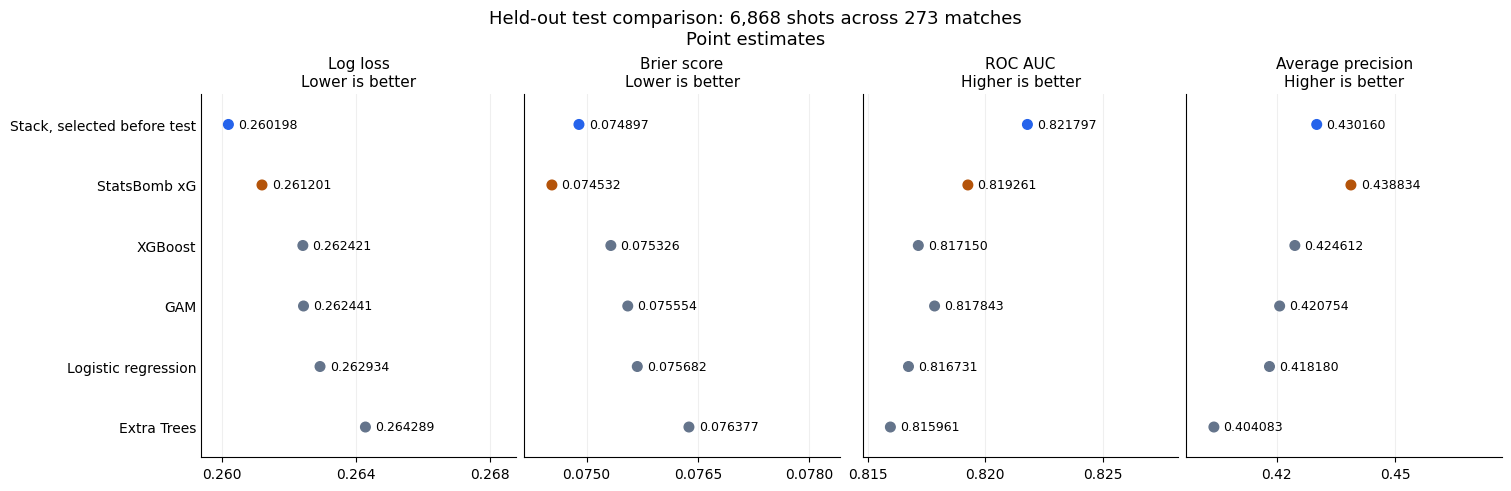

In [87]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plot_model_order = test_metrics["model"].tolist()
plot_labels = {
    "stack_identity": "Stack, selected before test",
    "benchmark_statsbomb_xg": "StatsBomb xG",
    "xgboost": "XGBoost",
    "gam": "GAM",
    "logistic_regression": "Logistic regression",
    "extra_trees": "Extra Trees",
}
plot_colors = [
    "#2563eb" if name == "stack_identity"
    else "#b45309" if name == "benchmark_statsbomb_xg"
    else "#64748b"
    for name in plot_model_order
]
plot_metrics = test_metrics.set_index("model").loc[plot_model_order]
metric_panels = [
    ("log_loss", "Log loss\nLower is better"),
    ("brier_score", "Brier score\nLower is better"),
    ("roc_auc", "ROC AUC\nHigher is better"),
    ("average_precision", "Average precision\nHigher is better"),
]

comparison_fig, comparison_axes = plt.subplots(
    1, 4, figsize=(15, 4.8), sharey=True, layout="constrained"
)
for ax, (metric, title) in zip(comparison_axes, metric_panels):
    values = plot_metrics[metric].to_numpy()
    positions = np.arange(len(values))
    span = max(float(np.ptp(values)), 1e-6)
    ax.scatter(values, positions, c=plot_colors, s=48, zorder=3)
    for value, position in zip(values, positions):
        ax.annotate(
            f"{value:.6f}", (value, position),
            xytext=(7, 0), textcoords="offset points",
            va="center", fontsize=9,
        )
    ax.set_xlim(values.min() - 0.2 * span, values.max() + 1.1 * span)
    ax.set_title(title, fontsize=11)
    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.grid(axis="x", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0)

comparison_axes[0].set_yticks(
    np.arange(len(plot_model_order)),
    [plot_labels[name] for name in plot_model_order],
)
comparison_axes[0].set_ylim(len(plot_model_order) - 0.5, -0.5)
comparison_fig.suptitle(
    "Held-out test comparison: 6,868 shots across 273 matches\nPoint estimates",
    fontsize=13,
)
save_project_artifact(
    final_relative / "test_model_comparison.png",
    lambda path: comparison_fig.savefig(
        path, dpi=200, bbox_inches="tight", facecolor="white"
    ),
)
plt.show()
plt.close(comparison_fig)

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_calibration_bins.parquet
Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_calibration.png


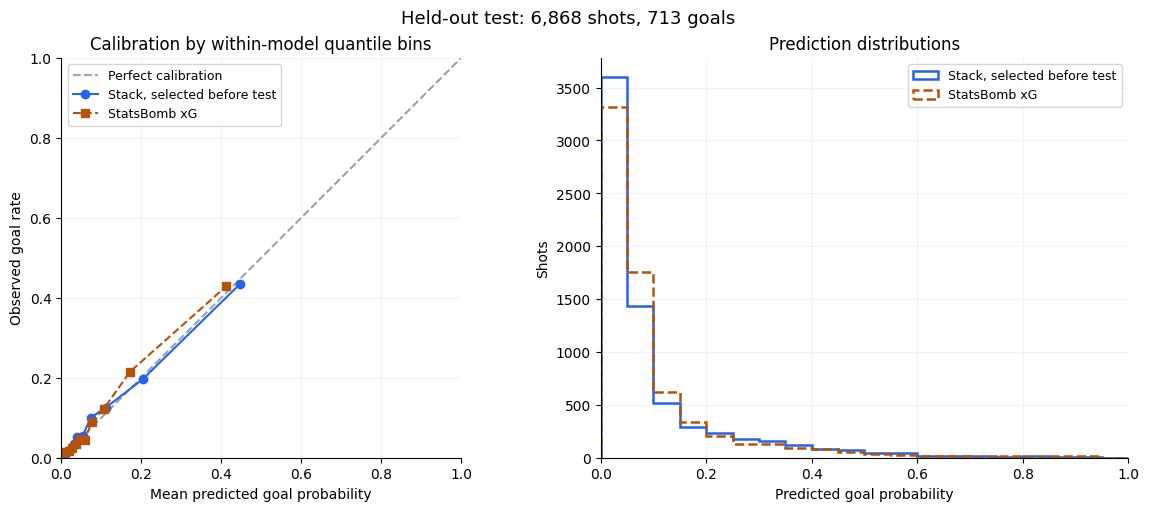

                        shots  goals  expected_goals
model                                               
benchmark_statsbomb_xg   6868    713         663.261
stack_identity           6868    713         692.447


In [88]:
calibration_plot_models = ["stack_identity", "benchmark_statsbomb_xg"]
calibration_parts = []

for name in calibration_plot_models:
    probabilities = test_evaluation_data[name].to_numpy(dtype=float)
    bin_input = pd.DataFrame({
        "bin": pd.qcut(probabilities, q=10, duplicates="drop"),
        "predicted_xg": probabilities,
        "is_goal": test_target,
    })
    grouped = bin_input.groupby("bin", observed=True, sort=True).agg(
        shots=("is_goal", "size"),
        goals=("is_goal", "sum"),
        expected_goals=("predicted_xg", "sum"),
        mean_predicted=("predicted_xg", "mean"),
        observed_goal_rate=("is_goal", "mean"),
        minimum_prediction=("predicted_xg", "min"),
        maximum_prediction=("predicted_xg", "max"),
    ).reset_index(drop=True)
    assert grouped["shots"].sum() == len(test_target)
    assert grouped["goals"].sum() == test_target.sum()
    grouped.insert(0, "model", name)
    grouped.insert(1, "bin_number", np.arange(1, len(grouped) + 1))
    calibration_parts.append(grouped)

test_calibration_bins = pd.concat(calibration_parts, ignore_index=True)
calibration_fig, calibration_axes = plt.subplots(
    1, 2, figsize=(11.5, 5), layout="constrained"
)
calibration_axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")

for name, color, marker, linestyle in [
    ("stack_identity", "#2563eb", "o", "-"),
    ("benchmark_statsbomb_xg", "#b45309", "s", "--"),
]:
    bins = test_calibration_bins.loc[test_calibration_bins["model"].eq(name)]
    calibration_axes[0].plot(
        bins["mean_predicted"], bins["observed_goal_rate"],
        marker=marker, linestyle=linestyle, color=color,
        label=plot_labels[name],
    )
    calibration_axes[1].hist(
        test_evaluation_data[name], bins=np.linspace(0, 1, 21),
        histtype="step", linewidth=1.8, linestyle=linestyle,
        color=color, label=plot_labels[name],
    )

calibration_axes[0].set(
    xlabel="Mean predicted goal probability", ylabel="Observed goal rate",
    xlim=(0, 1), ylim=(0, 1), title="Calibration by within-model quantile bins",
)
calibration_axes[0].set_aspect("equal", adjustable="box")
calibration_axes[1].set(
    xlabel="Predicted goal probability", ylabel="Shots",
    xlim=(0, 1), title="Prediction distributions",
)
for ax in calibration_axes:
    ax.legend(fontsize=9)
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)

calibration_fig.suptitle("Held-out test: 6,868 shots, 713 goals", fontsize=13)
save_project_artifact(
    final_relative / "test_calibration_bins.parquet",
    lambda path: test_calibration_bins.to_parquet(path, index=False),
)
save_project_artifact(
    final_relative / "test_calibration.png",
    lambda path: calibration_fig.savefig(
        path, dpi=200, bbox_inches="tight", facecolor="white"
    ),
)
plt.show()
plt.close(calibration_fig)

print(test_calibration_bins.groupby("model")[
    ["shots", "goals", "expected_goals"]
].sum().round(3).to_string())

In [89]:
evaluation_filenames = [
    "frozen_manifest.json",
    "test_model_predictions.parquet",
    "test_evaluation_predictions.parquet",
    "test_metrics.parquet",
    "test_paired_comparison.parquet",
    "test_model_comparison.png",
    "test_calibration_bins.parquet",
    "test_calibration.png",
]
evaluation_artifacts = {
    name: (final_relative / name).as_posix()
    for name in evaluation_filenames
}
evaluation_file_hashes = {}
for relative in evaluation_artifacts.values():
    hashes = []
    for root in [PROJECT_DIR, DRIVE_PROJECT_DIR]:
        with (root / relative).open("rb") as stream:
            hashes.append(hashlib.file_digest(stream, "sha256").hexdigest())
    assert hashes[0] == hashes[1], f"Local/Drive mismatch: {relative}"
    evaluation_file_hashes[relative] = hashes[0]

completed_at = datetime.now(timezone.utc).isoformat()
test_result_relative = final_relative / "test_result.json"
test_result = {
    "status": "complete",
    "completed_at_utc": completed_at,
    "selected_before_test": frozen_manifest["selected_model"],
    "frozen_manifest_file": manifest_relative.as_posix(),
    "frozen_manifest_sha256": evaluation_file_hashes[manifest_relative.as_posix()],
    "test_scope": {
        "shots": len(test_target),
        "matches": len(test_match_ids),
        "goals": int(test_target.sum()),
        "first_match_date": str(test_match_dates.min().date()),
        "last_match_date": str(test_match_dates.max().date()),
    },
    "benchmark_coverage": {
        "valid": int(benchmark_valid.sum()),
        "missing": int(benchmark_missing.sum()),
        "invalid": int(benchmark_invalid.sum()),
    },
    "metrics": test_metrics.to_dict(orient="records"),
    "paired_comparison_method": (
        "Paired match bootstrap; percentile 95% intervals; pooled per-shot losses."
    ),
    "paired_comparison": test_paired_comparison.to_dict(orient="records"),
    "calibration_totals": test_calibration_bins.groupby("model")[
        ["shots", "goals", "expected_goals"]
    ].sum().reset_index().to_dict(orient="records"),
    "conclusion": (
        "The frozen stack has the lowest test log loss and highest ROC AUC. "
        "StatsBomb xG has the lowest Brier score and highest average precision. "
        "Both paired confidence intervals include zero; these results do not "
        "establish a clear advantage between the stack and StatsBomb xG."
    ),
    "artifacts": evaluation_artifacts,
    "artifact_sha256": evaluation_file_hashes,
}
save_project_artifact(
    test_result_relative,
    lambda path: path.write_text(
        json.dumps(test_result, indent=2, allow_nan=False), encoding="utf-8"
    ),
)

modelling_config = json.loads((PROJECT_DIR / "modelling_config.json").read_text())
modelling_config["model_selection"]["status"] = "test_evaluated"
modelling_config["test_evaluation"] = {
    "status": "complete",
    "completed_at_utc": completed_at,
    "selected_model": frozen_manifest["selected_model"],
    "frozen_manifest_file": manifest_relative.as_posix(),
    "result_file": test_result_relative.as_posix(),
}
modelling_config["updated_at_utc"] = completed_at
save_project_artifact(
    "modelling_config.json",
    lambda path: path.write_text(
        json.dumps(modelling_config, indent=2, allow_nan=False), encoding="utf-8"
    ),
)
assert json.loads(
    (DRIVE_PROJECT_DIR / test_result_relative).read_text()
)["status"] == "complete"

print("Final evaluation complete.")
print(f"Verified {len(evaluation_file_hashes)} evaluation files against Drive copies.")
print("Summary:", test_result_relative)
print("Selected model remains:", frozen_manifest["selected_model"])

Backed up: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_result.json
Backed up: modelling_config.json
Final evaluation complete.
Verified 8 evaluation files against Drive copies.
Summary: models/3bfbffe1de5750ebd47d770be0bb924a10cde54f/final_evaluation/test_result.json
Selected model remains: stack_identity
